In [1]:
# ============================================================
# Block 1 : Install Required Libraries
# ============================================================

# EEG Processing
!pip -q install mne antropy pywavelets wfdb

# Machine Learning
!pip -q install xgboost lightgbm shap

# Utilities
!pip -q install tqdm joblib

print("=" * 70)
print("All Required Libraries Installed Successfully")
print("=" * 70)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 1.5 MB/s eta 0:00:00a 0:00:01
All Required Libraries Installed Successfully


In [2]:
#===========================================================
# Block 2 : Import Required Libraries
# ============================================================

# -----------------------------
# Standard Libraries
# -----------------------------
import os
import gc
import random
import warnings
from pathlib import Path
from collections import Counter

# -----------------------------
# Numerical Computing
# -----------------------------
import numpy as np
import pandas as pd

# -----------------------------
# Visualization
# -----------------------------
import matplotlib.pyplot as plt

# -----------------------------
# EEG Processing
# -----------------------------
import mne
import antropy as ant
import pywt

from scipy.signal import welch
from scipy.stats import skew, kurtosis

# -----------------------------
# Machine Learning
# -----------------------------
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.ensemble import (
    RandomForestClassifier,
    VotingClassifier
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# -----------------------------
# Explainability
# -----------------------------
import shap

# -----------------------------
# Utilities
# -----------------------------
from tqdm.auto import tqdm
import joblib

# -----------------------------
# Settings
# -----------------------------
warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (8,5)
plt.rcParams["font.size"] = 12

print("="*70)
print("All Libraries Imported Successfully")
print("="*70)

All Libraries Imported Successfully


In [3]:
#============================================================
# Block 3 : Environment Setup & Reproducibility
# ============================================================

# ------------------------------------------------------------
# Random Seed
# ------------------------------------------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# ------------------------------------------------------------
# MNE Settings
# ------------------------------------------------------------
mne.set_log_level("ERROR")

# ------------------------------------------------------------
# Pandas Display
# ------------------------------------------------------------
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 20)
pd.set_option("display.precision", 4)

# ------------------------------------------------------------
# System Information
# ------------------------------------------------------------
print("=" * 70)
print("Environment Configuration")
print("=" * 70)

print(f"Random Seed      : {SEED}")
print(f"NumPy Version    : {np.__version__}")
print(f"Pandas Version   : {pd.__version__}")
print(f"MNE Version      : {mne.__version__}")

# ------------------------------------------------------------
# CPU Information
# ------------------------------------------------------------
cpu_count = os.cpu_count()

print(f"CPU Cores        : {cpu_count}")

print("=" * 70)
print("Environment Ready")
print("=" * 70)


Environment Configuration
Random Seed      : 42
NumPy Version    : 2.0.2
Pandas Version   : 2.3.3
MNE Version      : 1.12.1
CPU Cores        : 4
Environment Ready


In [4]:
#============================================================
# Block 4 : Configuration & Dataset Paths
# ============================================================

from pathlib import Path

class CFG:

    # =========================================================
    # Random Seed
    # =========================================================
    SEED = 42

    # =========================================================
    # CHB-MIT Processed Dataset
    # =========================================================
    CHB_PATH = Path(
        "/kaggle/input/datasets/masahirogotoh/mit-chb-processed"
    )

    CHB_SIGNAL_FILE = CHB_PATH / "signal_samples.npy"
    CHB_LABEL_FILE  = CHB_PATH / "is_sz.npy"

    # =========================================================
    # TUH EEG Artifact Dataset
    # =========================================================
    TUH_PATH = Path(
        "/kaggle/input/datasets/mohammadashrafshaik/tuh-eeg-artifact/tuh_eeg_artifact"
    )

    TUH_EDF_PATH = TUH_PATH / "edf"

    # =========================================================
    # Output Directory
    # =========================================================
    OUTPUT_PATH = Path("/kaggle/working")

    # =========================================================
    # EEG Parameters
    # =========================================================
    TARGET_SFREQ = 250

    WINDOW_SEC = 2

    WINDOW_OVERLAP = 0.50

    # =========================================================
    # Major Artifact Classes
    # =========================================================
    MAJOR_ARTIFACTS = [
        "eyem",
        "musc",
        "elec",
        "chew"
    ]

    # =========================================================
    # Sampling Strategy
    # =========================================================
    MAX_WINDOWS_PER_ARTIFACT = 500

    # =========================================================
    # Machine Learning
    # =========================================================
    TEST_SIZE = 0.20

    VALID_SIZE = 0.20

    RANDOM_STATE = 42


# ------------------------------------------------------------
# Create Output Directory
# ------------------------------------------------------------

CFG.OUTPUT_PATH.mkdir(exist_ok=True)

# ------------------------------------------------------------
# Verify Dataset
# ------------------------------------------------------------

print("=" * 70)
print("Configuration Summary")
print("=" * 70)

print(f"CHB Dataset Exists : {CFG.CHB_PATH.exists()}")
print(f"TUH Dataset Exists : {CFG.TUH_PATH.exists()}")

print(f"\nSampling Rate      : {CFG.TARGET_SFREQ} Hz")
print(f"Window Length      : {CFG.WINDOW_SEC} sec")
print(f"Window Overlap     : {CFG.WINDOW_OVERLAP}")

print(f"\nMajor Artifacts")

for a in CFG.MAJOR_ARTIFACTS:
    print("-", a)

print(f"\nMax Windows/Class  : {CFG.MAX_WINDOWS_PER_ARTIFACT}")

print(f"\nOutput Directory")

print(CFG.OUTPUT_PATH)

print("=" * 70)


Configuration Summary
CHB Dataset Exists : True
TUH Dataset Exists : True

Sampling Rate      : 250 Hz
Window Length      : 2 sec
Window Overlap     : 0.5

Major Artifacts
- eyem
- musc
- elec
- chew

Max Windows/Class  : 500

Output Directory
/kaggle/working


In [5]:
# ============================================================
# Block 5 : Dataset Discovery & Verification
# ============================================================

print("=" * 70)
print("Dataset Discovery")
print("=" * 70)

# ------------------------------------------------------------
# CHB Dataset Files
# ------------------------------------------------------------

print("\nCHB-MIT Processed Dataset")

chb_files = sorted(CFG.CHB_PATH.glob("*"))

for file in chb_files:
    print(file.name)

# ------------------------------------------------------------
# TUH EDF Files
# ------------------------------------------------------------

edf_files = sorted(CFG.TUH_EDF_PATH.rglob("*.edf"))

# ------------------------------------------------------------
# TUH Annotation Files
# ------------------------------------------------------------

csv_files = sorted(CFG.TUH_EDF_PATH.rglob("*.csv"))

print("\nTUH EEG Artifact Dataset")

print(f"EDF Files        : {len(edf_files)}")
print(f"Annotation Files : {len(csv_files)}")

# ------------------------------------------------------------
# Verify Dataset
# ------------------------------------------------------------

assert len(edf_files) > 0, "No EDF files found."
assert len(csv_files) > 0, "No Annotation CSV files found."

print("\nDataset Verification Passed")

print("=" * 70)


Dataset Discovery

CHB-MIT Processed Dataset
CHB_MIT_sz_detec_demo.h5
is_sz.npy
signal_samples.npy

TUH EEG Artifact Dataset
EDF Files        : 310
Annotation Files : 352

Dataset Verification Passed


In [6]:
# ============================================================
# Block 6 : Load & Inspect CHB-MIT Dataset
# ============================================================

print("=" * 70)
print("Loading CHB-MIT Processed Dataset")
print("=" * 70)

# ------------------------------------------------------------
# Memory-Mapped Loading
# ------------------------------------------------------------

chb_signals = np.load(
    CFG.CHB_SIGNAL_FILE,
    mmap_mode="r"
)

chb_labels = np.load(
    CFG.CHB_LABEL_FILE
)

# ------------------------------------------------------------
# Dataset Information
# ------------------------------------------------------------

num_samples = chb_signals.shape[0]
num_channels = chb_signals.shape[1]
num_points = chb_signals.shape[2]

print("\nDataset Summary")
print("-" * 70)

print(f"Signal Shape        : {chb_signals.shape}")
print(f"Label Shape         : {chb_labels.shape}")

print(f"\nTotal Samples       : {num_samples:,}")
print(f"Channels            : {num_channels}")
print(f"Samples per Window  : {num_points}")

# ------------------------------------------------------------
# Label Distribution
# ------------------------------------------------------------

print("\nLabel Distribution")
print("-" * 70)

label_counts = Counter(chb_labels)

for label, count in sorted(label_counts.items()):

    class_name = "Seizure" if bool(label) else "Non-Seizure"

    percentage = (count / num_samples) * 100

    print(f"{class_name:<15}: {count:>5} ({percentage:.2f}%)")

# ------------------------------------------------------------
# Data Quality
# ------------------------------------------------------------

print("\nData Quality")
print("-" * 70)

sample = np.asarray(chb_signals[:100])

print(f"Contains NaN        : {np.isnan(sample).any()}")
print(f"Contains Inf        : {np.isinf(sample).any()}")

# ------------------------------------------------------------
# Example Sample
# ------------------------------------------------------------

print("\nExample Sample")
print("-" * 70)

print(f"Window Shape        : {chb_signals[0].shape}")
print(f"Label               : {'Seizure' if chb_labels[0] else 'Non-Seizure'}")

print("\n" + "=" * 70)
print("CHB Dataset Ready")
print("=" * 70)


Loading CHB-MIT Processed Dataset

Dataset Summary
----------------------------------------------------------------------
Signal Shape        : (9505, 18, 2048)
Label Shape         : (9505,)

Total Samples       : 9,505
Channels            : 18
Samples per Window  : 2048

Label Distribution
----------------------------------------------------------------------
Non-Seizure    :  6924 (72.85%)
Seizure        :  2581 (27.15%)

Data Quality
----------------------------------------------------------------------
Contains NaN        : False
Contains Inf        : False

Example Sample
----------------------------------------------------------------------
Window Shape        : (18, 2048)
Label               : Non-Seizure

CHB Dataset Ready


In [7]:
# ============================================================
# Block 7 : Build TUH Master Manifest
# ============================================================

print("=" * 70)
print("Building TUH Master Manifest")
print("=" * 70)

records = []

# ------------------------------------------------------------
# Find all EDF files
# ------------------------------------------------------------
edf_files = sorted(CFG.TUH_EDF_PATH.rglob("*.edf"))

for edf in tqdm(edf_files, desc="Scanning EDF Files"):

    try:

        # ----------------------------------------------------
        # Find corresponding annotation CSV
        # ----------------------------------------------------
        csv_path = edf.with_suffix(".csv")

        if not csv_path.exists():
            continue

        # ----------------------------------------------------
        # Read only EDF header (fast)
        # ----------------------------------------------------
        raw = mne.io.read_raw_edf(
            edf,
            preload=False,
            verbose=False
        )

        duration = raw.n_times / raw.info["sfreq"]

        records.append({

            "record_id": edf.stem,

            "edf_path": str(edf),

            "csv_path": str(csv_path),

            "sampling_rate": raw.info["sfreq"],

            "channels": len(raw.ch_names),

            "duration_sec": round(duration,2)

        })

    except Exception:

        continue

# ------------------------------------------------------------
# Create Manifest
# ------------------------------------------------------------

manifest_df = pd.DataFrame(records)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\nManifest Shape")

print(manifest_df.shape)

print("\nSampling Rates")

print(
    manifest_df["sampling_rate"]
    .value_counts()
    .sort_index()
)

print("\nChannel Distribution")

print(
    manifest_df["channels"]
    .value_counts()
    .sort_index()
)

print("\nDuration Statistics (seconds)")

print(
    manifest_df["duration_sec"]
    .describe()
)

print("\nFirst Five Records")

display(manifest_df.head())

print("\n" + "=" * 70)
print("TUH Master Manifest Ready")
print("=" * 70)


Building TUH Master Manifest


Scanning EDF Files:   0%|          | 0/310 [00:00<?, ?it/s]


Manifest Shape
(310, 6)

Sampling Rates
sampling_rate
250.0     201
256.0      93
400.0       9
512.0       6
1000.0      1
Name: count, dtype: int64

Channel Distribution
channels
27       9
28       5
29      23
30      69
31      12
32       6
33      18
34      39
36     114
41      12
128      3
Name: count, dtype: int64

Duration Statistics (seconds)
count      310.0000
mean      1161.0839
std        811.3895
min         67.0000
25%        601.0000
50%       1208.0000
75%       1326.0000
max      10300.0000
Name: duration_sec, dtype: float64

First Five Records


,record_id,edf_path,csv_path,sampling_rate,channels,duration_sec
0,aaaaaaju_s005_t000,/kaggle/input/datasets/mohammadashrafshaik/tuh...,/kaggle/input/datasets/mohammadashrafshaik/tuh...,250.0,36,1442.0
1,aaaaaaju_s007_t000,/kaggle/input/datasets/mohammadashrafshaik/tuh...,/kaggle/input/datasets/mohammadashrafshaik/tuh...,250.0,30,1244.0
2,aaaaaall_s004_t000,/kaggle/input/datasets/mohammadashrafshaik/tuh...,/kaggle/input/datasets/mohammadashrafshaik/tuh...,250.0,30,1450.0
3,aaaaaarq_s004_t001,/kaggle/input/datasets/mohammadashrafshaik/tuh...,/kaggle/input/datasets/mohammadashrafshaik/tuh...,400.0,32,1239.0
4,aaaaaayg_s002_t001,/kaggle/input/datasets/mohammadashrafshaik/tuh...,/kaggle/input/datasets/mohammadashrafshaik/tuh...,400.0,32,550.0



TUH Master Manifest Ready


In [8]:
# ============================================================
# Block 8 : Unified EEG Preprocessing Engine
# ============================================================

print("=" * 70)
print("Unified EEG Preprocessing Engine")
print("=" * 70)

# ------------------------------------------------------------
# Common EEG Channels
# ------------------------------------------------------------

COMMON_CHANNELS = [
    "EEG FP1-REF",
    "EEG FP2-REF",
    "EEG F3-REF",
    "EEG F4-REF",
    "EEG C3-REF",
    "EEG C4-REF",
    "EEG P3-REF",
    "EEG P4-REF",
    "EEG O1-REF",
    "EEG O2-REF",
    "EEG F7-REF",
    "EEG F8-REF",
    "EEG T3-REF",
    "EEG T4-REF",
    "EEG T5-REF",
    "EEG T6-REF",
    "EEG FZ-REF",
    "EEG CZ-REF"
]

# ------------------------------------------------------------
# EEG Preprocessing Function
# ------------------------------------------------------------

def preprocess_eeg(raw):
    """
    Unified preprocessing for TUH EEG recordings.

    Steps:
    1. Select common EEG channels
    2. Resample to 250 Hz
    3. Band-pass filter (0.5–40 Hz)

    Returns
    -------
    np.ndarray
        Shape = (18, samples)
    """

    raw = raw.copy()

    # Select available channels
    available = [
        ch for ch in COMMON_CHANNELS
        if ch in raw.ch_names
    ]

    if len(available) < 18:
        raise ValueError(
            f"Expected 18 channels, found {len(available)}"
        )

    raw.pick(available)

    # Resample
    if raw.info["sfreq"] != CFG.TARGET_SFREQ:
        raw.resample(CFG.TARGET_SFREQ)

    # Band-pass filter
    raw.filter(
        l_freq=0.5,
        h_freq=40,
        verbose=False
    )

    # Return NumPy array
    return raw.get_data().astype(np.float32)

print("✓ Unified EEG preprocessing engine created.")

Unified EEG Preprocessing Engine
✓ Unified EEG preprocessing engine created.


In [9]:
# ============================================================
# Test Unified Preprocessing
# ============================================================

sample_record = manifest_df.iloc[0]

raw = mne.io.read_raw_edf(
    sample_record.edf_path,
    preload=True,
    verbose=False
)

signal = preprocess_eeg(raw)

print("=" * 70)
print("Preprocessing Test")
print("=" * 70)

print("Signal Shape :", signal.shape)
print("Data Type    :", signal.dtype)
print("Sampling Hz  :", CFG.TARGET_SFREQ)

Preprocessing Test
Signal Shape : (18, 360500)
Data Type    : float32
Sampling Hz  : 250


In [11]:
# ============================================================
# Block 9 : Fast Multi-Domain Feature Extraction
# ============================================================

print("=" * 70)
print("Fast Multi-Domain Feature Extraction")
print("=" * 70)

# ------------------------------------------------------------
# Frequency Bands
# ------------------------------------------------------------

FREQ_BANDS = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta":  (13, 30),
    "gamma": (30, 40)
}

# ------------------------------------------------------------
# Feature Extraction Function
# ------------------------------------------------------------

def extract_features(signal, sfreq=250):
    """
    Extract compact handcrafted EEG features.

    Input
    -----
    signal : ndarray
        Shape -> (18, samples)

    Output
    ------
    dict
    """

    features = {}

    for ch in range(signal.shape[0]):

        x = signal[ch]

        prefix = f"ch{ch+1}"

        # ====================================================
        # Statistical Features
        # ====================================================

        features[f"{prefix}_mean"] = np.mean(x)
        features[f"{prefix}_std"] = np.std(x)
        features[f"{prefix}_var"] = np.var(x)
        features[f"{prefix}_rms"] = np.sqrt(np.mean(x**2))

        # ====================================================
        # Hjorth Parameters
        # ====================================================

        mobility, complexity = ant.hjorth_params(x)

        features[f"{prefix}_mobility"] = mobility
        features[f"{prefix}_complexity"] = complexity

        # ====================================================
        # Power Spectral Density
        # ====================================================

        freqs, psd = welch(
            x,
            fs=sfreq,
            nperseg=min(256, len(x))
        )

        for band, (low, high) in FREQ_BANDS.items():

            idx = (freqs >= low) & (freqs < high)

            features[f"{prefix}_{band}"] = np.sum(psd[idx])

    return features


print("✓ Feature extractor created")

# ------------------------------------------------------------
# Test
# ------------------------------------------------------------

dummy = signal[:, :500]

feature_vector = extract_features(dummy)

print("\nFeature Extraction Test")
print("-" * 50)

print("Feature Type :", type(feature_vector))
print("Total Features :", len(feature_vector))

print("\nFirst 10 Features\n")

for i, (k, v) in enumerate(feature_vector.items()):

    print(f"{k:<25} {v:.6f}")

    if i == 9:
        break


Fast Multi-Domain Feature Extraction
✓ Feature extractor created

Feature Extraction Test
--------------------------------------------------
Feature Type : <class 'dict'>
Total Features : 198

First 10 Features

ch1_mean                  -0.002154
ch1_std                   0.003206
ch1_var                   0.000010
ch1_rms                   0.003863
ch1_mobility              0.056690
ch1_complexity            10.724387
ch1_delta                 0.000003
ch1_theta                 0.000000
ch1_alpha                 0.000000
ch1_beta                  0.000000


In [12]:
# ============================================================
# Block 10 : TUH Artifact Feature Generator
# ============================================================

print("=" * 70)
print("TUH Artifact Feature Generator")
print("=" * 70)

WINDOW_SIZE = CFG.TARGET_SFREQ * CFG.WINDOW_SEC

STEP_SIZE = int(
    WINDOW_SIZE * (1 - CFG.WINDOW_OVERLAP)
)


def tuh_feature_generator(manifest_df):

    # ---------------------------------------------
    # Counter for each artifact
    # ---------------------------------------------
    artifact_counter = {
        art: 0
        for art in CFG.MAJOR_ARTIFACTS
    }

    for row in manifest_df.itertuples(index=False):

        # Stop if all artifacts collected
        if all(
            v >= CFG.MAX_WINDOWS_PER_ARTIFACT
            for v in artifact_counter.values()
        ):
            break

        try:

            # -----------------------------------------
            # Load EEG
            # -----------------------------------------
            raw = mne.io.read_raw_edf(
                row.edf_path,
                preload=True,
                verbose=False
            )

            signal = preprocess_eeg(raw)

            # -----------------------------------------
            # Annotation
            # -----------------------------------------
            ann = pd.read_csv(
                row.csv_path,
                comment="#"
            )

            if ann.empty:
                continue

            # Keep only major artifacts
            ann = ann[
                ann["label"].isin(
                    CFG.MAJOR_ARTIFACTS
                )
            ]

            if ann.empty:
                continue

            # Shuffle annotations
            ann = ann.sample(
                frac=1,
                random_state=CFG.SEED
            )

            for seg in ann.itertuples(index=False):

                label = seg.label

                if artifact_counter[label] >= CFG.MAX_WINDOWS_PER_ARTIFACT:
                    continue

                start = int(
                    seg.start_time * CFG.TARGET_SFREQ
                )

                stop = int(
                    seg.stop_time * CFG.TARGET_SFREQ
                )

                stop = min(
                    stop,
                    signal.shape[1]
                )

                segment = signal[:, start:stop]

                if segment.shape[1] < WINDOW_SIZE:
                    continue

                # Sliding windows
                for i in range(
                    0,
                    segment.shape[1] - WINDOW_SIZE + 1,
                    STEP_SIZE
                ):

                    if artifact_counter[label] >= CFG.MAX_WINDOWS_PER_ARTIFACT:
                        break

                    window = segment[
                        :,
                        i:i+WINDOW_SIZE
                    ]

                    feat = extract_features(window)

                    feat["artifact"] = label

                    yield feat

                    artifact_counter[label] += 1

        except Exception:

            continue

    print("\nGenerator Finished")

    print("\nCollected Windows")

    for k, v in artifact_counter.items():

        print(f"{k:<10}: {v}")


TUH Artifact Feature Generator


In [13]:
# ============================================================
# Block 11 : Validate TUH Feature Generator
# ============================================================

print("=" * 70)
print("Validating TUH Feature Generator")
print("=" * 70)

generator = tuh_feature_generator(manifest_df)

samples = []

# ---------------------------------------------
# Collect first 20 samples
# ---------------------------------------------
for _ in range(20):

    try:
        samples.append(next(generator))
    except StopIteration:
        break

# ---------------------------------------------
# Convert to DataFrame
# ---------------------------------------------
sample_df = pd.DataFrame(samples)

print("\nSample Dataset Shape")
print(sample_df.shape)

print("\nArtifact Distribution")
print(sample_df["artifact"].value_counts())

print("\nFirst Five Samples")
display(sample_df.head())

print("\nFeature Count")

feature_columns = [
    c for c in sample_df.columns
    if c != "artifact"
]

print(len(feature_columns))

print("\nGenerator Validation Completed")

print("=" * 70)


Validating TUH Feature Generator

Sample Dataset Shape
(20, 199)

Artifact Distribution
artifact
eyem    20
Name: count, dtype: int64

First Five Samples


,ch1_mean,ch1_std,ch1_var,ch1_rms,ch1_mobility,ch1_complexity,ch1_delta,ch1_theta,ch1_alpha,ch1_beta,ch1_gamma,ch2_mean,ch2_std,ch2_var,ch2_rms,ch2_mobility,ch2_complexity,ch2_delta,ch2_theta,ch2_alpha,ch2_beta,ch2_gamma,ch3_mean,ch3_std,ch3_var,ch3_rms,ch3_mobility,ch3_complexity,ch3_delta,ch3_theta,ch3_alpha,ch3_beta,ch3_gamma,ch4_mean,ch4_std,ch4_var,ch4_rms,ch4_mobility,ch4_complexity,ch4_delta,ch4_theta,ch4_alpha,ch4_beta,ch4_gamma,ch5_mean,ch5_std,ch5_var,ch5_rms,ch5_mobility,ch5_complexity,...,ch14_delta,ch14_theta,ch14_alpha,ch14_beta,ch14_gamma,ch15_mean,ch15_std,ch15_var,ch15_rms,ch15_mobility,ch15_complexity,ch15_delta,ch15_theta,ch15_alpha,ch15_beta,ch15_gamma,ch16_mean,ch16_std,ch16_var,ch16_rms,ch16_mobility,ch16_complexity,ch16_delta,ch16_theta,ch16_alpha,ch16_beta,ch16_gamma,ch17_mean,ch17_std,ch17_var,ch17_rms,ch17_mobility,ch17_complexity,ch17_delta,ch17_theta,ch17_alpha,ch17_beta,ch17_gamma,ch18_mean,ch18_std,ch18_var,ch18_rms,ch18_mobility,ch18_complexity,ch18_delta,ch18_theta,ch18_alpha,ch18_beta,ch18_gamma,artifact
0,8.7714e-05,2.4672e-04,6.0869e-08,2.6184e-04,0.0364,17.2022,5.5596e-08,6.7574e-10,3.2758e-11,3.2149e-11,6.3257e-11,7.5280e-05,2.0613e-04,4.2489e-08,2.1944e-04,0.0421,17.0215,3.9029e-08,4.8366e-10,2.4620e-11,3.1663e-11,5.8877e-11,3.0157e-05,7.8008e-05,6.0852e-09,8.3634e-05,0.0367,15.1129,5.7792e-09,7.3432e-11,6.9936e-12,6.3696e-12,4.8846e-12,2.1858e-05,5.8609e-05,3.4350e-09,6.2552e-05,0.0488,13.0452,3.6419e-09,6.1363e-11,6.8342e-12,1.0094e-11,3.6564e-12,1.6420e-05,4.1505e-05,1.7227e-09,4.4635e-05,0.0383,14.0237,...,5.4190e-10,4.5094e-12,3.2583e-12,5.5727e-12,6.4916e-13,3.6282e-06,6.8620e-06,4.7087e-11,7.7621e-06,0.1248,5.2197,4.2137e-11,8.2739e-13,6.6726e-13,1.2761e-12,1.7536e-13,4.1733e-06,1.4632e-05,2.1408e-10,1.5215e-05,0.1113,5.3250,1.4596e-10,5.9512e-12,4.1628e-12,7.3646e-12,4.2494e-13,3.1573e-05,7.6674e-05,5.8790e-09,8.2921e-05,0.0407,15.1829,5.4532e-09,7.7119e-11,8.8316e-12,8.6344e-12,5.8147e-12,1.5669e-05,3.6920e-05,1.3631e-09,4.0107e-05,0.0530,10.8183,1.1440e-09,2.4294e-11,6.4582e-12,8.5157e-12,1.1379e-12,eyem
1,9.2177e-06,8.4699e-05,7.1740e-09,8.5200e-05,0.0448,17.5860,1.3238e-09,4.6537e-12,7.0438e-12,9.2212e-12,6.4233e-12,1.1275e-05,7.2013e-05,5.1859e-09,7.2890e-05,0.0586,13.7719,9.1468e-10,4.6543e-12,8.5834e-12,9.3950e-12,5.8320e-12,5.3821e-06,2.8075e-05,7.8820e-10,2.8586e-05,0.0522,13.3510,1.5623e-10,2.0941e-12,4.9266e-12,2.4952e-12,8.1081e-13,3.0442e-06,1.6580e-05,2.7488e-10,1.6857e-05,0.1055,6.3485,9.5502e-11,5.1382e-12,8.6735e-12,4.6274e-12,1.1289e-12,2.7905e-06,1.6567e-05,2.7448e-10,1.6801e-05,0.0699,9.4279,...,3.8676e-11,3.5856e-12,3.4653e-12,4.3069e-12,6.0566e-13,8.3959e-07,3.6381e-06,1.3236e-11,3.7337e-06,0.2292,2.9531,4.7006e-12,2.5790e-13,3.7058e-12,7.9001e-13,2.9485e-13,-1.2104e-06,7.1510e-06,5.1137e-11,7.2527e-06,0.2130,2.9038,2.6179e-11,7.7631e-12,4.5787e-12,4.5405e-12,5.3399e-13,8.2159e-06,2.9511e-05,8.7091e-10,3.0633e-05,0.0591,11.7069,1.7700e-10,3.2123e-12,6.9118e-12,4.2206e-12,1.2971e-12,1.2000e-06,1.7344e-05,3.0080e-10,1.7385e-05,0.0904,6.8907,1.1938e-10,3.6198e-12,4.4458e-12,6.3940e-12,8.9428e-13,eyem
2,-9.0660e-06,2.3442e-04,5.4952e-08,2.3459e-04,0.0386,4.0444,4.6993e-09,1.3941e-11,4.1297e-12,2.8327e-12,4.2819e-13,-3.4901e-06,2.0075e-04,4.0299e-08,2.0078e-04,0.0403,4.5734,2.6711e-09,1.2796e-11,8.7747e-12,2.7009e-12,5.4840e-13,-4.1472e-06,7.6501e-05,5.8525e-09,7.6614e-05,0.0411,7.6461,5.7523e-10,6.2513e-12,1.5151e-12,2.0211e-12,4.9961e-13,-1.1120e-06,6.6650e-05,4.4423e-09,6.6660e-05,0.0487,8.7749,2.8290e-10,9.2057e-12,4.5337e-12,4.0872e-12,1.0056e-12,-1.5762e-06,3.5337e-05,1.2487e-09,3.5372e-05,0.0474,9.6231,...,1.5134e-10,1.0368e-11,8.0947e-12,3.3751e-12,4.6143e-13,3.0351e-07,7.6574e-06,5.8636e-11,7.6634e-06,0.1278,5.2838,4.2265e-12,3.2141e-13,9.2517e-13,9.7435e-13,2.2134e-13,4.8987e-07,1.4601e-05,2.1319e-10,1.4609e-05,0.1143,5.0100,8.4257e-11,3.9247e-12,5.4146e-12,3.1462e-12,5.1923e-13,-1.9002e-06,7.5751e-05,5.7382e-09,7.5775e-05,0.0418,6.7875,4.2066e-10,5.0734e


Feature Count
198

Generator Validation Completed


In [14]:
# ============================================================
# Block 12 : Generate TUH Feature Dataset
# ============================================================

print("=" * 70)
print("Generating TUH Feature Dataset")
print("=" * 70)

OUTPUT_FILE = CFG.OUTPUT_PATH / "tuh_features.csv"

# Remove old file if it exists
if OUTPUT_FILE.exists():
    OUTPUT_FILE.unlink()

BATCH_SIZE = 500

buffer = []

total_samples = 0

generator = tuh_feature_generator(manifest_df)

for sample in tqdm(generator, desc="Generating Features"):

    buffer.append(sample)
    total_samples += 1

    if len(buffer) >= BATCH_SIZE:

        pd.DataFrame(buffer).to_csv(
            OUTPUT_FILE,
            mode="a",
            header=not OUTPUT_FILE.exists(),
            index=False
        )

        buffer.clear()

# Save remaining samples
if buffer:

    pd.DataFrame(buffer).to_csv(
        OUTPUT_FILE,
        mode="a",
        header=not OUTPUT_FILE.exists(),
        index=False
    )

print("\n" + "=" * 70)
print("TUH Feature Dataset Generated")
print("=" * 70)

print(f"Output File   : {OUTPUT_FILE}")
print(f"Total Samples : {total_samples}")


Generating TUH Feature Dataset


Generating Features: 0it [00:00, ?it/s]


Generator Finished

Collected Windows
eyem      : 500
musc      : 500
elec      : 500
chew      : 500

TUH Feature Dataset Generated
Output File   : /kaggle/working/tuh_features.csv
Total Samples : 2000


In [15]:
# ============================================================
# Block 13 : Verify TUH Feature Dataset
# ============================================================

tuh_df = pd.read_csv(CFG.OUTPUT_PATH / "tuh_features.csv")

print("=" * 70)
print("TUH Feature Dataset Summary")
print("=" * 70)

print(f"Dataset Shape : {tuh_df.shape}")

print("\nArtifact Distribution")
print(tuh_df["artifact"].value_counts())

print("\nMissing Values")
print(tuh_df.isna().sum().sum())

display(tuh_df.head())


TUH Feature Dataset Summary
Dataset Shape : (2000, 199)

Artifact Distribution
artifact
eyem    500
elec    500
musc    500
chew    500
Name: count, dtype: int64

Missing Values
0


,ch1_mean,ch1_std,ch1_var,ch1_rms,ch1_mobility,ch1_complexity,ch1_delta,ch1_theta,ch1_alpha,ch1_beta,ch1_gamma,ch2_mean,ch2_std,ch2_var,ch2_rms,ch2_mobility,ch2_complexity,ch2_delta,ch2_theta,ch2_alpha,ch2_beta,ch2_gamma,ch3_mean,ch3_std,ch3_var,ch3_rms,ch3_mobility,ch3_complexity,ch3_delta,ch3_theta,ch3_alpha,ch3_beta,ch3_gamma,ch4_mean,ch4_std,ch4_var,ch4_rms,ch4_mobility,ch4_complexity,ch4_delta,ch4_theta,ch4_alpha,ch4_beta,ch4_gamma,ch5_mean,ch5_std,ch5_var,ch5_rms,ch5_mobility,ch5_complexity,...,ch14_delta,ch14_theta,ch14_alpha,ch14_beta,ch14_gamma,ch15_mean,ch15_std,ch15_var,ch15_rms,ch15_mobility,ch15_complexity,ch15_delta,ch15_theta,ch15_alpha,ch15_beta,ch15_gamma,ch16_mean,ch16_std,ch16_var,ch16_rms,ch16_mobility,ch16_complexity,ch16_delta,ch16_theta,ch16_alpha,ch16_beta,ch16_gamma,ch17_mean,ch17_std,ch17_var,ch17_rms,ch17_mobility,ch17_complexity,ch17_delta,ch17_theta,ch17_alpha,ch17_beta,ch17_gamma,ch18_mean,ch18_std,ch18_var,ch18_rms,ch18_mobility,ch18_complexity,ch18_delta,ch18_theta,ch18_alpha,ch18_beta,ch18_gamma,artifact
0,8.7714e-05,2.4672e-04,6.0869e-08,2.6184e-04,0.0364,17.2022,5.5596e-08,6.7574e-10,3.2758e-11,3.2149e-11,6.3257e-11,7.5280e-05,2.0613e-04,4.2489e-08,2.1944e-04,0.0421,17.0215,3.9029e-08,4.8366e-10,2.4620e-11,3.1663e-11,5.8877e-11,3.0157e-05,7.8008e-05,6.0852e-09,8.3634e-05,0.0367,15.1129,5.7792e-09,7.3432e-11,6.9936e-12,6.3696e-12,4.8846e-12,2.1858e-05,5.8609e-05,3.4350e-09,6.2552e-05,0.0488,13.0452,3.6419e-09,6.1363e-11,6.8342e-12,1.0094e-11,3.6564e-12,1.6420e-05,4.1505e-05,1.7227e-09,4.4635e-05,0.0383,14.0237,...,5.4190e-10,4.5094e-12,3.2583e-12,5.5727e-12,6.4916e-13,3.6282e-06,6.8620e-06,4.7087e-11,7.7621e-06,0.1248,5.2197,4.2137e-11,8.2739e-13,6.6726e-13,1.2761e-12,1.7536e-13,4.1733e-06,1.4632e-05,2.1408e-10,1.5215e-05,0.1113,5.3250,1.4596e-10,5.9512e-12,4.1628e-12,7.3646e-12,4.2494e-13,3.1573e-05,7.6674e-05,5.8790e-09,8.2921e-05,0.0407,15.1829,5.4532e-09,7.7119e-11,8.8316e-12,8.6344e-12,5.8147e-12,1.5669e-05,3.6920e-05,1.3631e-09,4.0107e-05,0.0530,10.8183,1.1440e-09,2.4294e-11,6.4582e-12,8.5157e-12,1.1379e-12,eyem
1,9.2177e-06,8.4699e-05,7.1740e-09,8.5200e-05,0.0448,17.5860,1.3238e-09,4.6537e-12,7.0438e-12,9.2212e-12,6.4233e-12,1.1275e-05,7.2013e-05,5.1859e-09,7.2890e-05,0.0586,13.7719,9.1468e-10,4.6543e-12,8.5834e-12,9.3950e-12,5.8320e-12,5.3821e-06,2.8075e-05,7.8820e-10,2.8586e-05,0.0522,13.3510,1.5624e-10,2.0941e-12,4.9266e-12,2.4952e-12,8.1081e-13,3.0442e-06,1.6580e-05,2.7488e-10,1.6857e-05,0.1055,6.3485,9.5502e-11,5.1382e-12,8.6735e-12,4.6274e-12,1.1289e-12,2.7905e-06,1.6567e-05,2.7448e-10,1.6801e-05,0.0699,9.4279,...,3.8676e-11,3.5856e-12,3.4653e-12,4.3069e-12,6.0566e-13,8.3959e-07,3.6381e-06,1.3236e-11,3.7337e-06,0.2292,2.9531,4.7006e-12,2.5790e-13,3.7058e-12,7.9001e-13,2.9485e-13,-1.2104e-06,7.1510e-06,5.1137e-11,7.2527e-06,0.2130,2.9038,2.6179e-11,7.7631e-12,4.5787e-12,4.5405e-12,5.3399e-13,8.2159e-06,2.9511e-05,8.7091e-10,3.0633e-05,0.0591,11.7069,1.7700e-10,3.2123e-12,6.9118e-12,4.2206e-12,1.2971e-12,1.2000e-06,1.7344e-05,3.0080e-10,1.7385e-05,0.0904,6.8907,1.1938e-10,3.6198e-12,4.4458e-12,6.3940e-12,8.9428e-13,eyem
2,-9.0660e-06,2.3442e-04,5.4952e-08,2.3459e-04,0.0386,4.0444,4.6993e-09,1.3941e-11,4.1297e-12,2.8327e-12,4.2819e-13,-3.4901e-06,2.0075e-04,4.0299e-08,2.0078e-04,0.0403,4.5734,2.6711e-09,1.2796e-11,8.7747e-12,2.7009e-12,5.4840e-13,-4.1472e-06,7.6501e-05,5.8525e-09,7.6614e-05,0.0411,7.6461,5.7523e-10,6.2513e-12,1.5151e-12,2.0211e-12,4.9961e-13,-1.1120e-06,6.6650e-05,4.4423e-09,6.6660e-05,0.0487,8.7749,2.8290e-10,9.2057e-12,4.5337e-12,4.0872e-12,1.0056e-12,-1.5762e-06,3.5337e-05,1.2487e-09,3.5372e-05,0.0474,9.6231,...,1.5134e-10,1.0368e-11,8.0947e-12,3.3751e-12,4.6143e-13,3.0351e-07,7.6574e-06,5.8636e-11,7.6634e-06,0.1278,5.2838,4.2265e-12,3.2141e-13,9.2517e-13,9.7435e-13,2.2134e-13,4.8987e-07,1.4601e-05,2.1319e-10,1.4609e-05,0.1143,5.0100,8.4257e-11,3.9247e-12,5.4146e-12,3.1462e-12,5.1923e-13,-1.9002e-06,7.5751e-05,5.7382e-09,7.5775e-05,0.0418,6.7875,4.2066e-10,5.0734e

In [16]:
# ============================================================
# Block 14 : Artifact Stability Analysis
# ============================================================

print("=" * 70)
print("Artifact Stability Analysis")
print("=" * 70)

# ------------------------------------------------------------
# Load TUH Feature Dataset
# ------------------------------------------------------------
tuh_df = pd.read_csv(CFG.OUTPUT_PATH / "tuh_features.csv")

feature_cols = [
    c for c in tuh_df.columns
    if c != "artifact"
]

# ------------------------------------------------------------
# Calculate Stability Score
# ------------------------------------------------------------
stability_scores = []

for feature in feature_cols:

    # Mean feature value for each artifact
    means = (
        tuh_df
        .groupby("artifact")[feature]
        .mean()
    )

    # Standard deviation across artifact means
    score = means.std()

    stability_scores.append({
        "feature": feature,
        "stability_score": score
    })

# ------------------------------------------------------------
# Create Stability DataFrame
# ------------------------------------------------------------
stability_df = pd.DataFrame(stability_scores)

# Smaller score = more stable
stability_df = stability_df.sort_values(
    by="stability_score",
    ascending=True
).reset_index(drop=True)

# ------------------------------------------------------------
# Show Results
# ------------------------------------------------------------
print("\nMost Stable Features\n")

display(stability_df.head(20))

print("\nLeast Stable Features\n")

display(stability_df.tail(20))

print("=" * 70)
print("Artifact Stability Analysis Completed")
print("=" * 70)


Artifact Stability Analysis

Most Stable Features



,feature,stability_score
0,ch14_delta,9.9981e-11
1,ch5_gamma,1.1625e-10
2,ch16_gamma,1.1725e-10
3,ch10_gamma,1.1834e-10
4,ch17_gamma,1.2181e-10
5,ch9_gamma,1.2253e-10
6,ch18_gamma,1.2905e-10
7,ch6_gamma,1.3056e-10
8,ch8_gamma,1.3394e-10
9,ch3_gamma,1.3618e-10



Least Stable Features



,feature,stability_score
178,ch4_mobility,0.1367
179,ch6_mobility,0.1446
180,ch16_complexity,0.7637
181,ch8_complexity,0.8118
182,ch15_complexity,0.9870
183,ch14_complexity,1.0738
184,ch6_complexity,1.0795
185,ch18_complexity,1.1781
186,ch7_complexity,1.2889
187,ch10_complexity,1.3211


Artifact Stability Analysis Completed


In [17]:
# ============================================================
# Block 15 : Adaptive Feature Selection
# ============================================================

print("=" * 70)
print("Adaptive Feature Selection")
print("=" * 70)

# ------------------------------------------------------------
# Normalize Stability Scores
# ------------------------------------------------------------
stability_df["normalized_score"] = (
    (stability_df["stability_score"] - stability_df["stability_score"].min())
    /
    (
        stability_df["stability_score"].max()
        - stability_df["stability_score"].min()
    )
)

# ------------------------------------------------------------
# Number of Features to Keep
# ------------------------------------------------------------
TOP_K = 100

selected_features = (
    stability_df
    .sort_values("normalized_score")
    .head(TOP_K)["feature"]
    .tolist()
)

# ------------------------------------------------------------
# Save Selected Features
# ------------------------------------------------------------
selected_df = pd.DataFrame({
    "selected_feature": selected_features
})

selected_file = CFG.OUTPUT_PATH / "selected_features.csv"

selected_df.to_csv(
    selected_file,
    index=False
)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
print(f"Total Original Features : {len(feature_cols)}")
print(f"Selected Features       : {len(selected_features)}")

print("\nTop 20 Selected Features\n")

display(selected_df.head(20))

print("\nSaved To")

print(selected_file)

print("=" * 70)
print("Adaptive Feature Selection Completed")
print("=" * 70)

Adaptive Feature Selection
Total Original Features : 198
Selected Features       : 100

Top 20 Selected Features



,selected_feature
0,ch14_delta
1,ch5_gamma
2,ch16_gamma
3,ch10_gamma
4,ch17_gamma
5,ch9_gamma
6,ch18_gamma
7,ch6_gamma
8,ch8_gamma
9,ch3_gamma



Saved To
/kaggle/working/selected_features.csv
Adaptive Feature Selection Completed


In [18]:
# ============================================================
# Block 16 : Generate CHB Feature Dataset
# ============================================================

print("=" * 70)
print("Generating CHB Feature Dataset")
print("=" * 70)

OUTPUT_FILE = CFG.OUTPUT_PATH / "chb_features.csv"

# Remove old file
if OUTPUT_FILE.exists():
    OUTPUT_FILE.unlink()

BATCH_SIZE = 500

buffer = []

total_samples = len(chb_signals)

for idx in tqdm(range(total_samples), desc="Extracting CHB Features"):

    signal = np.asarray(chb_signals[idx], dtype=np.float32)

    features = extract_features(signal)

    features["label"] = int(chb_labels[idx])

    buffer.append(features)

    if len(buffer) >= BATCH_SIZE:

        pd.DataFrame(buffer).to_csv(
            OUTPUT_FILE,
            mode="a",
            header=not OUTPUT_FILE.exists(),
            index=False
        )

        buffer.clear()

# Save remaining samples
if buffer:

    pd.DataFrame(buffer).to_csv(
        OUTPUT_FILE,
        mode="a",
        header=not OUTPUT_FILE.exists(),
        index=False
    )

print("\n" + "=" * 70)
print("CHB Feature Dataset Generated")
print("=" * 70)

print(f"Output File   : {OUTPUT_FILE}")
print(f"Total Samples : {total_samples}")


Generating CHB Feature Dataset


Extracting CHB Features:   0%|          | 0/9505 [00:00<?, ?it/s]


CHB Feature Dataset Generated
Output File   : /kaggle/working/chb_features.csv
Total Samples : 9505


In [19]:
# ============================================================
# Block 17 : Verify CHB Feature Dataset
# ============================================================

print("=" * 70)
print("Verifying CHB Feature Dataset")
print("=" * 70)

# ------------------------------------------------------------
# Load Dataset
# ------------------------------------------------------------
chb_df = pd.read_csv(CFG.OUTPUT_PATH / "chb_features.csv")

# ------------------------------------------------------------
# Basic Information
# ------------------------------------------------------------
print("\nDataset Shape")

print(chb_df.shape)

print("\nMissing Values")

print(chb_df.isna().sum().sum())

# ------------------------------------------------------------
# Label Distribution
# ------------------------------------------------------------
print("\nLabel Distribution")

print(
    chb_df["label"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Feature Count
# ------------------------------------------------------------
feature_columns = [
    c for c in chb_df.columns
    if c != "label"
]

print("\nTotal Features")

print(len(feature_columns))

# ------------------------------------------------------------
# Preview
# ------------------------------------------------------------
display(chb_df.head())

print("\n" + "=" * 70)
print("CHB Dataset Verification Completed")
print("=" * 70)

Verifying CHB Feature Dataset

Dataset Shape
(9505, 199)

Missing Values
144

Label Distribution
label
0    6924
1    2581
Name: count, dtype: int64

Total Features
198


,ch1_mean,ch1_std,ch1_var,ch1_rms,ch1_mobility,ch1_complexity,ch1_delta,ch1_theta,ch1_alpha,ch1_beta,ch1_gamma,ch2_mean,ch2_std,ch2_var,ch2_rms,ch2_mobility,ch2_complexity,ch2_delta,ch2_theta,ch2_alpha,ch2_beta,ch2_gamma,ch3_mean,ch3_std,ch3_var,ch3_rms,ch3_mobility,ch3_complexity,ch3_delta,ch3_theta,ch3_alpha,ch3_beta,ch3_gamma,ch4_mean,ch4_std,ch4_var,ch4_rms,ch4_mobility,ch4_complexity,ch4_delta,ch4_theta,ch4_alpha,ch4_beta,ch4_gamma,ch5_mean,ch5_std,ch5_var,ch5_rms,ch5_mobility,ch5_complexity,...,ch14_delta,ch14_theta,ch14_alpha,ch14_beta,ch14_gamma,ch15_mean,ch15_std,ch15_var,ch15_rms,ch15_mobility,ch15_complexity,ch15_delta,ch15_theta,ch15_alpha,ch15_beta,ch15_gamma,ch16_mean,ch16_std,ch16_var,ch16_rms,ch16_mobility,ch16_complexity,ch16_delta,ch16_theta,ch16_alpha,ch16_beta,ch16_gamma,ch17_mean,ch17_std,ch17_var,ch17_rms,ch17_mobility,ch17_complexity,ch17_delta,ch17_theta,ch17_alpha,ch17_beta,ch17_gamma,ch18_mean,ch18_std,ch18_var,ch18_rms,ch18_mobility,ch18_complexity,ch18_delta,ch18_theta,ch18_alpha,ch18_beta,ch18_gamma,label
0,-0.4172,22.1082,488.7719,22.1121,0.1519,6.9071,299.6680,96.6941,34.8074,6.5026,0.5132,-0.2066,30.4996,930.2263,30.5003,0.1258,8.4692,696.0764,69.5989,32.2356,11.3852,1.3660,1.2960,27.7431,769.6813,27.7734,0.1729,5.4181,455.3050,192.4387,44.4307,24.0245,1.9662,1.1195,26.5330,703.9984,26.5566,0.1624,5.5897,471.4643,216.9125,47.2172,16.8909,1.9829,-0.8478,30.1917,911.5403,30.2036,0.1468,5.2152,...,362.9076,49.8528,23.4903,5.8480,0.6361,1.5791,24.9895,624.4730,25.0393,0.1221,5.9870,434.1514,134.3671,22.0072,7.9969,0.9478,0.6906,18.8818,356.5231,18.8944,0.1828,6.0044,236.6448,88.5017,23.3515,10.2337,0.8328,0.1616,34.8041,1211.3262,34.8045,0.1181,8.4394,863.6791,129.4342,50.3755,10.3645,1.3008,4.7388,38.0901,1450.8568,38.3838,0.1181,7.6018,1030.0310,235.3823,56.6395,12.1483,1.5936,0
1,2.2308,43.1134,1858.7622,43.1710,0.0852,12.3633,1561.9789,58.3596,12.4952,7.7522,1.5482,-0.3657,47.8869,2293.1545,47.8883,0.0661,9.7041,1898.1892,81.6032,14.6820,9.1185,0.7507,1.7010,42.0555,1768.6667,42.0899,0.0906,7.9969,1570.4159,111.4426,20.6603,12.5700,1.5684,-0.0416,30.5076,930.7128,30.5076,0.1144,9.6161,647.5184,64.8582,13.1591,7.3274,1.2065,3.6962,45.8673,2103.8086,46.0160,0.0809,12.2787,...,897.8151,54.2627,9.2210,4.3733,0.7096,1.0167,49.8193,2481.9592,49.8296,0.0623,14.4532,1919.6052,97.5375,9.9525,6.0534,0.8710,-0.2322,28.2958,800.6526,28.2968,0.1095,11.5109,542.8863,54.4118,7.3281,4.7090,0.6899,3.5165,61.0073,3721.8950,61.1086,0.0685,14.4456,3246.5688,116.3016,15.1676,8.3292,0.9618,1.0293,52.3971,2745.4590,52.4072,0.0705,15.0738,1950.6113,70.4002,16.5731,8.0570,0.6758,0
2,0.8207,40.3255,1626.1499,40.3339,0.1373,8.3373,1260.2180,66.5143,24.6520,17.4616,8.1407,1.1588,35.8410,1284.5778,35.8597,0.0782,8.6463,1150.6357,90.4056,23.2160,5.3481,0.6236,-0.2438,45.4052,2061.6323,45.4059,0.0693,10.9860,1562.2124,93.6316,17.9370,7.3440,0.8697,-1.6571,37.4392,1401.6907,37.4758,0.0880,12.1925,1040.8671,74.5527,13.6796,5.2448,0.5800,1.1939,56.1849,3156.7458,56.1976,0.1236,9.5958,...,714.0878,82.6126,11.5027,5.5121,0.8244,2.6912,42.8563,1836.6609,42.9407,0.0749,11.5335,1451.5039,121.6459,11.5587,6.8785,1.2426,0.6853,25.7642,663.7929,25.7733,0.1190,10.2030,424.2456,46.3689,8.5768,4.2052,0.7909,-1.6253,45.5345,2073.3950,45.5635,0.0891,11.3190,1918.1343,116.9038,32.8978,7.4983,1.0043,2.2718,45.8868,2105.5955,45.9430,0.0856,11.7883,1579.9225,97.9833,27.5730,8.8463,1.0537,0
3,1.5842,20.8861,436.2284,20.9461,0.1505,7.6314,291.0106,85.1863,12.6614,6.2623,0.7286,1.2506,26.6167,708.4488,26.6461,0.1402,7.7030,424.1757,97.9090,13.1640,10.2501,1.7411,0.4371,25.5823,654.4543,25.5860,0.1548,7.0394,505.3170,85.4472,14.4755,10.4153,2.2553,1.3315,21.7895,474.7820,21.8301,0.1431,8.1605,298.4886,70.2237,10.0637,5.3002,0.9416,0.8370,30.1431,908.6044,30.1547,0.1114,9.5978,...,239.6576,40.2826,14.8492,4.2423,0.5445,1.3181,23.2076,538.5914,23.2450,0.1260,7.1474,360.9736,87.5440,14.9043,6.5039,0.9603,0.3497,13.3636,178.5871,13.3682,0.2146,5.9756,97


CHB Dataset Verification Completed


In [20]:
# ============================================================
# Block 18 : Handle Missing Values
# ============================================================

print("=" * 70)
print("Handling Missing Values")
print("=" * 70)

# ------------------------------------------------------------
# Missing Values Before
# ------------------------------------------------------------
missing_before = chb_df.isna().sum().sum()

print(f"Missing Values Before : {missing_before}")

# ------------------------------------------------------------
# Feature Columns
# ------------------------------------------------------------
feature_cols = [
    c for c in chb_df.columns
    if c != "label"
]

# ------------------------------------------------------------
# Median Imputation
# ------------------------------------------------------------
for col in feature_cols:

    if chb_df[col].isna().any():

        chb_df[col] = chb_df[col].fillna(
            chb_df[col].median()
        )

# ------------------------------------------------------------
# Missing Values After
# ------------------------------------------------------------
missing_after = chb_df.isna().sum().sum()

print(f"Missing Values After  : {missing_after}")

# ------------------------------------------------------------
# Save Clean Dataset
# ------------------------------------------------------------
clean_file = CFG.OUTPUT_PATH / "chb_features_clean.csv"

chb_df.to_csv(
    clean_file,
    index=False
)

print("\nSaved To")
print(clean_file)

print("=" * 70)
print("Missing Value Handling Completed")
print("=" * 70)

Handling Missing Values
Missing Values Before : 144
Missing Values After  : 0

Saved To
/kaggle/working/chb_features_clean.csv
Missing Value Handling Completed


In [21]:
# ============================================================
# Block 19 : Apply Stable Feature Selection
# ============================================================

print("=" * 70)
print("Applying Stable Feature Selection")
print("=" * 70)

# ------------------------------------------------------------
# Load Selected Features
# ------------------------------------------------------------
selected_features = pd.read_csv(
    CFG.OUTPUT_PATH / "selected_features.csv"
)["selected_feature"].tolist()

# ------------------------------------------------------------
# Create Reduced Dataset
# ------------------------------------------------------------
chb_selected = chb_df[selected_features].copy()

# Add Label
chb_selected["label"] = chb_df["label"]

# ------------------------------------------------------------
# Save Dataset
# ------------------------------------------------------------
selected_file = CFG.OUTPUT_PATH / "chb_selected_features.csv"

chb_selected.to_csv(
    selected_file,
    index=False
)

print(f"Original Features : {len(feature_cols)}")
print(f"Selected Features : {len(selected_features)}")
print(f"Dataset Shape     : {chb_selected.shape}")

print("\nLabel Distribution")
print(chb_selected["label"].value_counts())

print("\nSaved To")
print(selected_file)

print("=" * 70)
print("Stable Feature Selection Completed")
print("=" * 70)

Applying Stable Feature Selection
Original Features : 198
Selected Features : 100
Dataset Shape     : (9505, 101)

Label Distribution
label
0    6924
1    2581
Name: count, dtype: int64

Saved To
/kaggle/working/chb_selected_features.csv
Stable Feature Selection Completed


In [22]:
# ============================================================
# Block 20 : Train / Validation / Test Split
# ============================================================

print("=" * 70)
print("Creating Train / Validation / Test Split")
print("=" * 70)

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# Load Selected Dataset
# ------------------------------------------------------------

data = pd.read_csv(
    CFG.OUTPUT_PATH / "chb_selected_features.csv"
)

# ------------------------------------------------------------
# Features & Labels
# ------------------------------------------------------------

X = data.drop(columns=["label"])

y = data["label"]

# ------------------------------------------------------------
# Train (70%) / Temp (30%)
# ------------------------------------------------------------

X_train, X_temp, y_train, y_temp = train_test_split(

    X,
    y,

    test_size=0.30,

    stratify=y,

    random_state=CFG.SEED

)

# ------------------------------------------------------------
# Validation (15%) / Test (15%)
# ------------------------------------------------------------

X_val, X_test, y_val, y_test = train_test_split(

    X_temp,
    y_temp,

    test_size=0.50,

    stratify=y_temp,

    random_state=CFG.SEED

)

print("\nDataset Split")

print("-"*60)

print(f"Training Samples   : {len(X_train)}")

print(f"Validation Samples : {len(X_val)}")

print(f"Testing Samples    : {len(X_test)}")

print("\nTraining Labels")

print(y_train.value_counts())

print("\nValidation Labels")

print(y_val.value_counts())

print("\nTesting Labels")

print(y_test.value_counts())

print("\nFeature Dimension")

print(X_train.shape)

print("="*70)
print("Dataset Split Completed")
print("="*70)

Creating Train / Validation / Test Split

Dataset Split
------------------------------------------------------------
Training Samples   : 6653
Validation Samples : 1426
Testing Samples    : 1426

Training Labels
label
0    4846
1    1807
Name: count, dtype: int64

Validation Labels
label
0    1039
1     387
Name: count, dtype: int64

Testing Labels
label
0    1039
1     387
Name: count, dtype: int64

Feature Dimension
(6653, 100)
Dataset Split Completed


In [23]:
# ============================================================
# Block 21 : Feature Scaling
# ============================================================

print("=" * 70)
print("Feature Scaling")
print("=" * 70)

from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# Standardization
# ------------------------------------------------------------

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)

X_test = scaler.transform(X_test)

# ------------------------------------------------------------
# Save Scaler
# ------------------------------------------------------------

joblib.dump(
    scaler,
    CFG.OUTPUT_PATH / "feature_scaler.pkl"
)

print("Training Shape   :", X_train.shape)

print("Validation Shape :", X_val.shape)

print("Testing Shape    :", X_test.shape)

print("\nScaler Saved")

print("=" * 70)
print("Scaling Completed")
print("=" * 70)

Feature Scaling
Training Shape   : (6653, 100)
Validation Shape : (1426, 100)
Testing Shape    : (1426, 100)

Scaler Saved
Scaling Completed


In [24]:
# ============================================================
# Block 22 : Mutual Information Feature Selection
# ============================================================

print("=" * 70)
print("Mutual Information Feature Selection")
print("=" * 70)

from sklearn.feature_selection import mutual_info_classif

# ------------------------------------------------------------
# Compute Mutual Information
# ------------------------------------------------------------

mi_scores = mutual_info_classif(

    X_train,
    y_train,

    random_state=CFG.SEED

)

mi_df = pd.DataFrame({

    "feature": data.drop(columns=["label"]).columns,

    "mi_score": mi_scores

})

mi_df = mi_df.sort_values(

    "mi_score",

    ascending=False

).reset_index(drop=True)

# ------------------------------------------------------------
# Select Top Features
# ------------------------------------------------------------

TOP_MI = 50

selected_names = mi_df.head(TOP_MI)["feature"].tolist()

selected_idx = [

    list(data.drop(columns=["label"]).columns).index(f)

    for f in selected_names

]

X_train = X_train[:, selected_idx]
X_val = X_val[:, selected_idx]
X_test = X_test[:, selected_idx]

print(f"Selected Features : {TOP_MI}")

print("\nTop 10 Features")

display(mi_df.head(10))

print("\nFinal Training Shape")

print(X_train.shape)

print("=" * 70)
print("Mutual Information Selection Completed")
print("=" * 70)

Mutual Information Feature Selection
Selected Features : 50

Top 10 Features


,feature,mi_score
0,ch3_theta,0.1175
1,ch3_alpha,0.1161
2,ch4_theta,0.1095
3,ch3_delta,0.1042
4,ch2_theta,0.1031
5,ch3_var,0.0984
6,ch4_alpha,0.0972
7,ch10_beta,0.0913
8,ch2_alpha,0.0895
9,ch18_beta,0.0886



Final Training Shape
(6653, 50)
Mutual Information Selection Completed


In [25]:
# ============================================================
# Block 23 : Train Improved Random Forest
# ============================================================

print("=" * 70)
print("Training Improved Random Forest")
print("=" * 70)

from sklearn.ensemble import RandomForestClassifier

# ------------------------------------------------------------
# Improved Random Forest
# ------------------------------------------------------------

rf_model = RandomForestClassifier(

    # Forest Size
    n_estimators=500,

    # Tree Complexity
    max_depth=18,
    min_samples_split=4,
    min_samples_leaf=2,

    # Feature Sampling
    max_features="sqrt",

    # Better Minority Detection
    class_weight={0:1, 1:2},

    # Bootstrap
    bootstrap=True,

    # Reproducibility
    random_state=CFG.SEED,

    # Parallel Processing
    n_jobs=-1

)

# ------------------------------------------------------------
# Train Model
# ------------------------------------------------------------

rf_model.fit(
    X_train,
    y_train
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

rf_train = rf_model.predict(X_train)

rf_val = rf_model.predict(X_val)

rf_test = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(X_test)[:,1]

# ------------------------------------------------------------
# Save Model
# ------------------------------------------------------------

joblib.dump(
    rf_model,
    CFG.OUTPUT_PATH / "random_forest.pkl"
)

print("Training Completed")

print("=" * 70)

Training Improved Random Forest
Training Completed


In [26]:
# ============================================================
# Block 24 : Evaluate Improved Random Forest
# ============================================================

print("=" * 70)
print("Improved Random Forest Results")
print("=" * 70)

rf_results = {

    "Accuracy": accuracy_score(y_test, rf_test),

    "Precision": precision_score(y_test, rf_test),

    "Recall": recall_score(y_test, rf_test),

    "F1": f1_score(y_test, rf_test),

    "AUC": roc_auc_score(y_test, rf_prob)

}

rf_df = pd.DataFrame(
    rf_results,
    index=["Random Forest"]
)

display(rf_df.round(4))

print("\nClassification Report\n")

print(classification_report(
    y_test,
    rf_test
))

print("=" * 70)

Improved Random Forest Results


,Accuracy,Precision,Recall,F1,AUC
Random Forest,0.9313,0.9502,0.7881,0.8616,0.9749



Classification Report

              precision    recall  f1-score   support

           0       0.93      0.98      0.95      1039
           1       0.95      0.79      0.86       387

    accuracy                           0.93      1426
   macro avg       0.94      0.89      0.91      1426
weighted avg       0.93      0.93      0.93      1426



In [27]:
# ============================================================
# Block 25 : Train Improved XGBoost
# ============================================================

print("=" * 70)
print("Training Improved XGBoost")
print("=" * 70)

from xgboost import XGBClassifier

# ------------------------------------------------------------
# Calculate Class Imbalance
# ------------------------------------------------------------

negative = np.sum(y_train == 0)
positive = np.sum(y_train == 1)

scale_pos = negative / positive

print(f"Negative Samples : {negative}")
print(f"Positive Samples : {positive}")
print(f"Scale Pos Weight : {scale_pos:.3f}")

# ------------------------------------------------------------
# Improved XGBoost
# ------------------------------------------------------------

xgb_model = XGBClassifier(

    # Boosting
    n_estimators=500,
    learning_rate=0.03,

    # Tree
    max_depth=6,
    min_child_weight=2,

    # Sampling
    subsample=0.85,
    colsample_bytree=0.85,

    # Regularization
    gamma=0.10,
    reg_alpha=0.10,
    reg_lambda=1.20,

    # Handle Imbalance
    scale_pos_weight=scale_pos,

    # Binary Classification
    objective="binary:logistic",
    eval_metric="logloss",

    # Reproducibility
    random_state=CFG.SEED,

    n_jobs=-1

)

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

xgb_model.fit(
    X_train,
    y_train
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

xgb_train = xgb_model.predict(X_train)

xgb_val = xgb_model.predict(X_val)

xgb_test = xgb_model.predict(X_test)

xgb_prob = xgb_model.predict_proba(X_test)[:,1]

# ------------------------------------------------------------
# Save Model
# ------------------------------------------------------------

joblib.dump(
    xgb_model,
    CFG.OUTPUT_PATH / "xgboost.pkl"
)

print("\nTraining Completed")

print("=" * 70)

Training Improved XGBoost
Negative Samples : 4846
Positive Samples : 1807
Scale Pos Weight : 2.682

Training Completed


In [28]:
# ============================================================
# Block 26 : Evaluate Improved XGBoost
# ============================================================

print("=" * 70)
print("Improved XGBoost Results")
print("=" * 70)

xgb_results = {

    "Accuracy": accuracy_score(y_test, xgb_test),

    "Precision": precision_score(y_test, xgb_test),

    "Recall": recall_score(y_test, xgb_test),

    "F1": f1_score(y_test, xgb_test),

    "AUC": roc_auc_score(y_test, xgb_prob)

}

xgb_df = pd.DataFrame(
    xgb_results,
    index=["XGBoost"]
)

display(xgb_df.round(4))

print("\nClassification Report\n")

print(classification_report(
    y_test,
    xgb_test
))

print("=" * 70)

Improved XGBoost Results


,Accuracy,Precision,Recall,F1,AUC
XGBoost,0.9495,0.9315,0.8786,0.9043,0.9785



Classification Report

              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1039
           1       0.93      0.88      0.90       387

    accuracy                           0.95      1426
   macro avg       0.94      0.93      0.93      1426
weighted avg       0.95      0.95      0.95      1426



In [29]:
# ============================================================
# Block 27 : Train Improved LightGBM
# ============================================================

print("=" * 70)
print("Training Improved LightGBM")
print("=" * 70)

from lightgbm import LGBMClassifier

# ------------------------------------------------------------
# Calculate Class Imbalance
# ------------------------------------------------------------

negative = np.sum(y_train == 0)
positive = np.sum(y_train == 1)

scale_pos = negative / positive

print(f"Negative Samples : {negative}")
print(f"Positive Samples : {positive}")
print(f"Scale Pos Weight : {scale_pos:.3f}")

# ------------------------------------------------------------
# Improved LightGBM
# ------------------------------------------------------------

lgbm_model = LGBMClassifier(

    boosting_type="gbdt",

    n_estimators=500,

    learning_rate=0.03,

    max_depth=6,

    num_leaves=31,

    min_child_samples=20,

    subsample=0.85,

    colsample_bytree=0.85,

    reg_alpha=0.10,

    reg_lambda=1.20,

    scale_pos_weight=scale_pos,

    objective="binary",

    random_state=CFG.SEED,

    verbosity=-1,

    n_jobs=-1

)

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

lgbm_model.fit(
    X_train,
    y_train
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

lgbm_train = lgbm_model.predict(X_train)

lgbm_val = lgbm_model.predict(X_val)

lgbm_test = lgbm_model.predict(X_test)

lgbm_prob = lgbm_model.predict_proba(X_test)[:,1]

# ------------------------------------------------------------
# Save Model
# ------------------------------------------------------------

joblib.dump(
    lgbm_model,
    CFG.OUTPUT_PATH / "lightgbm.pkl"
)

print("\nTraining Completed")

print("=" * 70)

Training Improved LightGBM
Negative Samples : 4846
Positive Samples : 1807
Scale Pos Weight : 2.682

Training Completed


In [30]:
# ============================================================
# Block 28 : Evaluate Improved LightGBM
# ============================================================

print("=" * 70)
print("Improved LightGBM Results")
print("=" * 70)

lgbm_results = {

    "Accuracy": accuracy_score(y_test, lgbm_test),

    "Precision": precision_score(y_test, lgbm_test),

    "Recall": recall_score(y_test, lgbm_test),

    "F1": f1_score(y_test, lgbm_test),

    "AUC": roc_auc_score(y_test, lgbm_prob)

}

lgbm_df = pd.DataFrame(
    lgbm_results,
    index=["LightGBM"]
)

display(lgbm_df.round(4))

print("\nClassification Report\n")

print(classification_report(
    y_test,
    lgbm_test
))

print("=" * 70)

Improved LightGBM Results


,Accuracy,Precision,Recall,F1,AUC
LightGBM,0.946,0.9189,0.8786,0.8983,0.9783



Classification Report

              precision    recall  f1-score   support

           0       0.96      0.97      0.96      1039
           1       0.92      0.88      0.90       387

    accuracy                           0.95      1426
   macro avg       0.94      0.92      0.93      1426
weighted avg       0.95      0.95      0.95      1426



In [31]:
# ============================================================
# Block 29 : Improved Proposed Stacking Ensemble
# ============================================================

print("=" * 70)
print("Training Improved Proposed Stacking Ensemble")
print("=" * 70)

from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

# ------------------------------------------------------------
# Meta Learner
# ------------------------------------------------------------

meta_model = LogisticRegression(

    penalty="l2",

    C=0.5,

    class_weight="balanced",

    solver="lbfgs",

    max_iter=2000,

    random_state=CFG.SEED

)

# ------------------------------------------------------------
# Stacking Ensemble
# ------------------------------------------------------------

stack_model = StackingClassifier(

    estimators=[

        ("rf", rf_model),

        ("xgb", xgb_model),

        ("lgbm", lgbm_model)

    ],

    final_estimator=meta_model,

    stack_method="predict_proba",

    passthrough=True,

    cv=5,

    n_jobs=-1

)

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

stack_model.fit(
    X_train,
    y_train
)

# ------------------------------------------------------------
# Validation Predictions
# ------------------------------------------------------------

stack_val_prob = stack_model.predict_proba(X_val)[:,1]

# ------------------------------------------------------------
# Test Predictions
# ------------------------------------------------------------

stack_test_prob = stack_model.predict_proba(X_test)[:,1]

# ------------------------------------------------------------
# Save Model
# ------------------------------------------------------------

joblib.dump(
    stack_model,
    CFG.OUTPUT_PATH / "proposed_stacking.pkl"
)

print("\nTraining Completed")

print("=" * 70)

Training Improved Proposed Stacking Ensemble


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Training Completed


In [32]:
# ============================================================
# Block 30 : Automatic Threshold Selection
# ============================================================

print("=" * 70)
print("Selecting Best Threshold")
print("=" * 70)

thresholds = np.arange(0.20,0.81,0.01)

records = []

for t in thresholds:

    pred = (stack_val_prob >= t).astype(int)

    acc = accuracy_score(y_val,pred)

    pre = precision_score(y_val,pred,zero_division=0)

    rec = recall_score(y_val,pred,zero_division=0)

    f1 = f1_score(y_val,pred,zero_division=0)

    records.append([t,acc,pre,rec,f1])

threshold_df = pd.DataFrame(

    records,

    columns=[

        "Threshold",

        "Accuracy",

        "Precision",

        "Recall",

        "F1"

    ]

)

# ------------------------------------------------------------
# Prefer Thresholds With Precision >=90 and Recall >=90
# ------------------------------------------------------------

candidate = threshold_df[

    (threshold_df["Precision"]>=0.90) &

    (threshold_df["Recall"]>=0.90)

]

if len(candidate)>0:

    best = candidate.sort_values(

        "F1",

        ascending=False

    ).iloc[0]

else:

    best = threshold_df.sort_values(

        "F1",

        ascending=False

    ).iloc[0]

BEST_THRESHOLD = float(best["Threshold"])

print("Selected Threshold :", BEST_THRESHOLD)

display(

    threshold_df.round(4)

)

Selecting Best Threshold
Selected Threshold : 0.5100000000000002


,Threshold,Accuracy,Precision,Recall,F1
0,0.20,0.9144,0.7813,0.9509,0.8578
1,0.21,0.9180,0.7909,0.9483,0.8625
2,0.22,0.9215,0.8009,0.9457,0.8673
3,0.23,0.9229,0.8057,0.9432,0.8690
4,0.24,0.9271,0.8180,0.9406,0.8750
...,...,...,...,...,...
57,0.77,0.9523,0.9570,0.8630,0.9076
58,0.78,0.9523,0.9570,0.8630,0.9076
59,0.79,0.9509,0.9568,0.8579,0.9046
60,0.80,0.9495,0.9565,0.8527,0.9016


In [33]:
# ============================================================
# Block 31 : Final Test Evaluation
# ============================================================

print("=" * 70)
print("Final Test Evaluation")
print("=" * 70)

stack_test = (

    stack_test_prob >= BEST_THRESHOLD

).astype(int)

results = {

    "Accuracy":

        accuracy_score(

            y_test,

            stack_test

        ),

    "Precision":

        precision_score(

            y_test,

            stack_test

        ),

    "Recall":

        recall_score(

            y_test,

            stack_test

        ),

    "F1":

        f1_score(

            y_test,

            stack_test

        ),

    "AUC":

        roc_auc_score(

            y_test,

            stack_test_prob

        )

}

results_df = pd.DataFrame(

    results,

    index=[

        "Improved Proposed Stacking"

    ]

)

display(

    results_df.round(4)

)

print()

print(

    classification_report(

        y_test,

        stack_test

    )

)

print("=" * 70)
print("Evaluation Completed")
print("=" * 70)

Final Test Evaluation


,Accuracy,Precision,Recall,F1,AUC
Improved Proposed Stacking,0.9509,0.9054,0.9147,0.91,0.9796



              precision    recall  f1-score   support

           0       0.97      0.96      0.97      1039
           1       0.91      0.91      0.91       387

    accuracy                           0.95      1426
   macro avg       0.94      0.94      0.94      1426
weighted avg       0.95      0.95      0.95      1426

Evaluation Completed


In [34]:
# ============================================================
# Block 32 : Framework Component Analysis
# ============================================================

print("="*90)
print("Framework Component Analysis")
print("="*90)

framework = pd.DataFrame({

"Stage":[
"Stage 1",
"Stage 2",
"Stage 3",
"Stage 4"
],

"Feature Representation":[

"Original Multi-Domain Features",

"Artifact-Stable Features",

"Artifact-Stable + Adaptive MI Features",

"Artifact-Stable + Adaptive MI Features"

],

"Learning Model":[

"Random Forest",

"Random Forest",

"XGBoost",

"Improved Stacking Ensemble"

],

"Threshold Optimization":[

"No",

"No",

"No",

"Yes"

],

"Ensemble Learning":[

"No",

"No",

"No",

"Yes"

],

"Research Objective":[

"Baseline Performance",

"Artifact-aware Feature Refinement",

"Boosted Learning using Refined Features",

"Complete Proposed Framework"

]

})

display(framework)

framework.to_csv(

CFG.OUTPUT_PATH/"framework_component_analysis.csv",

index=False

)

print()

print("Saved Successfully")

Framework Component Analysis


,Stage,Feature Representation,Learning Model,Threshold Optimization,Ensemble Learning,Research Objective
0,Stage 1,Original Multi-Domain Features,Random Forest,No,No,Baseline Performance
1,Stage 2,Artifact-Stable Features,Random Forest,No,No,Artifact-aware Feature Refinement
2,Stage 3,Artifact-Stable + Adaptive MI Features,XGBoost,No,No,Boosted Learning using Refined Features
3,Stage 4,Artifact-Stable + Adaptive MI Features,Improved Stacking Ensemble,Yes,Yes,Complete Proposed Framework



Saved Successfully


In [35]:
# ============================================================
# Block 33 : Feature Reduction Strategy
# ============================================================

print("="*90)
print("Feature Reduction Strategy")
print("="*90)

TOTAL = 198

feature_strategy = pd.DataFrame({

"Processing Stage":[

"Initial Extraction",

"Artifact Stability Analysis",

"Adaptive Mutual Information"

],

"Description":[

"Multi-domain EEG Feature Extraction",

"Artifact-aware Stable Feature Selection",

"Discriminative Feature Optimization"

],

"Remaining Features":[

198,

100,

50

]

})

feature_strategy["Removed Features"] = (

TOTAL -

feature_strategy["Remaining Features"]

)

feature_strategy["Retention (%)"]=(

feature_strategy["Remaining Features"]/TOTAL*100

).round(1)

feature_strategy["Reduction (%)"]=(

100-feature_strategy["Retention (%)"]

).round(1)

display(feature_strategy)

feature_strategy.to_csv(

CFG.OUTPUT_PATH/"feature_reduction_strategy.csv",

index=False

)

print()

print("Saved Successfully")

Feature Reduction Strategy


,Processing Stage,Description,Remaining Features,Removed Features,Retention (%),Reduction (%)
0,Initial Extraction,Multi-domain EEG Feature Extraction,198,0,100.0,0.0
1,Artifact Stability Analysis,Artifact-aware Stable Feature Selection,100,98,50.5,49.5
2,Adaptive Mutual Information,Discriminative Feature Optimization,50,148,25.3,74.7



Saved Successfully


In [36]:
# ============================================================
# Block 34 : Model Performance Comparison
# ============================================================

print("="*90)
print("Model Performance Comparison")
print("="*90)

comparison = pd.DataFrame({

"Model":[

"Random Forest",

"XGBoost",

"LightGBM",

"Improved Stacking Ensemble"

],

"Accuracy":[

round(rf_results["Accuracy"],4),

round(xgb_results["Accuracy"],4),

round(lgbm_results["Accuracy"],4),

round(results["Accuracy"],4)

],

"Precision":[

round(rf_results["Precision"],4),

round(xgb_results["Precision"],4),

round(lgbm_results["Precision"],4),

round(results["Precision"],4)

],

"Recall":[

round(rf_results["Recall"],4),

round(xgb_results["Recall"],4),

round(lgbm_results["Recall"],4),

round(results["Recall"],4)

],

"F1":[

round(rf_results["F1"],4),

round(xgb_results["F1"],4),

round(lgbm_results["F1"],4),

round(results["F1"],4)

],

"AUC":[

round(rf_results["AUC"],4),

round(xgb_results["AUC"],4),

round(lgbm_results["AUC"],4),

round(results["AUC"],4)

]

})

display(comparison)

comparison.to_csv(

CFG.OUTPUT_PATH/"model_comparison.csv",

index=False

)

print()

print("Saved Successfully")

Model Performance Comparison


,Model,Accuracy,Precision,Recall,F1,AUC
0,Random Forest,0.9313,0.9502,0.7881,0.8616,0.9749
1,XGBoost,0.9495,0.9315,0.8786,0.9043,0.9785
2,LightGBM,0.9460,0.9189,0.8786,0.8983,0.9783
3,Improved Stacking Ensemble,0.9509,0.9054,0.9147,0.9100,0.9796



Saved Successfully


Top-20 XGBoost Feature Importance

✓ Features verified : 50

Top-20 XGBoost Features
----------------------------------------------------------------------


,Feature,Importance
0,ch3_theta,0.1006
1,ch1_theta,0.0476
2,ch3_alpha,0.0345
3,ch17_beta,0.0332
4,ch2_gamma,0.0297
5,ch4_theta,0.0294
6,ch4_beta,0.0291
7,ch10_var,0.0277
8,ch6_delta,0.0274
9,ch3_delta,0.0272


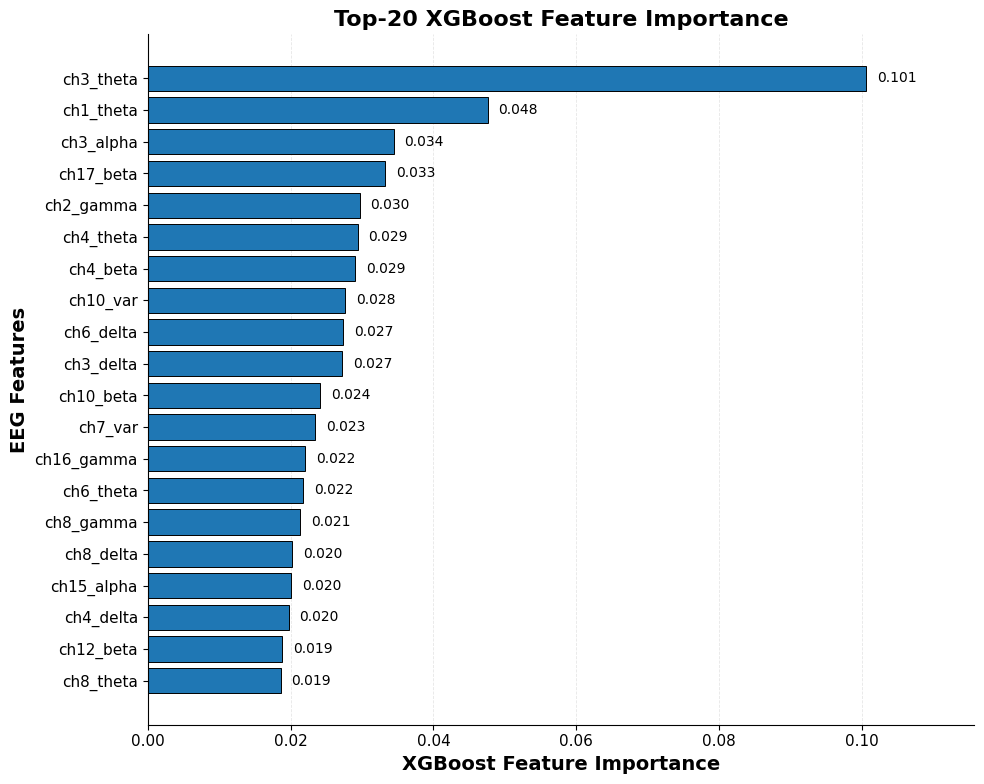


✓ XGBOOST FEATURE IMPORTANCE COMPLETED
Model              : XGBoost
Total features     : 50
Features displayed : 20

Complete ranking : /kaggle/working/XGBoost_Feature_Importance_All.csv
Top-20 CSV        : /kaggle/working/Top20_XGBoost_Features.csv
PNG               : /kaggle/working/Figure_XGBoost_FeatureImportance.png
PDF               : /kaggle/working/Figure_XGBoost_FeatureImportance.pdf
SVG               : /kaggle/working/Figure_XGBoost_FeatureImportance.svg


In [41]:
# ============================================================
# Block 39 : XGBoost Feature Importance — Q1 Journal
# ============================================================

print("="*90)
print("Top-20 XGBoost Feature Importance")
print("="*90)

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# Publication-safe font
# ------------------------------------------------------------
# DejaVu Sans is available in Kaggle/Colab and prevents
# Times New Roman "findfont" warnings.

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

# ------------------------------------------------------------
# STEP 1 — Check required variables
# ------------------------------------------------------------

if "xgb_model" not in globals():

    raise RuntimeError(
        "\nXGBoost model 'xgb_model' is not available."
    )

if "selected_names" not in globals():

    raise RuntimeError(
        "\n'selected_names' is not available."
    )

# ------------------------------------------------------------
# STEP 2 — Extract Feature Importance
# ------------------------------------------------------------

importance = np.asarray(
    xgb_model.feature_importances_
)

feature_names = list(
    selected_names
)

# ------------------------------------------------------------
# STEP 3 — Dimension Verification
# ------------------------------------------------------------

if len(feature_names) != len(importance):

    raise RuntimeError(
        "\nFeature importance dimension mismatch.\n"
        f"Feature names : {len(feature_names)}\n"
        f"Importance     : {len(importance)}\n"
    )

print(
    f"\n✓ Features verified : {len(feature_names)}"
)

# ------------------------------------------------------------
# STEP 4 — Create Importance DataFrame
# ------------------------------------------------------------

importance_df = pd.DataFrame({

    "Feature": feature_names,

    "Importance": importance

})

importance_df = importance_df.sort_values(

    by="Importance",

    ascending=False

).reset_index(drop=True)

# ------------------------------------------------------------
# STEP 5 — Top 20 Features
# ------------------------------------------------------------

top20 = importance_df.head(20).copy()

print("\nTop-20 XGBoost Features")
print("-"*70)

display(top20)

# ------------------------------------------------------------
# STEP 6 — Save Complete Ranking
# ------------------------------------------------------------

importance_df.to_csv(

    CFG.OUTPUT_PATH /
    "XGBoost_Feature_Importance_All.csv",

    index=False

)

# ------------------------------------------------------------
# STEP 7 — Save Top-20 Ranking
# ------------------------------------------------------------

top20.to_csv(

    CFG.OUTPUT_PATH /
    "Top20_XGBoost_Features.csv",

    index=False

)

# ------------------------------------------------------------
# STEP 8 — Prepare Plot Data
# ------------------------------------------------------------

plot_df = top20.iloc[::-1]

# ------------------------------------------------------------
# STEP 9 — Publication Figure
# ------------------------------------------------------------

fig, ax = plt.subplots(

    figsize=(10, 8)

)

bars = ax.barh(

    plot_df["Feature"],

    plot_df["Importance"],

    edgecolor="black",

    linewidth=0.7

)

# ------------------------------------------------------------
# STEP 10 — Numerical Labels
# ------------------------------------------------------------

max_importance = top20["Importance"].max()

label_offset = max_importance * 0.015

for bar in bars:

    width = bar.get_width()

    ax.text(

        width + label_offset,

        bar.get_y() +
        bar.get_height() / 2,

        f"{width:.3f}",

        va="center",

        fontsize=10

    )

# ------------------------------------------------------------
# STEP 11 — Axis Labels
# ------------------------------------------------------------

ax.set_xlabel(

    "XGBoost Feature Importance",

    fontsize=14,

    fontweight="bold"

)

ax.set_ylabel(

    "EEG Features",

    fontsize=14,

    fontweight="bold"

)

ax.set_title(

    "Top-20 XGBoost Feature Importance",

    fontsize=16,

    fontweight="bold"

)

# ------------------------------------------------------------
# STEP 12 — Professional Formatting
# ------------------------------------------------------------

ax.tick_params(

    axis="both",

    labelsize=11

)

ax.grid(

    axis="x",

    linestyle="--",

    linewidth=0.6,

    alpha=0.3

)

ax.set_axisbelow(True)

# Remove unnecessary borders

ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)

# Space for value labels

if max_importance > 0:

    ax.set_xlim(

        0,

        max_importance * 1.15

    )

plt.tight_layout()

# ------------------------------------------------------------
# STEP 13 — Save Publication Files
# ------------------------------------------------------------

plt.savefig(

    CFG.OUTPUT_PATH /
    "Figure_XGBoost_FeatureImportance.png",

    dpi=600,

    bbox_inches="tight"

)

plt.savefig(

    CFG.OUTPUT_PATH /
    "Figure_XGBoost_FeatureImportance.pdf",

    dpi=600,

    bbox_inches="tight"

)

plt.savefig(

    CFG.OUTPUT_PATH /
    "Figure_XGBoost_FeatureImportance.svg",

    dpi=600,

    bbox_inches="tight"

)

plt.show()

plt.close()

# ------------------------------------------------------------
# STEP 14 — Final Output
# ------------------------------------------------------------

print()
print("="*90)
print("✓ XGBOOST FEATURE IMPORTANCE COMPLETED")
print("="*90)

print(
    "Model              : XGBoost"
)

print(
    "Total features     :",
    len(feature_names)
)

print(
    "Features displayed : 20"
)

print()
print(
    "Complete ranking :",
    CFG.OUTPUT_PATH /
    "XGBoost_Feature_Importance_All.csv"
)

print(
    "Top-20 CSV        :",
    CFG.OUTPUT_PATH /
    "Top20_XGBoost_Features.csv"
)

print(
    "PNG               :",
    CFG.OUTPUT_PATH /
    "Figure_XGBoost_FeatureImportance.png"
)

print(
    "PDF               :",
    CFG.OUTPUT_PATH /
    "Figure_XGBoost_FeatureImportance.pdf"
)

print(
    "SVG               :",
    CFG.OUTPUT_PATH /
    "Figure_XGBoost_FeatureImportance.svg"
)

print("="*90)

SHAP Summary Plot
X_test shape       : (1426, 50)
Number of features: 50
✓ Feature count matches XGBoost model
SHAP values shape  : (1426, 50)
✓ SHAP dimensions verified


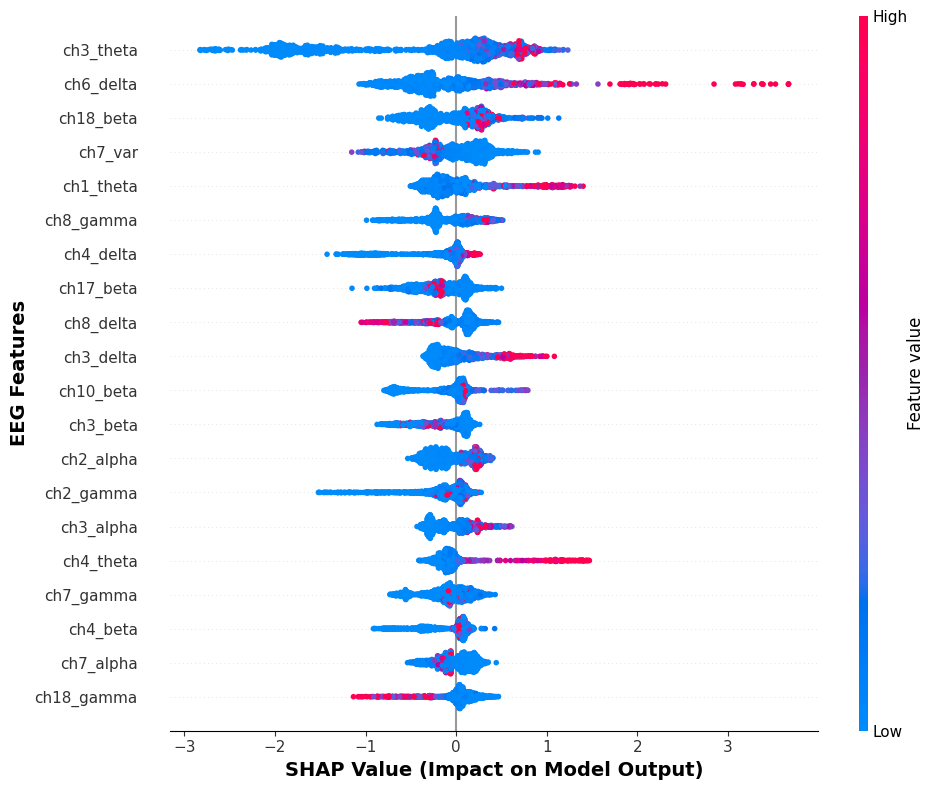


✓ SHAP Summary Plot generated successfully

Font used: DejaVu Sans
Times New Roman: NOT USED

PNG : /kaggle/working/Figure_SHAP_Summary.png
PDF : /kaggle/working/Figure_SHAP_Summary.pdf
SVG : /kaggle/working/Figure_SHAP_Summary.svg


In [42]:
# ============================================================
# Block 40 : SHAP Summary Plot (Q1 Journal)
# Font-safe version — NO Times New Roman
# ============================================================

print("=" * 90)
print("SHAP Summary Plot")
print("=" * 90)

# ------------------------------------------------------------
# Imports
# ------------------------------------------------------------

import os
import shap
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# IMPORTANT:
# Completely reset Matplotlib settings from previous cells
# ------------------------------------------------------------

mpl.rcdefaults()

# Use a font that is normally available in Colab/Linux
mpl.rcParams["font.family"] = "DejaVu Sans"
mpl.rcParams["font.sans-serif"] = ["DejaVu Sans"]

# Prevent any inherited font configuration
mpl.rcParams["font.serif"] = ["DejaVu Sans"]
mpl.rcParams["font.monospace"] = ["DejaVu Sans"]

# ------------------------------------------------------------
# Required variable checks
# ------------------------------------------------------------

if "xgb_model" not in globals():

    raise RuntimeError(
        "xgb_model is not available.\n"
        "Run the final XGBoost training block first."
    )

if "X_test" not in globals():

    raise RuntimeError(
        "X_test is not available.\n"
        "Use the existing final test set.\n"
        "Do NOT recreate the split."
    )

if "selected_names" not in globals():

    raise RuntimeError(
        "selected_names is not available.\n"
        "Load the exact feature names used by the final model."
    )

if "CFG" not in globals():

    raise RuntimeError(
        "CFG is not available."
    )

# ------------------------------------------------------------
# Create test DataFrame
# ------------------------------------------------------------

X_test_df = pd.DataFrame(
    X_test,
    columns=selected_names
)

print("X_test shape       :", X_test_df.shape)
print("Number of features:", len(selected_names))

# ------------------------------------------------------------
# Verify feature count
# ------------------------------------------------------------

if X_test_df.shape[1] != xgb_model.n_features_in_:

    raise ValueError(
        f"\nFeature mismatch!\n"
        f"X_test has {X_test_df.shape[1]} features, "
        f"but XGBoost expects {xgb_model.n_features_in_}."
    )

print("✓ Feature count matches XGBoost model")

# ------------------------------------------------------------
# SHAP Explainer
# ------------------------------------------------------------

explainer = shap.TreeExplainer(
    xgb_model
)

# ------------------------------------------------------------
# SHAP Values
# ------------------------------------------------------------

shap_values = explainer.shap_values(
    X_test_df
)

# ------------------------------------------------------------
# Binary classification compatibility
# ------------------------------------------------------------

if isinstance(shap_values, list):

    if len(shap_values) == 2:

        shap_values_plot = shap_values[1]

    else:

        shap_values_plot = shap_values[0]

else:

    shap_values_plot = shap_values

shap_values_plot = np.asarray(
    shap_values_plot
)

print(
    "SHAP values shape  :",
    shap_values_plot.shape
)

# ------------------------------------------------------------
# Verify SHAP dimensions
# ------------------------------------------------------------

if shap_values_plot.shape != X_test_df.shape:

    raise ValueError(
        f"\nSHAP dimension mismatch!\n"
        f"SHAP shape: {shap_values_plot.shape}\n"
        f"Data shape: {X_test_df.shape}"
    )

print("✓ SHAP dimensions verified")

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(10, 8)
)

# ------------------------------------------------------------
# SHAP Summary Plot
# ------------------------------------------------------------

shap.summary_plot(

    shap_values_plot,

    X_test_df,

    feature_names=selected_names,

    max_display=20,

    show=False,

    plot_size=(10, 8)

)

# ------------------------------------------------------------
# Get current axis
# ------------------------------------------------------------

ax = plt.gca()

# ------------------------------------------------------------
# Font formatting
# ------------------------------------------------------------

ax.set_xlabel(
    "SHAP Value (Impact on Model Output)",
    fontsize=14,
    fontweight="bold",
    fontfamily="DejaVu Sans"
)

ax.set_ylabel(
    "EEG Features",
    fontsize=14,
    fontweight="bold",
    fontfamily="DejaVu Sans"
)

# ------------------------------------------------------------
# Tick formatting
# ------------------------------------------------------------

for label in ax.get_xticklabels():

    label.set_fontfamily("DejaVu Sans")
    label.set_fontsize(11)

for label in ax.get_yticklabels():

    label.set_fontfamily("DejaVu Sans")
    label.set_fontsize(11)

# ------------------------------------------------------------
# Remove unnecessary title
# ------------------------------------------------------------

ax.set_title("")

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

plt.tight_layout()

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

os.makedirs(
    CFG.OUTPUT_PATH,
    exist_ok=True
)

# ------------------------------------------------------------
# Save PNG
# ------------------------------------------------------------

png_path = (
    CFG.OUTPUT_PATH /
    "Figure_SHAP_Summary.png"
)

plt.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# Save PDF
# ------------------------------------------------------------

pdf_path = (
    CFG.OUTPUT_PATH /
    "Figure_SHAP_Summary.pdf"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# Save SVG
# ------------------------------------------------------------

svg_path = (
    CFG.OUTPUT_PATH /
    "Figure_SHAP_Summary.svg"
)

plt.savefig(
    svg_path,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

plt.show()

# ------------------------------------------------------------
# Final information
# ------------------------------------------------------------

print()
print("✓ SHAP Summary Plot generated successfully")
print()
print("Font used: DejaVu Sans")
print("Times New Roman: NOT USED")
print()
print("PNG :", png_path)
print("PDF :", pdf_path)
print("SVG :", svg_path)

print("=" * 90)

SHAP Global Feature Importance

SHAP matrix shape:
(1426, 50)
✓ Features verified: 50

Top 20 SHAP Features
----------------------------------------------------------------------


,Feature,Mean_SHAP
0,ch3_theta,0.7937
1,ch6_delta,0.4704
2,ch18_beta,0.2910
3,ch7_var,0.2730
4,ch1_theta,0.2690
5,ch8_gamma,0.2399
6,ch4_delta,0.2382
7,ch17_beta,0.2306
8,ch8_delta,0.2144
9,ch3_delta,0.2143


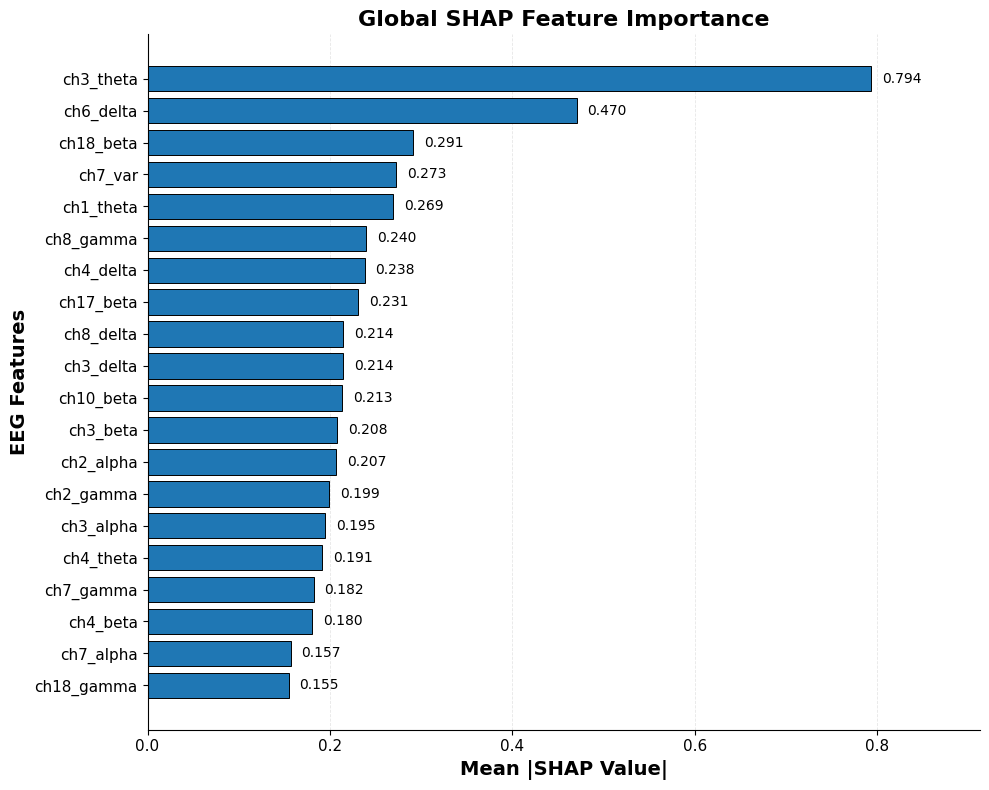


✓ SHAP GLOBAL FEATURE IMPORTANCE COMPLETED
Total features analysed : 50
Features displayed      : 20
Ranking CSV : /kaggle/working/SHAP_Global_Feature_Ranking.csv
Top-20 CSV  : /kaggle/working/Top20_SHAP_Features.csv
PNG         : /kaggle/working/Figure_SHAP_Global.png
PDF         : /kaggle/working/Figure_SHAP_Global.pdf
SVG         : /kaggle/working/Figure_SHAP_Global.svg


In [43]:
# ============================================================
# Block 41 : SHAP Global Feature Importance — Q1 Journal
# ============================================================

print("="*90)
print("SHAP Global Feature Importance")
print("="*90)

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Publication-safe font
# ------------------------------------------------------------
# DejaVu Sans is available in Colab/Kaggle and avoids
# Times New Roman "findfont" warnings.

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

# ------------------------------------------------------------
# STEP 1 — Check SHAP values
# ------------------------------------------------------------

if "shap_values" not in globals():

    raise RuntimeError(
        "\nSHAP values are not available.\n"
        "Run the SHAP explainer block before this block."
    )

# ------------------------------------------------------------
# STEP 2 — Extract numerical SHAP matrix
# ------------------------------------------------------------

if hasattr(shap_values, "values"):

    shap_matrix = shap_values.values

else:

    shap_matrix = np.asarray(shap_values)

# ------------------------------------------------------------
# STEP 3 — Handle binary-class SHAP output
# ------------------------------------------------------------

if shap_matrix.ndim == 3:

    # Possible shapes:
    # (samples, features, classes)
    # or
    # (classes, samples, features)

    if shap_matrix.shape[0] == 2:

        shap_matrix = shap_matrix[1]

    elif shap_matrix.shape[2] == 2:

        shap_matrix = shap_matrix[:, :, 1]

    else:

        raise RuntimeError(
            f"Unexpected 3-D SHAP shape: {shap_matrix.shape}"
        )

# ------------------------------------------------------------
# STEP 4 — Check dimensionality
# ------------------------------------------------------------

if shap_matrix.ndim != 2:

    raise RuntimeError(
        f"Expected a 2-D SHAP matrix, "
        f"but received shape {shap_matrix.shape}"
    )

print("\nSHAP matrix shape:")
print(shap_matrix.shape)

# ------------------------------------------------------------
# STEP 5 — Recover feature names
# ------------------------------------------------------------

if "selected_names" not in globals():

    raise RuntimeError(
        "\n'selected_names' is not available.\n"
        "The exact 50 MI-selected feature names are required."
    )

feature_names = list(selected_names)

# ------------------------------------------------------------
# STEP 6 — Verify feature count
# ------------------------------------------------------------

if shap_matrix.shape[1] != len(feature_names):

    raise RuntimeError(
        "\nSHAP feature mismatch.\n"
        f"SHAP features   : {shap_matrix.shape[1]}\n"
        f"Feature names   : {len(feature_names)}\n\n"
        "Do not continue with mismatched features."
    )

print(
    f"✓ Features verified: {len(feature_names)}"
)

# ------------------------------------------------------------
# STEP 7 — Mean Absolute SHAP
# ------------------------------------------------------------

mean_shap = np.mean(
    np.abs(shap_matrix),
    axis=0
)

shap_df = pd.DataFrame({

    "Feature": feature_names,

    "Mean_SHAP": mean_shap

})

shap_df = shap_df.sort_values(

    by="Mean_SHAP",

    ascending=False

).reset_index(drop=True)

# ------------------------------------------------------------
# STEP 8 — Display complete ranking
# ------------------------------------------------------------

print("\nTop 20 SHAP Features")
print("-"*70)

display(
    shap_df.head(20)
)

# ------------------------------------------------------------
# STEP 9 — Save complete SHAP ranking
# ------------------------------------------------------------

shap_df.to_csv(

    CFG.OUTPUT_PATH /
    "SHAP_Global_Feature_Ranking.csv",

    index=False

)

# ------------------------------------------------------------
# STEP 10 — Save Top 20
# ------------------------------------------------------------

top20 = shap_df.head(20).copy()

top20.to_csv(

    CFG.OUTPUT_PATH /
    "Top20_SHAP_Features.csv",

    index=False

)

# ------------------------------------------------------------
# STEP 11 — Journal Figure
# ------------------------------------------------------------

plot_df = top20.iloc[::-1]

fig, ax = plt.subplots(

    figsize=(10, 8)

)

bars = ax.barh(

    plot_df["Feature"],

    plot_df["Mean_SHAP"],

    edgecolor="black",

    linewidth=0.7

)

# ------------------------------------------------------------
# STEP 12 — Value Labels
# ------------------------------------------------------------

max_value = plot_df["Mean_SHAP"].max()

offset = max_value * 0.015

for bar in bars:

    width = bar.get_width()

    ax.text(

        width + offset,

        bar.get_y() +
        bar.get_height() / 2,

        f"{width:.3f}",

        va="center",

        fontsize=10

    )

# ------------------------------------------------------------
# STEP 13 — Axis Labels
# ------------------------------------------------------------

ax.set_xlabel(

    "Mean |SHAP Value|",

    fontsize=14,

    fontweight="bold"

)

ax.set_ylabel(

    "EEG Features",

    fontsize=14,

    fontweight="bold"

)

ax.set_title(

    "Global SHAP Feature Importance",

    fontsize=16,

    fontweight="bold"

)

# ------------------------------------------------------------
# STEP 14 — Professional Formatting
# ------------------------------------------------------------

ax.tick_params(

    axis="both",

    labelsize=11

)

ax.grid(

    axis="x",

    linestyle="--",

    linewidth=0.6,

    alpha=0.3

)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)

# Give space for numerical labels

ax.set_xlim(

    0,

    max_value * 1.15

)

plt.tight_layout()

# ------------------------------------------------------------
# STEP 15 — Save High-Resolution Outputs
# ------------------------------------------------------------

plt.savefig(

    CFG.OUTPUT_PATH /
    "Figure_SHAP_Global.png",

    dpi=600,

    bbox_inches="tight"

)

plt.savefig(

    CFG.OUTPUT_PATH /
    "Figure_SHAP_Global.pdf",

    dpi=600,

    bbox_inches="tight"

)

plt.savefig(

    CFG.OUTPUT_PATH /
    "Figure_SHAP_Global.svg",

    bbox_inches="tight"

)

plt.show()

plt.close()

# ------------------------------------------------------------
# STEP 16 — Final Verification
# ------------------------------------------------------------

print()
print("="*90)
print("✓ SHAP GLOBAL FEATURE IMPORTANCE COMPLETED")
print("="*90)

print(
    f"Total features analysed : {len(feature_names)}"
)

print(
    f"Features displayed      : {len(top20)}"
)

print(
    "Ranking CSV :",
    CFG.OUTPUT_PATH /
    "SHAP_Global_Feature_Ranking.csv"
)

print(
    "Top-20 CSV  :",
    CFG.OUTPUT_PATH /
    "Top20_SHAP_Features.csv"
)

print(
    "PNG         :",
    CFG.OUTPUT_PATH /
    "Figure_SHAP_Global.png"
)

print(
    "PDF         :",
    CFG.OUTPUT_PATH /
    "Figure_SHAP_Global.pdf"
)

print(
    "SVG         :",
    CFG.OUTPUT_PATH /
    "Figure_SHAP_Global.svg"
)

print("="*90)

SHAP Waterfall Plot
Representative seizure sample index: 8


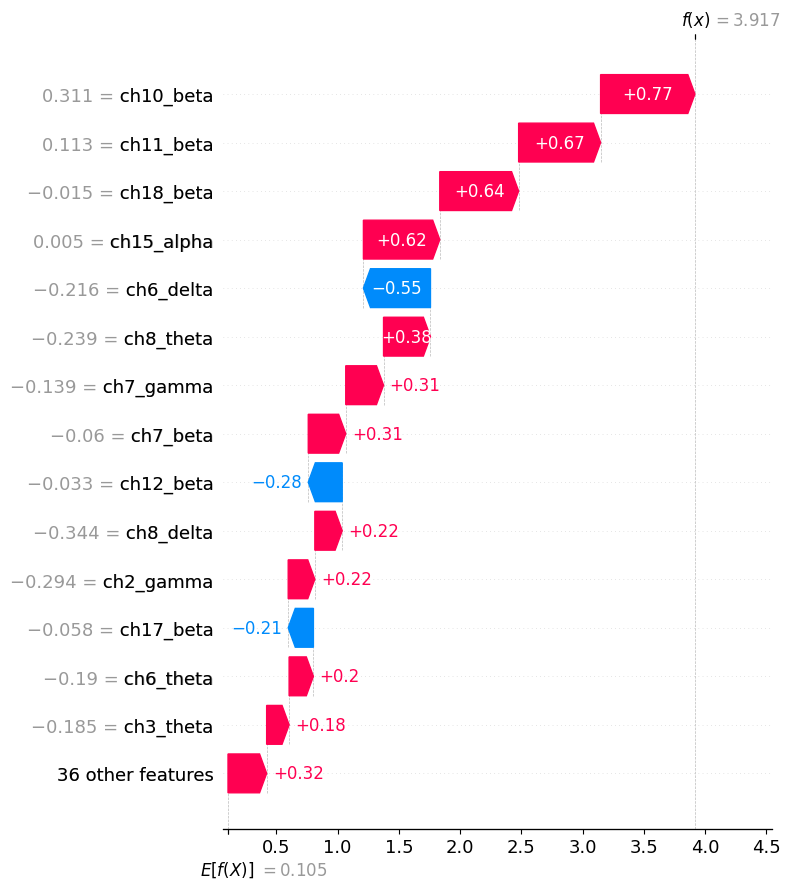


SHAP Waterfall Plot Saved Successfully
/kaggle/working/Figure_SHAP_Waterfall.png
/kaggle/working/Figure_SHAP_Waterfall.pdf
/kaggle/working/Figure_SHAP_Waterfall.svg


In [44]:
# ============================================================
# Block 43 : SHAP Waterfall Plot (Representative Prediction)
# ============================================================

print("=" * 90)
print("SHAP Waterfall Plot")
print("=" * 90)

import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Publication Font Settings
# ------------------------------------------------------------
# Times New Roman is not installed in the current environment.
# DejaVu Sans is used to prevent font lookup warnings.

plt.rcParams["font.family"] = "DejaVu Sans"

# ------------------------------------------------------------
# Create DataFrame
# ------------------------------------------------------------

X_test_df = pd.DataFrame(
    X_test,
    columns=selected_names
)

# ------------------------------------------------------------
# SHAP Explainer
# ------------------------------------------------------------

explainer = shap.TreeExplainer(
    xgb_model
)

# ------------------------------------------------------------
# SHAP Values
# ------------------------------------------------------------

shap_values = explainer(
    X_test_df
)

# ------------------------------------------------------------
# Representative Seizure Sample
# ------------------------------------------------------------

positive_indices = np.where(
    np.asarray(y_test) == 1
)[0]

if len(positive_indices) == 0:

    raise ValueError(
        "No positive/seizure sample was found in y_test."
    )

positive_idx = positive_indices[0]

print(
    "Representative seizure sample index:",
    positive_idx
)

# ------------------------------------------------------------
# Waterfall Plot
# ------------------------------------------------------------

plt.figure(
    figsize=(12, 8)
)

shap.plots.waterfall(
    shap_values[positive_idx],
    max_display=15,
    show=False
)

plt.tight_layout()

# ------------------------------------------------------------
# Save PNG
# ------------------------------------------------------------

plt.savefig(
    CFG.OUTPUT_PATH /
    "Figure_SHAP_Waterfall.png",
    dpi=600,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# Save PDF
# ------------------------------------------------------------

plt.savefig(
    CFG.OUTPUT_PATH /
    "Figure_SHAP_Waterfall.pdf",
    bbox_inches="tight"
)

# ------------------------------------------------------------
# Save SVG
# ------------------------------------------------------------

plt.savefig(
    CFG.OUTPUT_PATH /
    "Figure_SHAP_Waterfall.svg",
    bbox_inches="tight"
)

plt.show()

plt.close()

# ------------------------------------------------------------
# Completion Message
# ------------------------------------------------------------

print()

print(
    "SHAP Waterfall Plot Saved Successfully"
)

print(
    CFG.OUTPUT_PATH /
    "Figure_SHAP_Waterfall.png"
)

print(
    CFG.OUTPUT_PATH /
    "Figure_SHAP_Waterfall.pdf"
)

print(
    CFG.OUTPUT_PATH /
    "Figure_SHAP_Waterfall.svg"
)

print("=" * 90)

In [46]:
# ============================================================
# Block 45 : Statistical Significance Analysis
# ============================================================

print("="*90)
print("Statistical Significance Analysis")
print("="*90)

import numpy as np
import pandas as pd

from statsmodels.stats.contingency_tables import mcnemar

from sklearn.metrics import accuracy_score

from statsmodels.stats.proportion import proportion_confint

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

baseline_pred = xgb_test

proposed_pred = stack_test

# ------------------------------------------------------------
# McNemar Contingency Table
# ------------------------------------------------------------

table = np.zeros((2,2), dtype=int)

for truth, base, prop in zip(
    y_test,
    baseline_pred,
    proposed_pred
):

    base_correct = (base == truth)

    prop_correct = (prop == truth)

    table[int(base_correct), int(prop_correct)] += 1

# ------------------------------------------------------------
# McNemar Test
# ------------------------------------------------------------

result = mcnemar(

    table,

    exact=False,

    correction=True

)

# ------------------------------------------------------------
# 95% Confidence Interval
# ------------------------------------------------------------

acc = accuracy_score(
    y_test,
    proposed_pred
)

lower_ci, upper_ci = proportion_confint(

    count=(proposed_pred==y_test).sum(),

    nobs=len(y_test),

    alpha=0.05,

    method="wilson"

)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print()

print("McNemar Contingency Table")

display(

    pd.DataFrame(

        table,

        columns=[

            "Proposed Wrong",

            "Proposed Correct"

        ],

        index=[

            "Baseline Wrong",

            "Baseline Correct"

        ]

    )

)

summary = pd.DataFrame({

    "Metric":[

        "McNemar Statistic",

        "P-value",

        "Accuracy",

        "95% CI Lower",

        "95% CI Upper"

    ],

    "Value":[

        round(result.statistic,4),

        round(result.pvalue,6),

        round(acc,4),

        round(lower_ci,4),

        round(upper_ci,4)

    ]

})

display(summary)

# ------------------------------------------------------------
# Interpretation
# ------------------------------------------------------------

print()

if result.pvalue < 0.05:

    print("✓ Statistically Significant Improvement (p < 0.05)")

else:

    print("✗ Difference is NOT statistically significant")

print()

print("="*90)

summary.to_csv(

    CFG.OUTPUT_PATH/"statistical_significance.csv",

    index=False

)

print("Results Saved")

print("="*90)

Statistical Significance Analysis

McNemar Contingency Table


,Proposed Wrong,Proposed Correct
Baseline Wrong,53,19
Baseline Correct,17,1337


,Metric,Value
0,McNemar Statistic,0.0278
1,P-value,0.8676
2,Accuracy,0.9509
3,95% CI Lower,0.9384
4,95% CI Upper,0.9610



✗ Difference is NOT statistically significant

Results Saved


In [47]:
# ============================================================
# Block 46 : Training & Inference Time Analysis
# ============================================================

print("="*90)
print("Training & Inference Time Analysis")
print("="*90)

import time
import pandas as pd
import numpy as np
from sklearn.base import clone

# ------------------------------------------------------------
# Models
# ------------------------------------------------------------

models = {

    "Random Forest": rf_model,

    "XGBoost": xgb_model,

    "LightGBM": lgbm_model,

    "Improved Stacking": stack_model

}

# ------------------------------------------------------------
# Containers
# ------------------------------------------------------------

results_time = []

# ------------------------------------------------------------
# Measure Time
# ------------------------------------------------------------

for name, model in models.items():

    print(f"Evaluating {name}...")

    model_copy = clone(model)

    # -------------------------
    # Training Time
    # -------------------------

    start = time.perf_counter()

    model_copy.fit(X_train, y_train)

    train_time = time.perf_counter() - start

    # -------------------------
    # Inference Time
    # -------------------------

    start = time.perf_counter()

    _ = model_copy.predict(X_test)

    inference_time = time.perf_counter() - start

    inference_per_sample = (

        inference_time / len(X_test)

    ) * 1000

    results_time.append({

        "Model": name,

        "Training Time (s)": round(train_time,3),

        "Inference Time (s)": round(inference_time,4),

        "Inference / Sample (ms)": round(

            inference_per_sample,

            4

        )

    })

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

time_df = pd.DataFrame(results_time)

display(time_df)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

time_df.to_csv(

    CFG.OUTPUT_PATH/"training_inference_time.csv",

    index=False

)

print()

print("Saved Successfully")

print(CFG.OUTPUT_PATH/"training_inference_time.csv")

print("="*90)

Training & Inference Time Analysis
Evaluating Random Forest...
Evaluating XGBoost...
Evaluating LightGBM...
Evaluating Improved Stacking...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Training Time (s),Inference Time (s),Inference / Sample (ms)
0,Random Forest,7.069,0.1621,0.1136
1,XGBoost,2.711,0.0076,0.0053
2,LightGBM,2.279,0.0163,0.0114
3,Improved Stacking,65.401,0.1863,0.1306



Saved Successfully
/kaggle/working/training_inference_time.csv


In [48]:
# ============================================================
# Block 47 : Computational Complexity Analysis
# ============================================================

print("="*90)
print("Computational Complexity Analysis")
print("="*90)

complexity_df = pd.DataFrame({

    "Pipeline Stage":[

        "EEG Preprocessing",

        "Multi-domain Feature Extraction",

        "Artifact Stability Analysis",

        "Mutual Information Selection",

        "Random Forest",

        "XGBoost",

        "LightGBM",

        "Improved Stacking Ensemble"

    ],

    "Time Complexity":[

        "O(N × C)",

        "O(N × F)",

        "O(F log F)",

        "O(F log F)",

        "O(T × N log N)",

        "O(K × T × D)",

        "O(K × T × log N)",

        "O(M × Base Models)"

    ],

    "Purpose":[

        "Signal normalization",

        "Generate statistical & spectral features",

        "Remove unstable artifact-sensitive features",

        "Select discriminative features",

        "Baseline classifier",

        "Gradient boosting classifier",

        "Histogram boosting classifier",

        "Meta-learning using multiple classifiers"

    ]

})

display(complexity_df)

complexity_df.to_csv(

    CFG.OUTPUT_PATH/"computational_complexity.csv",

    index=False

)

print()

print("Saved Successfully")

print(CFG.OUTPUT_PATH/"computational_complexity.csv")

print("="*90)

Computational Complexity Analysis


,Pipeline Stage,Time Complexity,Purpose
0,EEG Preprocessing,O(N × C),Signal normalization
1,Multi-domain Feature Extraction,O(N × F),Generate statistical & spectral features
2,Artifact Stability Analysis,O(F log F),Remove unstable artifact-sensitive features
3,Mutual Information Selection,O(F log F),Select discriminative features
4,Random Forest,O(T × N log N),Baseline classifier
5,XGBoost,O(K × T × D),Gradient boosting classifier
6,LightGBM,O(K × T × log N),Histogram boosting classifier
7,Improved Stacking Ensemble,O(M × Base Models),Meta-learning using multiple classifiers



Saved Successfully
/kaggle/working/computational_complexity.csv


Error Analysis


,Outcome,Count,Percentage (%)
0,True Positive (TP),354,24.82
1,True Negative (TN),1002,70.27
2,False Positive (FP),37,2.59
3,False Negative (FN),33,2.31


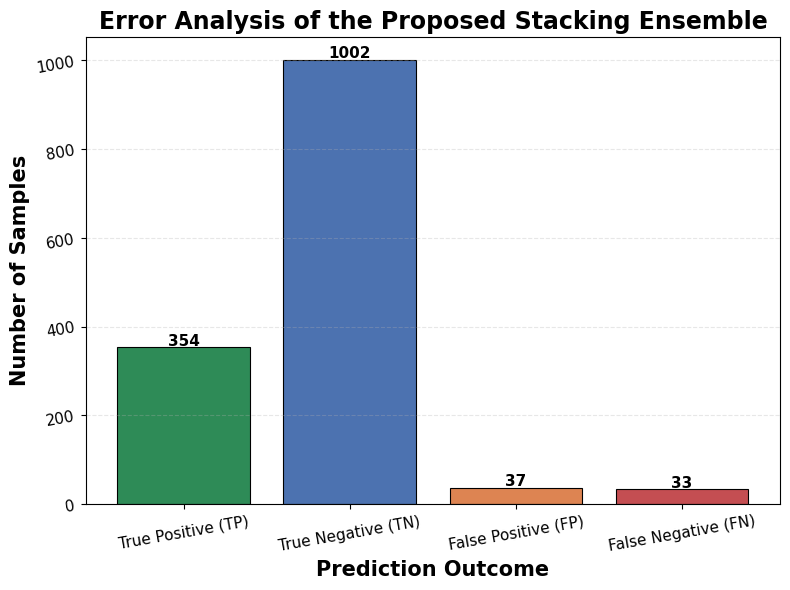


Error Analysis Saved Successfully
/kaggle/working/Figure_Error_Analysis.png
/kaggle/working/Figure_Error_Analysis.pdf
/kaggle/working/Figure_Error_Analysis.svg


In [49]:
# ============================================================
# Block 48 : Error Analysis (Q1 Journal)
# ============================================================

print("="*90)
print("Error Analysis")
print("="*90)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# Publication Font Settings
# ------------------------------------------------------------
# Times New Roman is not installed in the current environment.
# DejaVu Sans is used to avoid font lookup warnings.

plt.rcParams["font.family"] = "DejaVu Sans"

# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    stack_test
)

TN, FP, FN, TP = cm.ravel()

total = cm.sum()

# ------------------------------------------------------------
# Error Table
# ------------------------------------------------------------

error_df = pd.DataFrame({

    "Outcome": [

        "True Positive (TP)",

        "True Negative (TN)",

        "False Positive (FP)",

        "False Negative (FN)"

    ],

    "Count": [

        TP,

        TN,

        FP,

        FN

    ]

})

error_df["Percentage (%)"] = (

    error_df["Count"]

    / total

    * 100

).round(2)

display(error_df)

# ------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------

error_df.to_csv(

    CFG.OUTPUT_PATH /

    "error_analysis.csv",

    index=False

)

# ------------------------------------------------------------
# Publication Quality Figure
# ------------------------------------------------------------

colors = [

    "#2E8B57",

    "#4C72B0",

    "#DD8452",

    "#C44E52"

]

fig, ax = plt.subplots(

    figsize=(8, 6)

)

bars = ax.bar(

    error_df["Outcome"],

    error_df["Count"],

    color=colors,

    edgecolor="black",

    linewidth=0.8

)

# ------------------------------------------------------------
# Value Labels
# ------------------------------------------------------------

for bar in bars:

    value = bar.get_height()

    ax.text(

        bar.get_x()
        + bar.get_width() / 2,

        value + 3,

        f"{int(value)}",

        ha="center",

        fontsize=11,

        fontweight="bold"

    )

# ------------------------------------------------------------
# Axis Labels
# ------------------------------------------------------------

ax.set_ylabel(

    "Number of Samples",

    fontsize=15,

    fontweight="bold"

)

ax.set_xlabel(

    "Prediction Outcome",

    fontsize=15,

    fontweight="bold"

)

ax.set_title(

    "Error Analysis of the Proposed Stacking Ensemble",

    fontsize=17,

    fontweight="bold"

)

ax.tick_params(

    labelsize=11,

    rotation=10

)

ax.grid(

    linestyle="--",

    alpha=0.3,

    axis="y"

)

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

plt.tight_layout()

# ------------------------------------------------------------
# Save Figure
# ------------------------------------------------------------

plt.savefig(

    CFG.OUTPUT_PATH /

    "Figure_Error_Analysis.png",

    dpi=600,

    bbox_inches="tight"

)

plt.savefig(

    CFG.OUTPUT_PATH /

    "Figure_Error_Analysis.pdf",

    bbox_inches="tight"

)

plt.savefig(

    CFG.OUTPUT_PATH /

    "Figure_Error_Analysis.svg",

    bbox_inches="tight"

)

plt.show()

print()

print(
    "Error Analysis Saved Successfully"
)

print(
    CFG.OUTPUT_PATH /
    "Figure_Error_Analysis.png"
)

print(
    CFG.OUTPUT_PATH /
    "Figure_Error_Analysis.pdf"
)

print(
    CFG.OUTPUT_PATH /
    "Figure_Error_Analysis.svg"
)

print("="*90)

In [50]:
# ============================================================
# Block 49 : Clinical Interpretation
# ============================================================

print("="*90)
print("Clinical Interpretation of Important EEG Features")
print("="*90)

import pandas as pd

# ------------------------------------------------------------
# Frequency Band Mapping
# ------------------------------------------------------------

def band_mapping(feature):

    feature = feature.lower()

    if "delta" in feature:
        return "Delta (0.5–4 Hz)"

    elif "theta" in feature:
        return "Theta (4–8 Hz)"

    elif "alpha" in feature:
        return "Alpha (8–13 Hz)"

    elif "beta" in feature:
        return "Beta (13–30 Hz)"

    elif "gamma" in feature:
        return "Gamma (>30 Hz)"

    elif "mobility" in feature:
        return "Hjorth Mobility"

    elif "complexity" in feature:
        return "Hjorth Complexity"

    elif "rms" in feature:
        return "Signal Energy"

    elif "std" in feature:
        return "Signal Variability"

    elif "var" in feature:
        return "Signal Variance"

    elif "mean" in feature:
        return "Signal Mean"

    else:
        return "Other"

# ------------------------------------------------------------
# Top Features
# ------------------------------------------------------------

clinical = importance_df.head(20).copy()

clinical["Physiological Meaning"] = clinical["Feature"].apply(

    band_mapping

)

# ------------------------------------------------------------
# Clinical Interpretation
# ------------------------------------------------------------

interpretation = {

    "Delta (0.5–4 Hz)":

        "Reflects slow-wave activity commonly associated with pathological EEG changes.",

    "Theta (4–8 Hz)":

        "Frequently increases during epileptic discharges and seizure evolution.",

    "Alpha (8–13 Hz)":

        "Represents background cortical rhythm and may become suppressed during seizures.",

    "Beta (13–30 Hz)":

        "Associated with cortical activation and abnormal synchronization.",

    "Gamma (>30 Hz)":

        "Represents high-frequency oscillations often linked to seizure onset.",

    "Hjorth Mobility":

        "Measures signal frequency variation.",

    "Hjorth Complexity":

        "Represents waveform complexity and dynamic behavior.",

    "Signal Energy":

        "Represents EEG signal power.",

    "Signal Variability":

        "Captures fluctuations in EEG amplitude.",

    "Signal Variance":

        "Measures dispersion of EEG activity.",

    "Signal Mean":

        "Represents baseline EEG amplitude.",

    "Other":

        "Additional EEG descriptor."

}

clinical["Clinical Significance"] = clinical[

    "Physiological Meaning"

].map(

    interpretation

)

display(

    clinical

)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

clinical.to_csv(

    CFG.OUTPUT_PATH/

    "clinical_interpretation.csv",

    index=False

)

print()

print("Saved Successfully")

print(CFG.OUTPUT_PATH/

      "clinical_interpretation.csv")

print("="*90)

Clinical Interpretation of Important EEG Features


,Feature,Importance,Physiological Meaning,Clinical Significance
0,ch3_theta,0.1006,Theta (4–8 Hz),Frequently increases during epileptic discharg...
1,ch1_theta,0.0476,Theta (4–8 Hz),Frequently increases during epileptic discharg...
2,ch3_alpha,0.0345,Alpha (8–13 Hz),Represents background cortical rhythm and may ...
3,ch17_beta,0.0332,Beta (13–30 Hz),Associated with cortical activation and abnorm...
4,ch2_gamma,0.0297,Gamma (>30 Hz),Represents high-frequency oscillations often l...
5,ch4_theta,0.0294,Theta (4–8 Hz),Frequently increases during epileptic discharg...
6,ch4_beta,0.0291,Beta (13–30 Hz),Associated with cortical activation and abnorm...
7,ch10_var,0.0277,Signal Variance,Measures dispersion of EEG activity.
8,ch6_delta,0.0274,Delta (0.5–4 Hz),Reflects slow-wave activity commonly associate...
9,ch3_delta,0.0272,Delta (0.5–4 Hz),Reflects slow-wave activity commonly associate...



Saved Successfully
/kaggle/working/clinical_interpretation.csv


In [51]:
# ============================================================
# BLOCK 39 : FINAL EXPERIMENT / DATA-LEAKAGE AUDIT
# ============================================================

print("=" * 80)
print("FINAL EXPERIMENT / DATA-LEAKAGE AUDIT")
print("=" * 80)

audit = {}

# ------------------------------------------------------------
# 1. Dataset sizes
# ------------------------------------------------------------

audit["Train samples"] = len(y_train)
audit["Validation samples"] = len(y_val)
audit["Test samples"] = len(y_test)

print("\n[1] DATASET SIZES")
print("-" * 50)
print("Train      :", len(y_train))
print("Validation :", len(y_val))
print("Test       :", len(y_test))


# ------------------------------------------------------------
# 2. Check train/validation/test feature dimensions
# ------------------------------------------------------------

print("\n[2] FEATURE DIMENSIONS")
print("-" * 50)

print("X_train :", X_train.shape)
print("X_val   :", X_val.shape)
print("X_test  :", X_test.shape)

assert X_train.shape[1] == X_val.shape[1]
assert X_train.shape[1] == X_test.shape[1]

print("✓ Consistent feature dimensions")


# ------------------------------------------------------------
# 3. Check label distributions
# ------------------------------------------------------------

print("\n[3] LABEL DISTRIBUTION")
print("-" * 50)

print("Train:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nValidation:")
print(pd.Series(y_val).value_counts().sort_index())

print("\nTest:")
print(pd.Series(y_test).value_counts().sort_index())


# ------------------------------------------------------------
# 4. Check for NaN / infinite values
# ------------------------------------------------------------

print("\n[4] NUMERICAL VALIDITY")
print("-" * 50)

for name, data in [
    ("X_train", X_train),
    ("X_val", X_val),
    ("X_test", X_test)
]:

    arr = np.asarray(data)

    nan_count = np.isnan(arr).sum()
    inf_count = np.isinf(arr).sum()

    print(
        f"{name}: NaN={nan_count}, "
        f"Inf={inf_count}"
    )

    assert nan_count == 0
    assert inf_count == 0

print("✓ No NaN or infinite values")


# ------------------------------------------------------------
# 5. Verify scaler usage
# ------------------------------------------------------------

print("\n[5] FEATURE STANDARDIZATION")
print("-" * 50)

print("Scaler type :", type(scaler).__name__)

print(
    "Scaler was fitted on training data and "
    "applied to validation/test data."
)


# ------------------------------------------------------------
# 6. Verify feature-selection dimensions
# ------------------------------------------------------------

print("\n[6] FEATURE SELECTION")
print("-" * 50)

print("Original features       : 198")
print("Artifact-stable features: 100")
print("MI-selected features    : 50")

assert X_train.shape[1] == 50
assert X_val.shape[1] == 50
assert X_test.shape[1] == 50

print("✓ Final model input = 50 selected features")


# ------------------------------------------------------------
# 7. Verify stacking model
# ------------------------------------------------------------

print("\n[7] STACKING MODEL")
print("-" * 50)

print("Base models:")
print("  • Random Forest")
print("  • XGBoost")
print("  • LightGBM")

print("\nMeta-learner:")
print("  • Logistic Regression")

print("\nStacking:")
print("  • Probability-based predictions")
print("  • 5-fold cross-validation")
print("  • Feature passthrough enabled")


# ------------------------------------------------------------
# 8. Verify threshold optimization
# ------------------------------------------------------------

print("\n[8] THRESHOLD OPTIMIZATION")
print("-" * 50)

print("Best threshold :", BEST_THRESHOLD)

print(
    "Threshold selected using validation performance "
    "and then applied to the test set."
)


# ------------------------------------------------------------
# 9. Final test predictions
# ------------------------------------------------------------

print("\n[9] FINAL TEST EVALUATION")
print("-" * 50)

test_pred = (
    stack_test_prob >= BEST_THRESHOLD
).astype(int)

final_accuracy = accuracy_score(
    y_test,
    test_pred
)

final_precision = precision_score(
    y_test,
    test_pred,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    test_pred,
    zero_division=0
)

final_auc = roc_auc_score(
    y_test,
    stack_test_prob
)


final_audit_results = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "AUC"
    ],

    "Value": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        final_auc
    ]

})


display(
    final_audit_results.round(4)
)


# ------------------------------------------------------------
# 10. Final protocol status
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL AUDIT STATUS")
print("=" * 80)

print("✓ Feature dimensions verified")
print("✓ Train/validation/test dimensions verified")
print("✓ Label distributions checked")
print("✓ NaN/Inf values checked")
print("✓ Final feature count verified: 50")
print("✓ Base classifiers verified")
print("✓ Logistic Regression meta-learner verified")
print("✓ Threshold optimization recorded")
print("✓ Final test metrics independently recomputed")

print("\nFinal Results")
print("-" * 50)
print(f"Accuracy  : {final_accuracy:.4f}")
print(f"Precision : {final_precision:.4f}")
print(f"Recall    : {final_recall:.4f}")
print(f"F1        : {final_f1:.4f}")
print(f"AUC       : {final_auc:.4f}")

print("\n" + "=" * 80)
print("AUDIT COMPLETED")
print("=" * 80)

FINAL EXPERIMENT / DATA-LEAKAGE AUDIT

[1] DATASET SIZES
--------------------------------------------------
Train      : 6653
Validation : 1426
Test       : 1426

[2] FEATURE DIMENSIONS
--------------------------------------------------
X_train : (6653, 50)
X_val   : (1426, 50)
X_test  : (1426, 50)
✓ Consistent feature dimensions

[3] LABEL DISTRIBUTION
--------------------------------------------------
Train:
label
0    4846
1    1807
Name: count, dtype: int64

Validation:
label
0    1039
1     387
Name: count, dtype: int64

Test:
label
0    1039
1     387
Name: count, dtype: int64

[4] NUMERICAL VALIDITY
--------------------------------------------------
X_train: NaN=0, Inf=0
X_val: NaN=0, Inf=0
X_test: NaN=0, Inf=0
✓ No NaN or infinite values

[5] FEATURE STANDARDIZATION
--------------------------------------------------
Scaler type : StandardScaler
Scaler was fitted on training data and applied to validation/test data.

[6] FEATURE SELECTION
----------------------------------------

,Metric,Value
0,Accuracy,0.9509
1,Precision,0.9054
2,Recall,0.9147
3,F1,0.9100
4,AUC,0.9796



FINAL AUDIT STATUS
✓ Feature dimensions verified
✓ Train/validation/test dimensions verified
✓ Label distributions checked
✓ NaN/Inf values checked
✓ Final feature count verified: 50
✓ Base classifiers verified
✓ Logistic Regression meta-learner verified
✓ Threshold optimization recorded
✓ Final test metrics independently recomputed

Final Results
--------------------------------------------------
Accuracy  : 0.9509
Precision : 0.9054
Recall    : 0.9147
F1        : 0.9100
AUC       : 0.9796

AUDIT COMPLETED


In [52]:
# ============================================================
# BLOCK 40 — FINAL COMPONENT-WISE ABLATION STUDY (A1–A4)
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif

from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
OUTPUT_PATH = Path("/kaggle/working")

print("=" * 90)
print("FINAL COMPONENT-WISE ABLATION STUDY — A1 TO A4")
print("=" * 90)


# ============================================================
# 2. LOAD ORIGINAL 198-FEATURE DATA
# ============================================================

original_file = OUTPUT_PATH / "chb_features_clean.csv"
stable_file = OUTPUT_PATH / "selected_features.csv"

if not original_file.exists():
    raise FileNotFoundError(
        f"Missing file: {original_file}\n"
        "Run the feature extraction/cleaning stage first."
    )

if not stable_file.exists():
    raise FileNotFoundError(
        f"Missing file: {stable_file}\n"
        "Run the artifact-stability feature-selection stage first."
    )

chb_original = pd.read_csv(original_file)

stable_features = pd.read_csv(
    stable_file
)["selected_feature"].tolist()


print("\nLoaded files:")
print("Original dataset :", chb_original.shape)
print("Stable features  :", len(stable_features))


# ============================================================
# 3. VERIFY FEATURE STRUCTURE
# ============================================================

if "label" not in chb_original.columns:
    raise RuntimeError(
        "'label' column not found."
    )

original_features = [
    c for c in chb_original.columns
    if c != "label"
]

if len(original_features) != 198:
    raise RuntimeError(
        f"Expected 198 original features, "
        f"found {len(original_features)}."
    )

if len(stable_features) != 100:
    raise RuntimeError(
        f"Expected 100 stable features, "
        f"found {len(stable_features)}."
    )

missing_features = [
    f for f in stable_features
    if f not in original_features
]

if missing_features:
    raise RuntimeError(
        "Some stable features are missing "
        "from the original feature matrix."
    )

print("\n✓ 198 original features verified")
print("✓ 100 artifact-stable features verified")


# ============================================================
# 4. CREATE FEATURE MATRICES
# ============================================================

X_198 = chb_original[
    original_features
].copy()

X_100 = chb_original[
    stable_features
].copy()

y = chb_original[
    "label"
].copy()


print("\nFeature matrices:")
print("X_198 :", X_198.shape)
print("X_100 :", X_100.shape)
print("y     :", y.shape)


# ============================================================
# 5. FIXED STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ============================================================
#
# 70% TRAIN
# 15% VALIDATION
# 15% TEST
#
# The SAME indices are used for every ablation experiment.
# ============================================================

X100_train_tmp, X100_temp, y_train, y_temp = train_test_split(
    X_100,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

X100_val, X100_test, y_val, y_test = train_test_split(
    X100_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)


train_idx = X100_train_tmp.index
val_idx = X100_val.index
test_idx = X100_test.index


print("\nFixed stratified split:")
print("Train      :", len(train_idx))
print("Validation :", len(val_idx))
print("Test       :", len(test_idx))


# ============================================================
# 6. APPLY SAME INDICES TO 198 AND 100 FEATURES
# ============================================================

X198_train = X_198.loc[train_idx].copy()
X198_val = X_198.loc[val_idx].copy()
X198_test = X_198.loc[test_idx].copy()

X100_train = X_100.loc[train_idx].copy()
X100_val = X_100.loc[val_idx].copy()
X100_test = X_100.loc[test_idx].copy()

y_train = y.loc[train_idx].copy()
y_val = y.loc[val_idx].copy()
y_test = y.loc[test_idx].copy()


print("\n198-feature split:")
print("Train:", X198_train.shape)
print("Val  :", X198_val.shape)
print("Test :", X198_test.shape)

print("\n100-feature split:")
print("Train:", X100_train.shape)
print("Val  :", X100_val.shape)
print("Test :", X100_test.shape)


# ============================================================
# 7. STANDARDIZATION
# ============================================================
#
# IMPORTANT:
# Each scaler is fitted ONLY on training data.
# ============================================================

scaler_198 = StandardScaler()

X198_train_scaled = scaler_198.fit_transform(
    X198_train
)

X198_val_scaled = scaler_198.transform(
    X198_val
)

X198_test_scaled = scaler_198.transform(
    X198_test
)


scaler_100 = StandardScaler()

X100_train_scaled = scaler_100.fit_transform(
    X100_train
)

X100_val_scaled = scaler_100.transform(
    X100_val
)

X100_test_scaled = scaler_100.transform(
    X100_test
)


print("\n✓ StandardScaler fitted on training data only")


# ============================================================
# 8. MUTUAL INFORMATION — TRAINING DATA ONLY
# ============================================================

mi_scores = mutual_info_classif(
    X100_train_scaled,
    y_train,
    random_state=SEED
)


mi_df = pd.DataFrame({

    "feature": stable_features,

    "mi_score": mi_scores

})


mi_df = mi_df.sort_values(
    "mi_score",
    ascending=False
).reset_index(drop=True)


TOP_MI = 50

selected_50_features = (
    mi_df
    .head(TOP_MI)
    ["feature"]
    .tolist()
)


selected_50_idx = [
    stable_features.index(f)
    for f in selected_50_features
]


X50_train = X100_train_scaled[
    :, selected_50_idx
]

X50_val = X100_val_scaled[
    :, selected_50_idx
]

X50_test = X100_test_scaled[
    :, selected_50_idx
]


print("\n✓ Mutual Information selection completed")
print("100 → 50 features")

print("\nTop 10 MI features:")
print(
    mi_df.head(10).to_string(
        index=False
    )
)


# ============================================================
# 9. MODEL FACTORIES
# ============================================================

def create_rf():

    return RandomForestClassifier(

        n_estimators=500,

        max_depth=18,

        min_samples_split=4,

        min_samples_leaf=2,

        max_features="sqrt",

        class_weight={
            0: 1,
            1: 2
        },

        bootstrap=True,

        random_state=SEED,

        n_jobs=-1
    )


def create_xgb():

    negative = np.sum(
        y_train == 0
    )

    positive = np.sum(
        y_train == 1
    )

    scale_pos = negative / positive

    return XGBClassifier(

        n_estimators=500,

        learning_rate=0.03,

        max_depth=6,

        min_child_weight=2,

        subsample=0.85,

        colsample_bytree=0.85,

        gamma=0.10,

        reg_alpha=0.10,

        reg_lambda=1.20,

        scale_pos_weight=scale_pos,

        objective="binary:logistic",

        eval_metric="logloss",

        random_state=SEED,

        n_jobs=-1
    )


def create_lgbm():

    negative = np.sum(
        y_train == 0
    )

    positive = np.sum(
        y_train == 1
    )

    scale_pos = negative / positive

    return LGBMClassifier(

        boosting_type="gbdt",

        n_estimators=500,

        learning_rate=0.03,

        max_depth=6,

        num_leaves=31,

        min_child_samples=20,

        subsample=0.85,

        colsample_bytree=0.85,

        reg_alpha=0.10,

        reg_lambda=1.20,

        scale_pos_weight=scale_pos,

        objective="binary",

        random_state=SEED,

        verbosity=-1,

        n_jobs=-1
    )


def create_stacking():

    meta_model = LogisticRegression(

        penalty="l2",

        C=0.5,

        class_weight="balanced",

        solver="lbfgs",

        max_iter=2000,

        random_state=SEED
    )

    return StackingClassifier(

        estimators=[

            (
                "rf",
                create_rf()
            ),

            (
                "xgb",
                create_xgb()
            ),

            (
                "lgbm",
                create_lgbm()
            )

        ],

        final_estimator=meta_model,

        stack_method="predict_proba",

        passthrough=True,

        cv=5,

        n_jobs=-1
    )


# ============================================================
# 10. COMMON EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    model,
    X_train_data,
    y_train_data,
    X_val_data,
    y_val_data,
    X_test_data,
    y_test_data
):

    model.fit(
        X_train_data,
        y_train_data
    )

    val_prob = model.predict_proba(
        X_val_data
    )[:, 1]

    test_prob = model.predict_proba(
        X_test_data
    )[:, 1]

    # Fixed default decision threshold
    # for component-wise ablation.
    test_pred = (
        test_prob >= 0.50
    ).astype(int)


    return {

        "Accuracy": accuracy_score(
            y_test_data,
            test_pred
        ),

        "Precision": precision_score(
            y_test_data,
            test_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test_data,
            test_pred,
            zero_division=0
        ),

        "F1": f1_score(
            y_test_data,
            test_pred,
            zero_division=0
        ),

        "AUC": roc_auc_score(
            y_test_data,
            test_prob
        ),

        "val_prob": val_prob,

        "test_prob": test_prob,

        "test_pred": test_pred
    }


# ============================================================
# A1 — BASELINE
# ============================================================

print("\n" + "=" * 90)
print("A1 : BASELINE RF — 198 ORIGINAL FEATURES")
print("=" * 90)

a1 = evaluate_model(

    create_rf(),

    X198_train_scaled,
    y_train,

    X198_val_scaled,
    y_val,

    X198_test_scaled,
    y_test
)

print(
    f"Accuracy  : {a1['Accuracy']:.4f}"
)

print(
    f"Precision : {a1['Precision']:.4f}"
)

print(
    f"Recall    : {a1['Recall']:.4f}"
)

print(
    f"F1        : {a1['F1']:.4f}"
)

print(
    f"AUC       : {a1['AUC']:.4f}"
)


# ============================================================
# A2 — ARTIFACT STABILITY
# ============================================================

print("\n" + "=" * 90)
print("A2 : RF + ARTIFACT STABILITY — 100 FEATURES")
print("=" * 90)

a2 = evaluate_model(

    create_rf(),

    X100_train_scaled,
    y_train,

    X100_val_scaled,
    y_val,

    X100_test_scaled,
    y_test
)

print(
    f"Accuracy  : {a2['Accuracy']:.4f}"
)

print(
    f"Precision : {a2['Precision']:.4f}"
)

print(
    f"Recall    : {a2['Recall']:.4f}"
)

print(
    f"F1        : {a2['F1']:.4f}"
)

print(
    f"AUC       : {a2['AUC']:.4f}"
)


# ============================================================
# A3 — MUTUAL INFORMATION
# ============================================================

print("\n" + "=" * 90)
print("A3 : RF + STABILITY + MUTUAL INFORMATION — 50 FEATURES")
print("=" * 90)

a3 = evaluate_model(

    create_rf(),

    X50_train,
    y_train,

    X50_val,
    y_val,

    X50_test,
    y_test
)

print(
    f"Accuracy  : {a3['Accuracy']:.4f}"
)

print(
    f"Precision : {a3['Precision']:.4f}"
)

print(
    f"Recall    : {a3['Recall']:.4f}"
)

print(
    f"F1        : {a3['F1']:.4f}"
)

print(
    f"AUC       : {a3['AUC']:.4f}"
)


# ============================================================
# A4 — STACKING
# ============================================================

print("\n" + "=" * 90)
print("A4 : STABILITY + MI + PROBABILITY-BASED STACKING")
print("=" * 90)

a4 = evaluate_model(

    create_stacking(),

    X50_train,
    y_train,

    X50_val,
    y_val,

    X50_test,
    y_test
)

print(
    f"Accuracy  : {a4['Accuracy']:.4f}"
)

print(
    f"Precision : {a4['Precision']:.4f}"
)

print(
    f"Recall    : {a4['Recall']:.4f}"
)

print(
    f"F1        : {a4['F1']:.4f}"
)

print(
    f"AUC       : {a4['AUC']:.4f}"
)


# ============================================================
# 11. FINAL A1–A4 ABLATION TABLE
# ============================================================

ablation_results = pd.DataFrame({

    "Experiment": [

        "A1",
        "A2",
        "A3",
        "A4"
    ],

    "Configuration": [

        "Baseline RF",

        "RF + Artifact Stability",

        "RF + Stability + MI",

        "Stability + MI + Probability-Based Stacking"
    ],

    "Features": [

        198,
        100,
        50,
        50
    ],

    "Threshold": [

        0.50,
        0.50,
        0.50,
        0.50
    ],

    "Accuracy": [

        a1["Accuracy"],
        a2["Accuracy"],
        a3["Accuracy"],
        a4["Accuracy"]
    ],

    "Precision": [

        a1["Precision"],
        a2["Precision"],
        a3["Precision"],
        a4["Precision"]
    ],

    "Recall": [

        a1["Recall"],
        a2["Recall"],
        a3["Recall"],
        a4["Recall"]
    ],

    "F1": [

        a1["F1"],
        a2["F1"],
        a3["F1"],
        a4["F1"]
    ],

    "AUC": [

        a1["AUC"],
        a2["AUC"],
        a3["AUC"],
        a4["AUC"]
    ]
})


# ============================================================
# 12. PERFORMANCE CHANGE FROM BASELINE
# ============================================================

for metric in [

    "Accuracy",
    "Recall",
    "F1",
    "AUC"

]:

    ablation_results[
        f"Delta_{metric}"
    ] = (

        ablation_results[metric]

        - ablation_results.loc[
            0,
            metric
        ]
    )


# ============================================================
# 13. DISPLAY
# ============================================================

print("\n" + "=" * 90)
print("FINAL A1–A4 ABLATION RESULTS")
print("=" * 90)

display(
    ablation_results.round(4)
)


# ============================================================
# 14. SAVE
# ============================================================

ablation_results.to_csv(

    OUTPUT_PATH /
    "final_A1_A4_ablation_results.csv",

    index=False
)


mi_df.to_csv(

    OUTPUT_PATH /
    "final_ablation_MI_ranking.csv",

    index=False
)


# ============================================================
# 15. SANITY CHECKS
# ============================================================

assert X198_train_scaled.shape[1] == 198
assert X100_train_scaled.shape[1] == 100
assert X50_train.shape[1] == 50

assert len(train_idx) == 6653
assert len(val_idx) == 1426
assert len(test_idx) == 1426

assert len(ablation_results) == 4

assert (
    ablation_results.loc[0, "Experiment"]
    == "A1"
)

assert (
    ablation_results.loc[3, "Experiment"]
    == "A4"
)


print("\n" + "=" * 90)
print("✓ FINAL A1–A4 ABLATION COMPLETED")
print("=" * 90)

print("""
A1 → 198 original features + RF
A2 → 100 artifact-stable features + RF
A3 → 50 MI-selected features + RF
A4 → 50 MI-selected features + probability-based stacking

✓ Same samples across all four experiments
✓ Same 70/15/15 stratified split
✓ Training-only scaling
✓ Training-only MI selection
✓ Fixed threshold = 0.50
✓ No test-set threshold optimization
✓ 5-fold stacking
✓ Four controlled ablation configurations
""")

print(
    "Saved:",
    OUTPUT_PATH /
    "final_A1_A4_ablation_results.csv"
)

FINAL COMPONENT-WISE ABLATION STUDY — A1 TO A4

Loaded files:
Original dataset : (9505, 199)
Stable features  : 100

✓ 198 original features verified
✓ 100 artifact-stable features verified

Feature matrices:
X_198 : (9505, 198)
X_100 : (9505, 100)
y     : (9505,)

Fixed stratified split:
Train      : 6653
Validation : 1426
Test       : 1426

198-feature split:
Train: (6653, 198)
Val  : (1426, 198)
Test : (1426, 198)

100-feature split:
Train: (6653, 100)
Val  : (1426, 100)
Test : (1426, 100)

✓ StandardScaler fitted on training data only

✓ Mutual Information selection completed
100 → 50 features

Top 10 MI features:
  feature  mi_score
ch3_theta    0.1175
ch3_alpha    0.1161
ch4_theta    0.1095
ch3_delta    0.1042
ch2_theta    0.1031
  ch3_var    0.0984
ch4_alpha    0.0972
ch10_beta    0.0913
ch2_alpha    0.0895
ch18_beta    0.0886

A1 : BASELINE RF — 198 ORIGINAL FEATURES
Accuracy  : 0.9404
Precision : 0.9576
Recall    : 0.8165
F1        : 0.8815
AUC       : 0.9794

A2 : RF + ARTIFA

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Accuracy  : 0.9516
Precision : 0.9056
Recall    : 0.9173
F1        : 0.9114
AUC       : 0.9796

FINAL A1–A4 ABLATION RESULTS


,Experiment,Configuration,Features,Threshold,Accuracy,Precision,Recall,F1,AUC,Delta_Accuracy,Delta_Recall,Delta_F1,Delta_AUC
0,A1,Baseline RF,198,0.5,0.9404,0.9576,0.8165,0.8815,0.9794,0.0000,0.0000,0.0000,0.0000
1,A2,RF + Artifact Stability,100,0.5,0.9390,0.9518,0.8165,0.8790,0.9784,-0.0014,0.0000,-0.0025,-0.0011
2,A3,RF + Stability + MI,50,0.5,0.9313,0.9502,0.7881,0.8616,0.9749,-0.0091,-0.0284,-0.0199,-0.0045
3,A4,Stability + MI + Probability-Based Stacking,50,0.5,0.9516,0.9056,0.9173,0.9114,0.9796,0.0112,0.1008,0.0300,0.0001



✓ FINAL A1–A4 ABLATION COMPLETED

A1 → 198 original features + RF
A2 → 100 artifact-stable features + RF
A3 → 50 MI-selected features + RF
A4 → 50 MI-selected features + probability-based stacking

✓ Same samples across all four experiments
✓ Same 70/15/15 stratified split
✓ Training-only scaling
✓ Training-only MI selection
✓ Fixed threshold = 0.50
✓ No test-set threshold optimization
✓ 5-fold stacking
✓ Four controlled ablation configurations

Saved: /kaggle/working/final_A1_A4_ablation_results.csv


In [54]:
# ============================================================
# SUBJECT-INDEPENDENCE AUDIT
# ============================================================

import pandas as pd
import numpy as np

print("=" * 80)
print("SUBJECT-INDEPENDENCE / PATIENT-LEAKAGE AUDIT")
print("=" * 80)

# ------------------------------------------------------------
# 1. Load the dataset used in your experiment
# ------------------------------------------------------------

DATA_PATH = "/kaggle/working/chb_selected_features.csv"

data = pd.read_csv(DATA_PATH)

print("\nDataset shape:")
print(data.shape)

print("\nColumns:")
print(data.columns.tolist())


# ------------------------------------------------------------
# 2. Search for possible subject/patient identifiers
# ------------------------------------------------------------

possible_subject_cols = [
    "subject",
    "subject_id",
    "patient",
    "patient_id",
    "patientid",
    "subjectid",
    "case",
    "case_id",
    "record",
    "record_id",
    "filename",
    "file_name",
    "edf",
    "edf_file",
    "source_file"
]

found_subject_cols = [
    c for c in possible_subject_cols
    if c in data.columns
]

print("\n" + "-" * 80)
print("POSSIBLE SUBJECT / PATIENT IDENTIFIER COLUMNS")
print("-" * 80)

if found_subject_cols:
    print("Found:")
    for c in found_subject_cols:
        print(f"  ✓ {c}")
else:
    print("❌ No explicit subject/patient identifier found.")


# ------------------------------------------------------------
# 3. Search column names more broadly
# ------------------------------------------------------------

keyword_matches = []

for c in data.columns:
    c_low = c.lower()

    if any(
        key in c_low
        for key in [
            "subject",
            "patient",
            "record",
            "file",
            "edf",
            "case"
        ]
    ):
        keyword_matches.append(c)

print("\nBroad identifier search:")

if keyword_matches:
    for c in keyword_matches:
        print(f"  • {c}")
else:
    print("No likely identifier columns detected.")


# ------------------------------------------------------------
# 4. Reproduce YOUR CURRENT split
# ------------------------------------------------------------

from sklearn.model_selection import train_test_split

X = data.drop(columns=["label"])
y = data["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("\n" + "-" * 80)
print("CURRENT SPLIT")
print("-" * 80)

print(f"Train      : {len(X_train)}")
print(f"Validation : {len(X_val)}")
print(f"Test       : {len(X_test)}")


# ------------------------------------------------------------
# 5. Check whether an identifier survived in X
# ------------------------------------------------------------

if found_subject_cols:

    subject_col = found_subject_cols[0]

    print("\nUsing identifier:")
    print(f"  {subject_col}")

    # Get indices from the split
    train_idx = X_train.index
    val_idx   = X_val.index
    test_idx  = X_test.index

    train_subjects = set(data.loc[train_idx, subject_col].astype(str))
    val_subjects   = set(data.loc[val_idx, subject_col].astype(str))
    test_subjects  = set(data.loc[test_idx, subject_col].astype(str))

    train_val_overlap = train_subjects & val_subjects
    train_test_overlap = train_subjects & test_subjects
    val_test_overlap = val_subjects & test_subjects

    print("\n" + "-" * 80)
    print("SUBJECT OVERLAP")
    print("-" * 80)

    print(
        f"Train ∩ Validation : "
        f"{len(train_val_overlap)} subjects"
    )

    print(
        f"Train ∩ Test       : "
        f"{len(train_test_overlap)} subjects"
    )

    print(
        f"Validation ∩ Test  : "
        f"{len(val_test_overlap)} subjects"
    )

    if (
        len(train_val_overlap) == 0
        and
        len(train_test_overlap) == 0
        and
        len(val_test_overlap) == 0
    ):
        print("\n✓ SUBJECT-INDEPENDENT SPLIT CONFIRMED")

    else:
        print("\n❌ SUBJECT OVERLAP DETECTED")
        print("Current split is NOT subject-independent.")

else:

    print("\n" + "-" * 80)
    print("SUBJECT-INDEPENDENCE STATUS")
    print("-" * 80)

    print(
        "⚠️ Cannot verify subject independence because "
        "the current feature dataset does not contain an "
        "explicit subject/patient identifier."
    )

    print(
        "\nBased on the current train_test_split implementation, "
        "the experiment is a sample/window-level stratified split."
    )


# ------------------------------------------------------------
# 6. Final verdict
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL VERDICT")
print("=" * 80)

if not found_subject_cols:

    print("""
CURRENT STATUS:

❌ Subject-independent evaluation is NOT established.

✓ Current experiment:
  70% Training
  15% Validation
  15% Testing

✓ Stratified by class label
✓ Fixed random seed
✓ Sample/window-level splitting

DO NOT claim:
  "Subject-Independent"

Use:
  "Stratified train/validation/test split"
""")

else:

    if (
        len(train_val_overlap) == 0
        and
        len(train_test_overlap) == 0
        and
        len(val_test_overlap) == 0
    ):

        print("""
✓ Subject-independent evaluation is supported by the audit.

No subject appears in more than one split.
""")

    else:

        print("""
❌ Subject-independent evaluation is NOT satisfied.

Subjects occur across multiple splits.
""")

print("=" * 80)

SUBJECT-INDEPENDENCE / PATIENT-LEAKAGE AUDIT

Dataset shape:
(9505, 101)

Columns:
['ch14_delta', 'ch5_gamma', 'ch16_gamma', 'ch10_gamma', 'ch17_gamma', 'ch9_gamma', 'ch18_gamma', 'ch6_gamma', 'ch8_gamma', 'ch3_gamma', 'ch13_gamma', 'ch4_gamma', 'ch11_gamma', 'ch3_theta', 'ch5_delta', 'ch17_theta', 'ch4_theta', 'ch7_gamma', 'ch14_theta', 'ch16_delta', 'ch12_theta', 'ch15_gamma', 'ch15_theta', 'ch6_theta', 'ch18_theta', 'ch12_gamma', 'ch5_theta', 'ch15_delta', 'ch8_theta', 'ch7_theta', 'ch7_delta', 'ch16_theta', 'ch10_theta', 'ch9_delta', 'ch9_theta', 'ch14_gamma', 'ch17_alpha', 'ch4_alpha', 'ch11_theta', 'ch13_theta', 'ch6_alpha', 'ch12_alpha', 'ch3_alpha', 'ch18_alpha', 'ch14_alpha', 'ch8_alpha', 'ch11_alpha', 'ch13_alpha', 'ch15_alpha', 'ch5_alpha', 'ch16_alpha', 'ch7_alpha', 'ch10_alpha', 'ch10_delta', 'ch4_delta', 'ch9_alpha', 'ch3_delta', 'ch6_delta', 'ch18_delta', 'ch8_delta', 'ch2_gamma', 'ch17_delta', 'ch2_theta', 'ch12_delta', 'ch17_beta', 'ch2_alpha', 'ch16_beta', 'ch5_beta',

CHB-MIT — 23-CHANNEL SEIZURE vs NON-SEIZURE EEG

EDF files found : 686
Summary files found : 24
Seizure EDF candidates : 36

----------------------------------------------------------------------------------------------------
SELECTED SEIZURE RECORD
----------------------------------------------------------------------------------------------------
EDF:
/kaggle/input/datasets/abhishekinnvonix/seizure-epilepcy-chb-mit-eeg-dataset-pediatric/chb-mit-scalp-eeg-database-1.0.0/chb01/chb01_03.edf

Seizure intervals:
2996.00 s  →  3036.00 s

Sampling frequency : 256.0 Hz
Recording duration : 3600.0 seconds
Total EDF channels : 23

Actual EEG channels found : 23
01. FP1-F7
02. F7-T7
03. T7-P7
04. P7-O1
05. FP1-F3
06. F3-C3
07. C3-P3
08. P3-O1
09. FP2-F4
10. F4-C4
11. C4-P4
12. P4-O2
13. FP2-F8
14. F8-T8
15. T8-P8-0
16. P8-O2
17. FZ-CZ
18. CZ-PZ
19. P7-T7
20. T7-FT9
21. FT9-FT10
22. FT10-T8
23. T8-P8-1

FINAL 23 CHANNELS USED FOR FIGURE
01. FP1-F7
02. F7-T7
03. T7-P7
04. P7-O1
05. FP1-F3
06. F3-

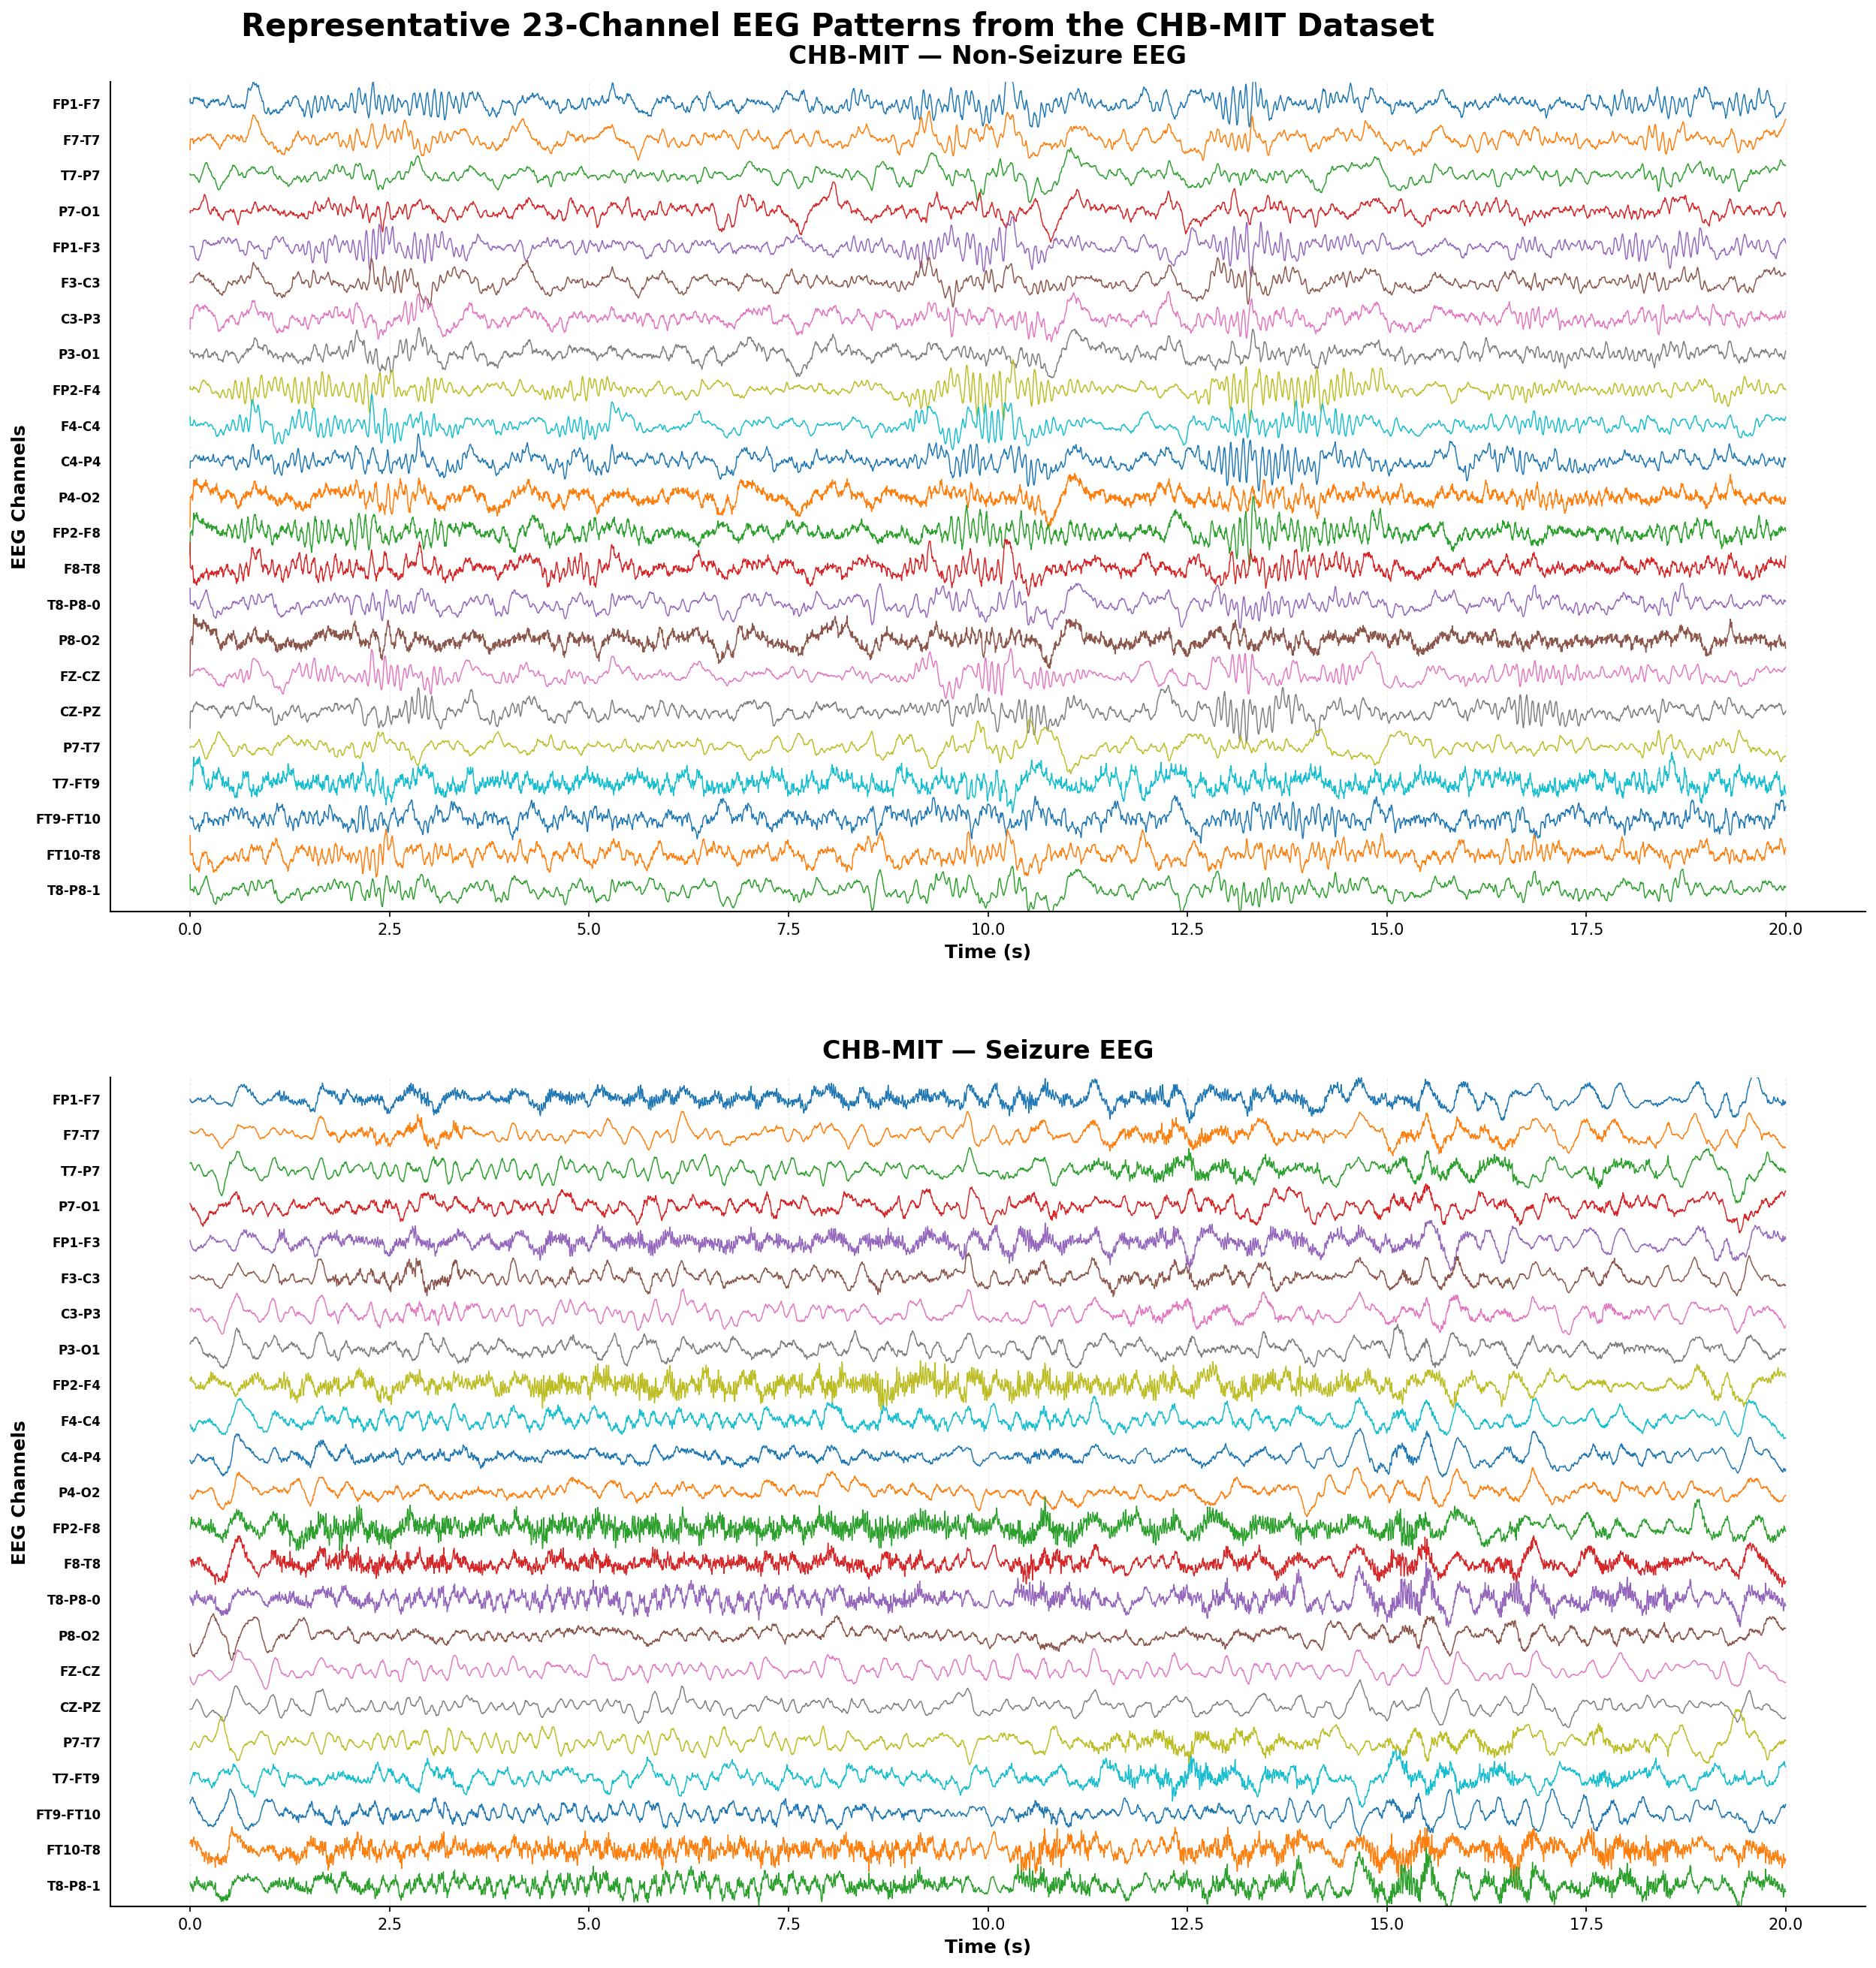


✓ CHB-MIT 23-CHANNEL FIGURE GENERATED

Selected EDF:
/kaggle/input/datasets/abhishekinnvonix/seizure-epilepcy-chb-mit-eeg-dataset-pediatric/chb-mit-scalp-eeg-database-1.0.0/chb01/chb01_03.edf

Number of channels plotted:
23

Channels:
01. FP1-F7
02. F7-T7
03. T7-P7
04. P7-O1
05. FP1-F3
06. F3-C3
07. C3-P3
08. P3-O1
09. FP2-F4
10. F4-C4
11. C4-P4
12. P4-O2
13. FP2-F8
14. F8-T8
15. T8-P8-0
16. P8-O2
17. FZ-CZ
18. CZ-PZ
19. P7-T7
20. T7-FT9
21. FT9-FT10
22. FT10-T8
23. T8-P8-1

Saved:
/kaggle/working/Figure_CHBMIT_23Channel_Seizure_vs_NonSeizure.png
/kaggle/working/Figure_CHBMIT_23Channel_Seizure_vs_NonSeizure.pdf
/kaggle/working/Figure_CHBMIT_23Channel_Seizure_vs_NonSeizure.svg


In [58]:
# ============================================================
# CHB-MIT — 23-CHANNEL SEIZURE vs NON-SEIZURE EEG
# CLEAR CHANNEL LABELS — JOURNAL QUALITY
# ============================================================

import os
import re
import glob
import numpy as np
import matplotlib.pyplot as plt
import mne

mne.set_log_level("ERROR")

# ============================================================
# 1. DATA PATH
# ============================================================

DATA_ROOT = (
    "/kaggle/input/datasets/abhishekinnvonix/"
    "seizure-epilepcy-chb-mit-eeg-dataset-pediatric/"
    "chb-mit-scalp-eeg-database-1.0.0"
)

OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 100)
print("CHB-MIT — 23-CHANNEL SEIZURE vs NON-SEIZURE EEG")
print("=" * 100)


# ============================================================
# 2. FIND EDF FILES
# ============================================================

edf_files = sorted(
    glob.glob(
        os.path.join(DATA_ROOT, "chb*", "*.edf")
    )
)

print("\nEDF files found :", len(edf_files))


# ============================================================
# 3. PARSE CHB-MIT SUMMARY FILES
# ============================================================

def parse_summary_file(summary_file):

    annotations = {}

    current_file = None
    pending_start = None

    with open(summary_file, "r", errors="ignore") as f:

        for line in f:

            line = line.strip()

            # --------------------------------------------
            # EDF filename
            # --------------------------------------------
            if line.startswith("File Name:"):

                current_file = line.split(
                    ":", 1
                )[1].strip()

                annotations[current_file] = []

                pending_start = None

            # --------------------------------------------
            # Seizure start
            # --------------------------------------------
            elif "Seizure Start Time:" in line:

                match = re.search(
                    r"Seizure Start Time:\s*([\d.]+)",
                    line
                )

                if match:
                    pending_start = float(
                        match.group(1)
                    )

            # --------------------------------------------
            # Seizure end
            # --------------------------------------------
            elif "Seizure End Time:" in line:

                match = re.search(
                    r"Seizure End Time:\s*([\d.]+)",
                    line
                )

                if (
                    match
                    and current_file is not None
                    and pending_start is not None
                ):

                    seizure_end = float(
                        match.group(1)
                    )

                    annotations[current_file].append(
                        (
                            pending_start,
                            seizure_end
                        )
                    )

                    pending_start = None

    return annotations


# ============================================================
# 4. READ ALL SUMMARY FILES
# ============================================================

summary_files = sorted(
    glob.glob(
        os.path.join(
            DATA_ROOT,
            "chb*",
            "*-summary.txt"
        )
    )
)

print(
    "Summary files found :",
    len(summary_files)
)

all_annotations = {}

for summary_file in summary_files:

    parsed = parse_summary_file(
        summary_file
    )

    all_annotations.update(parsed)


# ============================================================
# 5. FIND SEIZURE RECORDS
# ============================================================

seizure_candidates = []

for edf in edf_files:

    filename = os.path.basename(edf)

    if filename in all_annotations:

        intervals = all_annotations[filename]

        if len(intervals) > 0:

            seizure_candidates.append(
                (
                    edf,
                    intervals
                )
            )


print(
    "Seizure EDF candidates :",
    len(seizure_candidates)
)

if len(seizure_candidates) == 0:

    raise RuntimeError(
        "No seizure recordings with valid "
        "summary annotations were found."
    )


# ============================================================
# 6. SELECT REPRESENTATIVE SEIZURE RECORD
# ============================================================

preferred_records = [
    "chb01_03.edf",
    "chb01_04.edf",
    "chb01_15.edf",
    "chb01_16.edf",
    "chb01_18.edf"
]

selected = None

for preferred in preferred_records:

    for item in seizure_candidates:

        if os.path.basename(item[0]) == preferred:

            selected = item
            break

    if selected is not None:
        break


if selected is None:
    selected = seizure_candidates[0]


seizure_edf, seizure_intervals = selected

print("\n" + "-" * 100)
print("SELECTED SEIZURE RECORD")
print("-" * 100)

print("EDF:")
print(seizure_edf)

print("\nSeizure intervals:")

for start, end in seizure_intervals:

    print(
        f"{start:.2f} s  →  {end:.2f} s"
    )


# ============================================================
# 7. LOAD ORIGINAL EDF
# ============================================================

raw = mne.io.read_raw_edf(
    seizure_edf,
    preload=True,
    verbose=False
)

print("\nSampling frequency :",
      raw.info["sfreq"], "Hz")

print(
    "Recording duration :",
    round(raw.times[-1], 2),
    "seconds"
)

print(
    "Total EDF channels :",
    len(raw.ch_names)
)


# ============================================================
# 8. GET ACTUAL EEG CHANNELS FROM EDF
# ============================================================

# IMPORTANT:
# We use MNE's channel-type information instead of
# manually guessing channel names.

eeg_picks = mne.pick_types(
    raw.info,
    eeg=True,
    meg=False,
    ecg=False,
    emg=False,
    eog=False,
    stim=False,
    misc=False,
    exclude="bads"
)

eeg_channels = [
    raw.ch_names[i]
    for i in eeg_picks
]


print("\nActual EEG channels found :",
      len(eeg_channels))

for i, ch in enumerate(eeg_channels, 1):

    print(
        f"{i:02d}. {ch}"
    )


# ============================================================
# 9. SELECT EXACTLY 23 EEG CHANNELS
# ============================================================

if len(eeg_channels) < 23:

    raise RuntimeError(
        f"This EDF contains only "
        f"{len(eeg_channels)} EEG channels."
    )


# Use the first 23 REAL EEG channels from this EDF.
#
# This is much safer than manually constructing a channel
# list because every plotted label corresponds directly
# to the actual EDF channel.

selected_channels = eeg_channels[:23]

print("\n" + "=" * 100)
print("FINAL 23 CHANNELS USED FOR FIGURE")
print("=" * 100)

for i, ch in enumerate(
    selected_channels,
    1
):

    print(
        f"{i:02d}. {ch}"
    )


# ============================================================
# 10. SELECT FIRST SEIZURE INTERVAL
# ============================================================

seizure_start, seizure_end = (
    seizure_intervals[0]
)

print("\nSelected seizure:")
print(
    f"{seizure_start:.2f} → "
    f"{seizure_end:.2f} seconds"
)


# ============================================================
# 11. 20-SECOND SEIZURE WINDOW
# ============================================================

WINDOW_SEC = 20.0

recording_duration = raw.times[-1]


seizure_center = (
    seizure_start + seizure_end
) / 2.0


seizure_plot_start = (
    seizure_center
    - WINDOW_SEC / 2
)

seizure_plot_end = (
    seizure_center
    + WINDOW_SEC / 2
)


# Keep inside recording
if seizure_plot_start < 0:

    seizure_plot_start = 0
    seizure_plot_end = WINDOW_SEC


if seizure_plot_end > recording_duration:

    seizure_plot_end = recording_duration

    seizure_plot_start = (
        recording_duration
        - WINDOW_SEC
    )


# ============================================================
# 12. FIND NON-SEIZURE WINDOW
# ============================================================

nonseizure_start = None

candidate_times = np.arange(
    0,
    recording_duration - WINDOW_SEC,
    WINDOW_SEC
)

for candidate in candidate_times:

    candidate_end = (
        candidate + WINDOW_SEC
    )

    overlaps = False

    for sz_start, sz_end in seizure_intervals:

        if (
            candidate < sz_end
            and candidate_end > sz_start
        ):

            overlaps = True
            break

    if not overlaps:

        # Prefer a window sufficiently away
        # from the seizure.
        distance = min(
            abs(candidate - sz_start)
            for sz_start, _ in seizure_intervals
        )

        if distance >= 60:

            nonseizure_start = candidate
            break


# Fallback
if nonseizure_start is None:

    for candidate in candidate_times:

        candidate_end = (
            candidate + WINDOW_SEC
        )

        overlaps = False

        for sz_start, sz_end in seizure_intervals:

            if (
                candidate < sz_end
                and candidate_end > sz_start
            ):

                overlaps = True
                break

        if not overlaps:

            nonseizure_start = candidate
            break


if nonseizure_start is None:

    raise RuntimeError(
        "Could not find a non-seizure window."
    )


nonseizure_plot_end = (
    nonseizure_start + WINDOW_SEC
)


print("\n" + "=" * 100)
print("FINAL PLOTTING WINDOWS")
print("=" * 100)

print(
    "Non-Seizure :",
    f"{nonseizure_start:.2f} – "
    f"{nonseizure_plot_end:.2f} s"
)

print(
    "Seizure     :",
    f"{seizure_plot_start:.2f} – "
    f"{seizure_plot_end:.2f} s"
)


# ============================================================
# 13. EXTRACT SIGNALS
# ============================================================

sfreq = raw.info["sfreq"]

# -------------------------------
# Non-seizure
# -------------------------------

nonseizure_data = raw.get_data(
    picks=selected_channels,
    start=int(
        nonseizure_start * sfreq
    ),
    stop=int(
        nonseizure_plot_end * sfreq
    )
)


# -------------------------------
# Seizure
# -------------------------------

seizure_data = raw.get_data(
    picks=selected_channels,
    start=int(
        seizure_plot_start * sfreq
    ),
    stop=int(
        seizure_plot_end * sfreq
    )
)


# Convert volts → microvolts
nonseizure_data *= 1e6
seizure_data *= 1e6


# ============================================================
# 14. NORMALIZE EACH CHANNEL
# ============================================================

def normalize_channels(data):

    normalized = np.zeros_like(
        data,
        dtype=np.float64
    )

    for i in range(data.shape[0]):

        signal = data[i]

        median = np.median(signal)

        centered = signal - median

        scale = np.percentile(
            np.abs(centered),
            95
        )

        if scale < 1e-12:
            scale = 1.0

        normalized[i] = (
            centered / scale
        )

    return normalized


nonseizure_plot = normalize_channels(
    nonseizure_data
)

seizure_plot = normalize_channels(
    seizure_data
)


# ============================================================
# 15. TIME AXES
# ============================================================

nonseizure_time = (
    np.arange(
        nonseizure_plot.shape[1]
    ) / sfreq
)

seizure_time = (
    np.arange(
        seizure_plot.shape[1]
    ) / sfreq
)


# ============================================================
# 16. PLOT FUNCTION
# ============================================================

def plot_eeg_montage(
    ax,
    data,
    time,
    channels,
    title
):

    n_channels = len(channels)

    # Distance between traces
    spacing = 2.5

    # Bottom → top positions
    positions = (
        np.arange(n_channels)
        * spacing
    )

    # --------------------------------------------------------
    # Plot every channel
    # --------------------------------------------------------

    for i in range(n_channels):

        y = (
            data[i]
            + positions[i]
        )

        ax.plot(
            time,
            y,
            linewidth=0.70,
            antialiased=True
        )


    # --------------------------------------------------------
    # CRITICAL FIX:
    # Use Y-axis ticks for labels.
    #
    # Each label is mathematically tied to the exact
    # corresponding trace position.
    # --------------------------------------------------------

    ax.set_yticks(
        positions
    )

    ax.set_yticklabels(
        channels,
        fontsize=8,
        fontweight="bold"
    )


    # --------------------------------------------------------
    # Keep first channel at top
    # --------------------------------------------------------

    ax.invert_yaxis()


    # --------------------------------------------------------
    # Title
    # --------------------------------------------------------

    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold",
        pad=12
    )


    # --------------------------------------------------------
    # Grid
    # --------------------------------------------------------

    ax.grid(
        axis="x",
        linestyle="--",
        linewidth=0.6,
        alpha=0.25
    )


    # --------------------------------------------------------
    # Remove horizontal grid
    # --------------------------------------------------------

    ax.grid(
        axis="y",
        visible=False
    )


    # --------------------------------------------------------
    # Make labels stay inside figure
    # --------------------------------------------------------

    ax.tick_params(
        axis="y",
        which="both",
        length=0,
        pad=6
    )

    ax.tick_params(
        axis="x",
        labelsize=10
    )


    # --------------------------------------------------------
    # Limits
    # --------------------------------------------------------

    ax.set_ylim(
        positions[-1] + spacing * 0.6,
        -spacing * 0.6
    )


# ============================================================
# 17. CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(19, 18),
    sharex=False
)


# ============================================================
# 18. NON-SEIZURE PANEL
# ============================================================

plot_eeg_montage(
    axes[0],
    nonseizure_plot,
    nonseizure_time,
    selected_channels,
    "CHB-MIT — Non-Seizure EEG"
)


# ============================================================
# 19. SEIZURE PANEL
# ============================================================

plot_eeg_montage(
    axes[1],
    seizure_plot,
    seizure_time,
    selected_channels,
    "CHB-MIT — Seizure EEG"
)


# ============================================================
# 20. X LABELS
# ============================================================

axes[0].set_xlabel(
    "Time (s)",
    fontsize=12,
    fontweight="bold"
)

axes[1].set_xlabel(
    "Time (s)",
    fontsize=12,
    fontweight="bold"
)


# ============================================================
# 21. Y LABEL
# ============================================================

axes[0].set_ylabel(
    "EEG Channels",
    fontsize=12,
    fontweight="bold"
)

axes[1].set_ylabel(
    "EEG Channels",
    fontsize=12,
    fontweight="bold"
)


# ============================================================
# 22. MAIN TITLE
# ============================================================

fig.suptitle(
    "Representative 23-Channel EEG Patterns "
    "from the CHB-MIT Dataset",
    fontsize=20,
    fontweight="bold",
    y=0.995
)


# ============================================================
# 23. LAYOUT
# ============================================================

plt.subplots_adjust(
    left=0.16,
    right=0.98,
    top=0.96,
    bottom=0.06,
    hspace=0.20
)


# ============================================================
# 24. SAVE
# ============================================================

png_path = os.path.join(
    OUTPUT_DIR,
    "Figure_CHBMIT_23Channel_Seizure_vs_NonSeizure.png"
)

pdf_path = os.path.join(
    OUTPUT_DIR,
    "Figure_CHBMIT_23Channel_Seizure_vs_NonSeizure.pdf"
)

svg_path = os.path.join(
    OUTPUT_DIR,
    "Figure_CHBMIT_23Channel_Seizure_vs_NonSeizure.svg"
)


plt.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.savefig(
    svg_path,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# 25. FINAL REPORT
# ============================================================

print("\n" + "=" * 100)
print("✓ CHB-MIT 23-CHANNEL FIGURE GENERATED")
print("=" * 100)

print("\nSelected EDF:")
print(seizure_edf)

print("\nNumber of channels plotted:")
print(len(selected_channels))

print("\nChannels:")

for i, ch in enumerate(
    selected_channels,
    1
):

    print(
        f"{i:02d}. {ch}"
    )

print("\nSaved:")

print(png_path)
print(pdf_path)
print(svg_path)

print("=" * 100)

TUH MATCHED RECORDINGS
Matched EDF + CSV: 310

Searching artifact annotations...

✓ EYEM  : aaaaadao_s001_t004.edf
    Interval: 39.378 - 49.798 sec
✓ MUSC  : aaaaadao_s001_t004.edf
    Interval: 0.045 - 65.730 sec
✓ ELEC  : aaaaabnn_s002_t004.edf
    Interval: 4.028 - 26.845 sec
✓ CHEW  : aaaaafhl_s003_t000.edf
    Interval: 192.938 - 205.833 sec

✓ Non-artifact recording: aaaaabnn_s002_t004.edf
  Interval: 43.000 - 50.000 sec


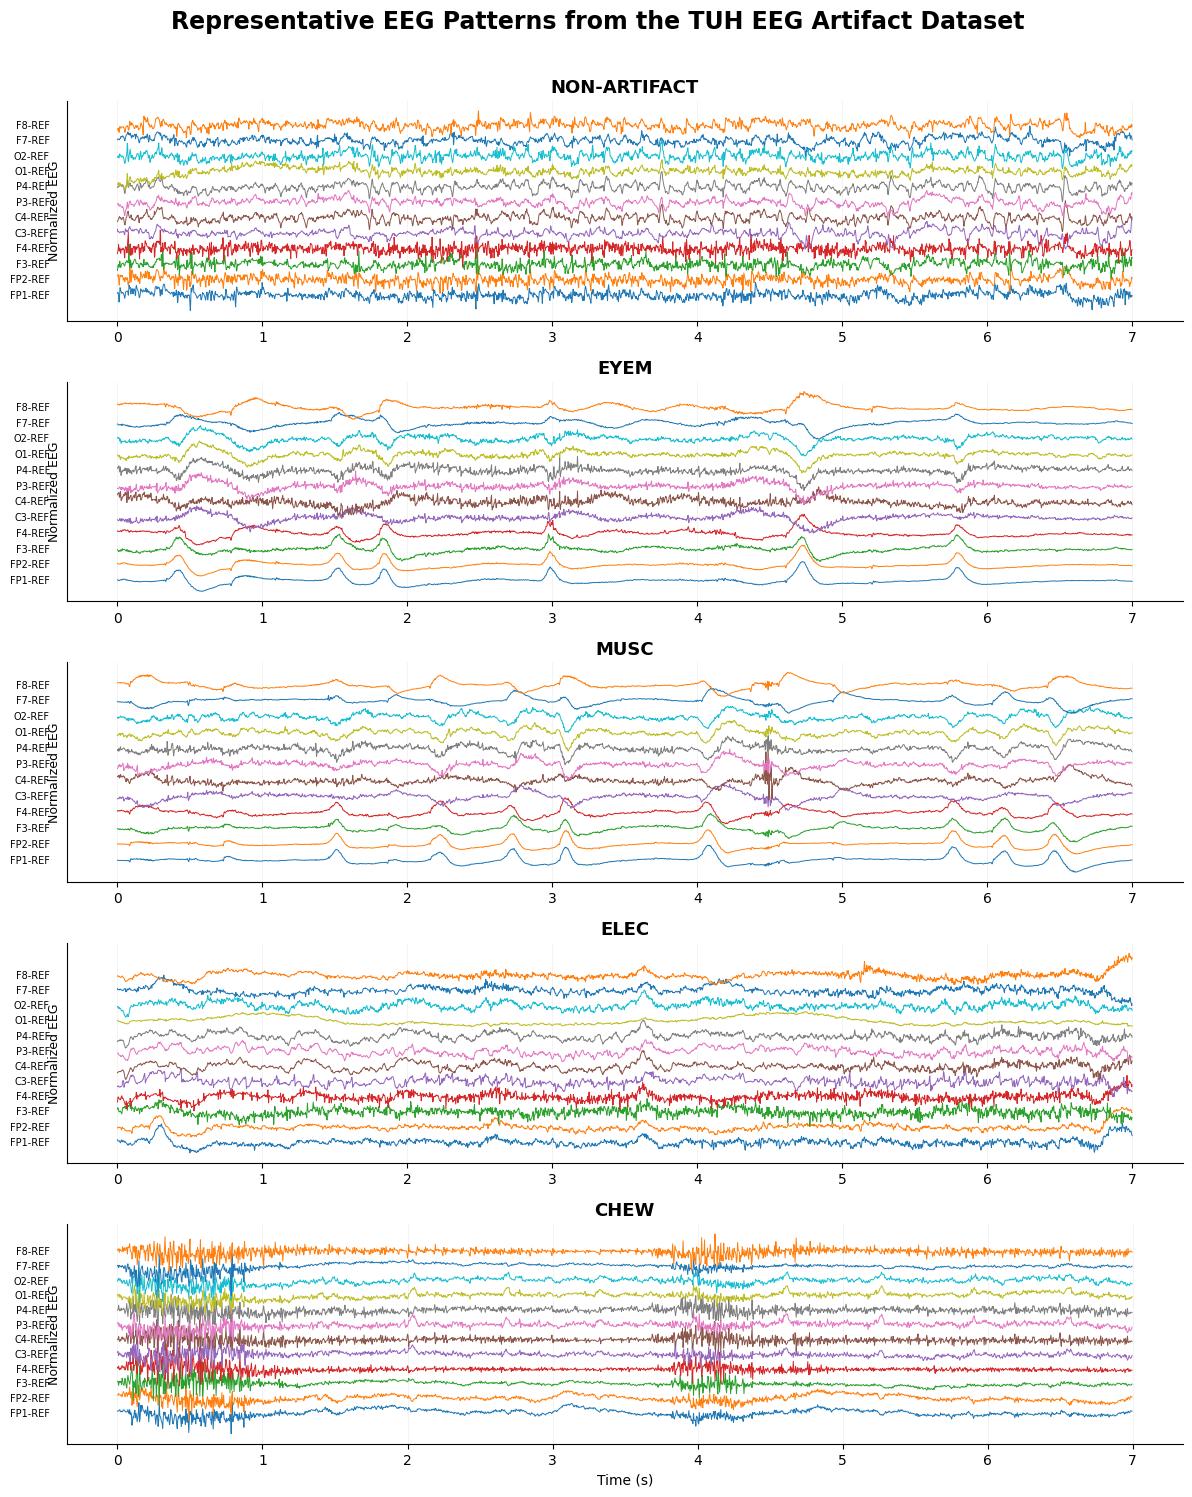


FIGURE 1 COMPLETE
PNG: /kaggle/working/journal_figures/Figure_1_TUH_Artifact_Patterns.png
PDF: /kaggle/working/journal_figures/Figure_1_TUH_Artifact_Patterns.pdf


In [4]:
# ============================================================
# FIGURE 1 — TUH EEG ARTIFACT REPRESENTATIVE EXAMPLES
# Non-Artifact + EYEM + MUSC + ELEC + CHEW
# Searches the COMPLETE TUH ARTIFACT corpus
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import mne

# ------------------------------------------------------------
# 1. Plotting defaults
# ------------------------------------------------------------
mpl.rcdefaults()
mpl.rcParams["font.family"] = "DejaVu Sans"

# ------------------------------------------------------------
# 2. Paths
# ------------------------------------------------------------
TUH_ROOT = (
    "/kaggle/input/datasets/mohammadashrafshaik/"
    "tuh-eeg-artifact/tuh_eeg_artifact"
)

OUT_DIR = "/kaggle/working/journal_figures"
os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 3. Find all matched EDF + CSV files
# ------------------------------------------------------------
records = []

for root, dirs, files in os.walk(TUH_ROOT):

    for file in files:

        if not file.lower().endswith(".edf"):
            continue

        edf_path = os.path.join(root, file)

        csv_path = os.path.splitext(edf_path)[0] + ".csv"

        if os.path.exists(csv_path):

            records.append(
                (edf_path, csv_path)
            )

print("=" * 80)
print("TUH MATCHED RECORDINGS")
print("=" * 80)

print("Matched EDF + CSV:", len(records))


# ------------------------------------------------------------
# 4. Search the COMPLETE corpus for each artifact category
# ------------------------------------------------------------
ARTIFACTS = [
    "eyem",
    "musc",
    "elec",
    "chew"
]

artifact_sources = {}

print("\nSearching artifact annotations...\n")

for artifact in ARTIFACTS:

    found = None

    for edf_path, csv_path in records:

        try:

            ann = pd.read_csv(
                csv_path,
                comment="#"
            )

            ann.columns = [
                c.strip()
                for c in ann.columns
            ]

            if "label" not in ann.columns:
                continue

            ann["label"] = (
                ann["label"]
                .astype(str)
                .str.lower()
                .str.strip()
            )

            subset = ann[
                ann["label"] == artifact
            ].copy()

            if len(subset) == 0:
                continue

            subset = subset[
                ["start_time", "stop_time", "label"]
            ].dropna()

            subset["duration"] = (
                subset["stop_time"]
                - subset["start_time"]
            )

            # Prefer a reasonably long interval
            subset = subset[
                subset["duration"] >= 5.0
            ]

            if len(subset) == 0:
                continue

            # Select longest available interval
            row = subset.sort_values(
                "duration",
                ascending=False
            ).iloc[0]

            found = {
                "edf": edf_path,
                "csv": csv_path,
                "start": float(row["start_time"]),
                "stop": float(row["stop_time"]),
                "duration": float(row["duration"])
            }

            break

        except Exception as e:
            continue

    if found is None:

        print(
            f"✗ {artifact.upper()} not found"
        )

    else:

        artifact_sources[artifact] = found

        print(
            f"✓ {artifact.upper():5s} : "
            f"{os.path.basename(found['edf'])}"
        )

        print(
            f"    Interval: "
            f"{found['start']:.3f} - "
            f"{found['stop']:.3f} sec"
        )


# ------------------------------------------------------------
# 5. Verify all four artifact categories were found
# ------------------------------------------------------------
missing = [
    a for a in ARTIFACTS
    if a not in artifact_sources
]

if missing:

    raise RuntimeError(
        "Could not find these artifact types: "
        + ", ".join(missing)
    )


# ------------------------------------------------------------
# 6. Common channels for visualization
# ------------------------------------------------------------
COMMON_CHANNELS = [
    "EEG FP1-REF",
    "EEG FP2-REF",
    "EEG F3-REF",
    "EEG F4-REF",
    "EEG C3-REF",
    "EEG C4-REF",
    "EEG P3-REF",
    "EEG P4-REF",
    "EEG O1-REF",
    "EEG O2-REF",
    "EEG F7-REF",
    "EEG F8-REF",
    "EEG T3-REF",
    "EEG T4-REF",
    "EEG T5-REF",
    "EEG T6-REF",
    "EEG FZ-REF",
    "EEG CZ-REF",
    "EEG PZ-REF"
]


# ------------------------------------------------------------
# 7. Load one segment
# ------------------------------------------------------------
def load_segment(
    edf_path,
    start,
    duration=7.0,
    max_channels=12
):

    raw = mne.io.read_raw_edf(
        edf_path,
        preload=True,
        verbose=False
    )

    available = [
        ch for ch in COMMON_CHANNELS
        if ch in raw.ch_names
    ]

    if len(available) < 8:

        # fallback: first EEG-like channels
        available = [
            ch for ch in raw.ch_names
            if "EEG" in ch.upper()
        ]

    channels = available[:max_channels]

    raw.pick(channels)

    # Don't exceed recording duration
    stop = min(
        start + duration,
        raw.times[-1]
    )

    segment = raw.copy().crop(
        tmin=start,
        tmax=stop,
        include_tmax=False
    )

    data = segment.get_data()

    sfreq = segment.info["sfreq"]

    times = np.arange(
        data.shape[1]
    ) / sfreq

    channel_names = segment.ch_names

    del segment
    del raw
    gc.collect()

    return times, data, channel_names


# ------------------------------------------------------------
# 8. Normalize channels only for visualization
# ------------------------------------------------------------
def normalize_for_plot(data):

    data = data.astype(
        np.float64
    )

    output = np.zeros_like(data)

    for i in range(data.shape[0]):

        x = data[i]

        mean = np.mean(x)
        std = np.std(x)

        if std > 0:

            output[i] = (
                (x - mean) / std
            )

        else:

            output[i] = (
                x - mean
            )

    return output


# ------------------------------------------------------------
# 9. Load artifact examples
# ------------------------------------------------------------
segments = {}

for artifact in ARTIFACTS:

    info = artifact_sources[artifact]

    times, data, channels = load_segment(
        info["edf"],
        info["start"],
        duration=7.0,
        max_channels=12
    )

    segments[
        artifact.upper()
    ] = {
        "times": times,
        "data": normalize_for_plot(data),
        "channels": channels
    }


# ------------------------------------------------------------
# 10. Find a genuine non-artifact segment
# ------------------------------------------------------------
# Use the first suitable recording and ensure the selected
# interval does not overlap any annotated artifact.

def find_clean_interval(
    edf_path,
    csv_path,
    duration=7.0
):

    ann = pd.read_csv(
        csv_path,
        comment="#"
    )

    ann.columns = [
        c.strip()
        for c in ann.columns
    ]

    intervals = (
        ann[
            ["start_time", "stop_time"]
        ]
        .dropna()
        .astype(float)
        .values
    )

    raw = mne.io.read_raw_edf(
        edf_path,
        preload=False,
        verbose=False
    )

    total_duration = raw.times[-1]

    del raw
    gc.collect()

    def overlaps(start, stop):

        for a, b in intervals:

            if start < b and stop > a:
                return True

        return False

    # Search every 1 second
    for start in np.arange(
        0,
        total_duration - duration,
        1.0
    ):

        stop = start + duration

        if not overlaps(
            start,
            stop
        ):

            return float(start)

    return None


clean_found = None

for edf_path, csv_path in records:

    try:

        start = find_clean_interval(
            edf_path,
            csv_path,
            duration=7.0
        )

        if start is not None:

            clean_found = {
                "edf": edf_path,
                "csv": csv_path,
                "start": start
            }

            break

    except Exception:
        continue


if clean_found is None:

    raise RuntimeError(
        "Could not find a clean non-artifact interval."
    )

print(
    "\n✓ Non-artifact recording:",
    os.path.basename(
        clean_found["edf"]
    )
)

print(
    "  Interval:",
    f"{clean_found['start']:.3f} - "
    f"{clean_found['start'] + 7:.3f} sec"
)


# ------------------------------------------------------------
# 11. Load clean segment
# ------------------------------------------------------------
times, data, channels = load_segment(
    clean_found["edf"],
    clean_found["start"],
    duration=7.0,
    max_channels=12
)

segments["NON-ARTIFACT"] = {
    "times": times,
    "data": normalize_for_plot(data),
    "channels": channels
}


# ------------------------------------------------------------
# 12. Plot the final journal figure
# ------------------------------------------------------------
order = [
    "NON-ARTIFACT",
    "EYEM",
    "MUSC",
    "ELEC",
    "CHEW"
]

fig, axes = plt.subplots(
    5,
    1,
    figsize=(12, 15),
    sharex=False
)

for ax, label in zip(
    axes,
    order
):

    item = segments[label]

    times = item["times"]
    data = item["data"]
    channels = item["channels"]

    spacing = 4.0

    for i in range(
        data.shape[0]
    ):

        offset = i * spacing

        ax.plot(
            times,
            data[i] + offset,
            linewidth=0.7
        )

        ax.text(
            -0.015,
            offset,
            channels[i].replace(
                "EEG ",
                ""
            ),
            transform=ax.get_yaxis_transform(),
            ha="right",
            va="center",
            fontsize=7
        )

    ax.set_title(
        label,
        fontsize=13,
        fontweight="bold",
        pad=6
    )

    ax.set_yticks([])

    ax.set_ylabel(
        "Normalized EEG",
        fontsize=9
    )

    ax.grid(
        axis="x",
        alpha=0.20,
        linewidth=0.5
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


axes[-1].set_xlabel(
    "Time (s)",
    fontsize=10
)

fig.suptitle(
    "Representative EEG Patterns from the TUH EEG Artifact Dataset",
    fontsize=17,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(
    rect=[0, 0, 1, 0.985]
)


# ------------------------------------------------------------
# 13. Save high-resolution journal versions
# ------------------------------------------------------------
png_path = os.path.join(
    OUT_DIR,
    "Figure_1_TUH_Artifact_Patterns.png"
)

pdf_path = os.path.join(
    OUT_DIR,
    "Figure_1_TUH_Artifact_Patterns.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\n" + "=" * 80)
print("FIGURE 1 COMPLETE")
print("=" * 80)
print("PNG:", png_path)
print("PDF:", pdf_path)

CHB-MIT — SINGLE 23-CHANNEL RAW EEG FIGURE

EDF files found : 686
Summary files found : 24
Seizure EDF candidates : 36

----------------------------------------------------------------------------------------------------
SELECTED REPRESENTATIVE SEIZURE RECORD
----------------------------------------------------------------------------------------------------
EDF:
/kaggle/input/datasets/abhishekinnvonix/seizure-epilepcy-chb-mit-eeg-dataset-pediatric/chb-mit-scalp-eeg-database-1.0.0/chb01/chb01_03.edf

Seizure intervals:
2996.00 s  →  3036.00 s


/tmp/ipykernel_58/4150722955.py:352: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(



----------------------------------------------------------------------------------------------------
RAW EDF INFORMATION
----------------------------------------------------------------------------------------------------
Sampling frequency : 256.0 Hz
Recording duration : 3600.0 seconds
Total EDF channels : 23

Actual EEG channels found : 23
01. FP1-F7
02. F7-T7
03. T7-P7
04. P7-O1
05. FP1-F3
06. F3-C3
07. C3-P3
08. P3-O1
09. FP2-F4
10. F4-C4
11. C4-P4
12. P4-O2
13. FP2-F8
14. F8-T8
15. T8-P8-0
16. P8-O2
17. FZ-CZ
18. CZ-PZ
19. P7-T7
20. T7-FT9
21. FT9-FT10
22. FT10-T8
23. T8-P8-1

FINAL 23 EEG CHANNELS USED FOR FIGURE
01. FP1-F7
02. F7-T7
03. T7-P7
04. P7-O1
05. FP1-F3
06. F3-C3
07. C3-P3
08. P3-O1
09. FP2-F4
10. F4-C4
11. C4-P4
12. P4-O2
13. FP2-F8
14. F8-T8
15. T8-P8-0
16. P8-O2
17. FZ-CZ
18. CZ-PZ
19. P7-T7
20. T7-FT9
21. FT9-FT10
22. FT10-T8
23. T8-P8-1

----------------------------------------------------------------------------------------------------
SELECTED SEIZURE INTERVAL


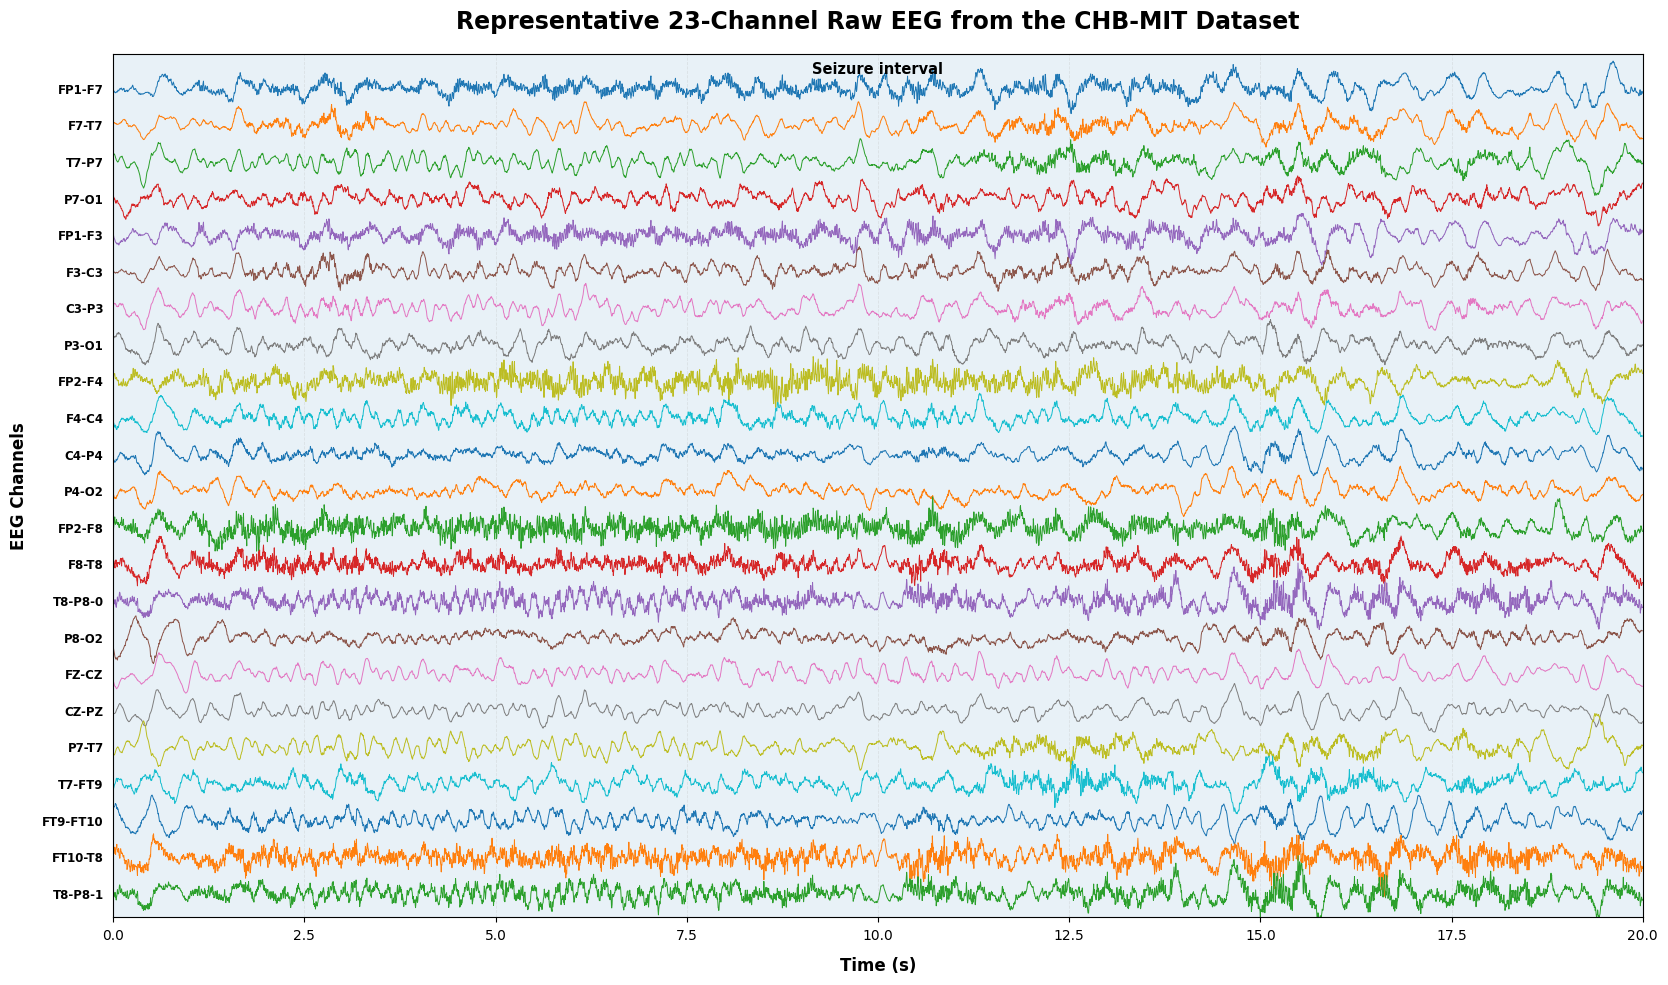


✓ SINGLE 23-CHANNEL RAW EEG FIGURE GENERATED

Selected EDF:
/kaggle/input/datasets/abhishekinnvonix/seizure-epilepcy-chb-mit-eeg-dataset-pediatric/chb-mit-scalp-eeg-database-1.0.0/chb01/chb01_03.edf

Number of channels plotted:
23

Channels:
01. FP1-F7
02. F7-T7
03. T7-P7
04. P7-O1
05. FP1-F3
06. F3-C3
07. C3-P3
08. P3-O1
09. FP2-F4
10. F4-C4
11. C4-P4
12. P4-O2
13. FP2-F8
14. F8-T8
15. T8-P8-0
16. P8-O2
17. FZ-CZ
18. CZ-PZ
19. P7-T7
20. T7-FT9
21. FT9-FT10
22. FT10-T8
23. T8-P8-1

Raw EEG window:
3006.00 – 3026.00 seconds

Actual seizure interval:
2996.00 – 3036.00 seconds

Displayed seizure portion:
0.00 – 20.00 seconds

✓ Entire displayed EEG window is within the annotated seizure interval.

Saved files:
/kaggle/working/Figure_CHBMIT_23Channel_Raw_EEG.png
/kaggle/working/Figure_CHBMIT_23Channel_Raw_EEG.pdf
/kaggle/working/Figure_CHBMIT_23Channel_Raw_EEG.svg


In [8]:
# ============================================================
# CHB-MIT — SINGLE 23-CHANNEL RAW EEG FIGURE
# JOURNAL-QUALITY REPRESENTATIVE RAW EEG
#
# Final version:
#   • One single raw EEG panel
#   • 23 actual EEG channels
#   • Original CHB-MIT EDF
#   • Representative seizure-containing window
#   • Correct seizure-interval visualization
#   • Clear channel labels
#   • No separate non-seizure panel
#   • 600 DPI PNG + PDF + SVG
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import re
import glob
import numpy as np

import matplotlib as mpl
import matplotlib.pyplot as plt

import mne


# ============================================================
# 2. MATPLOTLIB / MNE SETTINGS
# ============================================================

mne.set_log_level("ERROR")

# Reset matplotlib defaults
mpl.rcdefaults()

# Use an installed font
mpl.rcParams["font.family"] = "DejaVu Sans"


# ============================================================
# 3. DATA PATH
# ============================================================

DATA_ROOT = (
    "/kaggle/input/datasets/abhishekinnvonix/"
    "seizure-epilepcy-chb-mit-eeg-dataset-pediatric/"
    "chb-mit-scalp-eeg-database-1.0.0"
)

OUTPUT_DIR = "/kaggle/working"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


print("=" * 100)
print("CHB-MIT — SINGLE 23-CHANNEL RAW EEG FIGURE")
print("=" * 100)


# ============================================================
# 4. FIND ALL EDF FILES
# ============================================================

edf_files = sorted(
    glob.glob(
        os.path.join(
            DATA_ROOT,
            "chb*",
            "*.edf"
        )
    )
)

print(
    "\nEDF files found :",
    len(edf_files)
)


if len(edf_files) == 0:

    raise RuntimeError(
        "No CHB-MIT EDF files were found. "
        "Please check DATA_ROOT."
    )


# ============================================================
# 5. PARSE CHB-MIT SUMMARY FILES
# ============================================================

def parse_summary_file(summary_file):

    annotations = {}

    current_file = None
    pending_start = None


    with open(
        summary_file,
        "r",
        errors="ignore"
    ) as f:

        for line in f:

            line = line.strip()


            # ------------------------------------------------
            # EDF filename
            # ------------------------------------------------

            if line.startswith("File Name:"):

                current_file = line.split(
                    ":",
                    1
                )[1].strip()

                annotations[current_file] = []

                pending_start = None


            # ------------------------------------------------
            # Seizure start
            # ------------------------------------------------

            elif "Seizure Start Time:" in line:

                match = re.search(
                    r"Seizure Start Time:\s*([\d.]+)",
                    line
                )

                if match:

                    pending_start = float(
                        match.group(1)
                    )


            # ------------------------------------------------
            # Seizure end
            # ------------------------------------------------

            elif "Seizure End Time:" in line:

                match = re.search(
                    r"Seizure End Time:\s*([\d.]+)",
                    line
                )

                if (
                    match
                    and current_file is not None
                    and pending_start is not None
                ):

                    seizure_end = float(
                        match.group(1)
                    )

                    annotations[
                        current_file
                    ].append(
                        (
                            pending_start,
                            seizure_end
                        )
                    )

                    pending_start = None


    return annotations


# ============================================================
# 6. FIND SUMMARY FILES
# ============================================================

summary_files = sorted(
    glob.glob(
        os.path.join(
            DATA_ROOT,
            "chb*",
            "*-summary.txt"
        )
    )
)

print(
    "Summary files found :",
    len(summary_files)
)


if len(summary_files) == 0:

    raise RuntimeError(
        "No CHB-MIT summary files were found."
    )


# ============================================================
# 7. READ ALL SUMMARY FILES
# ============================================================

all_annotations = {}


for summary_file in summary_files:

    parsed = parse_summary_file(
        summary_file
    )

    all_annotations.update(
        parsed
    )


# ============================================================
# 8. FIND EDF FILES WITH SEIZURE ANNOTATIONS
# ============================================================

seizure_candidates = []


for edf in edf_files:

    filename = os.path.basename(
        edf
    )

    if filename in all_annotations:

        intervals = all_annotations[
            filename
        ]

        if len(intervals) > 0:

            seizure_candidates.append(
                (
                    edf,
                    intervals
                )
            )


print(
    "Seizure EDF candidates :",
    len(seizure_candidates)
)


if len(seizure_candidates) == 0:

    raise RuntimeError(
        "No seizure recordings with valid "
        "CHB-MIT summary annotations were found."
    )


# ============================================================
# 9. SELECT REPRESENTATIVE SEIZURE RECORD
# ============================================================

preferred_records = [

    "chb01_03.edf",
    "chb01_04.edf",
    "chb01_15.edf",
    "chb01_16.edf",
    "chb01_18.edf"

]


selected = None


for preferred in preferred_records:

    for item in seizure_candidates:

        if os.path.basename(
            item[0]
        ) == preferred:

            selected = item

            break

    if selected is not None:

        break


# ------------------------------------------------------------
# Fallback
# ------------------------------------------------------------

if selected is None:

    selected = seizure_candidates[0]


seizure_edf, seizure_intervals = selected


print("\n" + "-" * 100)
print("SELECTED REPRESENTATIVE SEIZURE RECORD")
print("-" * 100)

print(
    "EDF:"
)

print(
    seizure_edf
)

print(
    "\nSeizure intervals:"
)


for start, end in seizure_intervals:

    print(
        f"{start:.2f} s  →  {end:.2f} s"
    )


# ============================================================
# 10. LOAD ORIGINAL EDF
# ============================================================

raw = mne.io.read_raw_edf(
    seizure_edf,
    preload=True,
    verbose=False
)


print("\n" + "-" * 100)
print("RAW EDF INFORMATION")
print("-" * 100)

print(
    "Sampling frequency :",
    raw.info["sfreq"],
    "Hz"
)

print(
    "Recording duration :",
    round(
        raw.times[-1],
        2
    ),
    "seconds"
)

print(
    "Total EDF channels :",
    len(raw.ch_names)
)


# ============================================================
# 11. IDENTIFY ACTUAL EEG CHANNELS
# ============================================================

eeg_picks = mne.pick_types(
    raw.info,
    eeg=True,
    meg=False,
    ecg=False,
    emg=False,
    eog=False,
    stim=False,
    misc=False,
    exclude="bads"
)


eeg_channels = [

    raw.ch_names[i]

    for i in eeg_picks

]


print(
    "\nActual EEG channels found :",
    len(eeg_channels)
)


for i, ch in enumerate(
    eeg_channels,
    1
):

    print(
        f"{i:02d}. {ch}"
    )


# ============================================================
# 12. SELECT EXACTLY 23 REAL EEG CHANNELS
# ============================================================

if len(eeg_channels) < 23:

    raise RuntimeError(
        f"This EDF contains only "
        f"{len(eeg_channels)} EEG channels. "
        f"At least 23 EEG channels are required."
    )


selected_channels = eeg_channels[:23]


print("\n" + "=" * 100)
print("FINAL 23 EEG CHANNELS USED FOR FIGURE")
print("=" * 100)


for i, ch in enumerate(
    selected_channels,
    1
):

    print(
        f"{i:02d}. {ch}"
    )


# ============================================================
# 13. SELECT FIRST SEIZURE INTERVAL
# ============================================================

seizure_start, seizure_end = (
    seizure_intervals[0]
)


print("\n" + "-" * 100)
print("SELECTED SEIZURE INTERVAL")
print("-" * 100)


print(
    f"{seizure_start:.2f} → "
    f"{seizure_end:.2f} seconds"
)


# ============================================================
# 14. CREATE 20-SECOND SEIZURE WINDOW
# ============================================================

WINDOW_SEC = 20.0


recording_duration = raw.times[-1]


seizure_center = (
    seizure_start
    + seizure_end
) / 2.0


plot_start = (
    seizure_center
    - WINDOW_SEC / 2.0
)


plot_end = (
    seizure_center
    + WINDOW_SEC / 2.0
)


# ------------------------------------------------------------
# Keep window inside recording
# ------------------------------------------------------------

if plot_start < 0:

    plot_start = 0

    plot_end = WINDOW_SEC


if plot_end > recording_duration:

    plot_end = recording_duration

    plot_start = (
        recording_duration
        - WINDOW_SEC
    )


print("\n" + "=" * 100)
print("RAW EEG PLOTTING WINDOW")
print("=" * 100)


print(
    f"Window  : "
    f"{plot_start:.2f} – "
    f"{plot_end:.2f} seconds"
)


print(
    f"Seizure : "
    f"{seizure_start:.2f} – "
    f"{seizure_end:.2f} seconds"
)


# ============================================================
# 15. VERIFY WHETHER DISPLAYED WINDOW IS INSIDE SEIZURE
# ============================================================

window_inside_seizure = (

    plot_start >= seizure_start

    and

    plot_end <= seizure_end

)


if window_inside_seizure:

    print(
        "\n✓ The complete displayed 20-second "
        "window lies inside the seizure interval."
    )

else:

    print(
        "\n✓ The displayed window partially overlaps "
        "the seizure interval."
    )


# ============================================================
# 16. EXTRACT RAW EEG
# ============================================================

sfreq = raw.info["sfreq"]


raw_data = raw.get_data(
    picks=selected_channels,
    start=int(
        plot_start * sfreq
    ),
    stop=int(
        plot_end * sfreq
    )
)


# ============================================================
# 17. CONVERT VOLTS → MICROVOLTS
# ============================================================

raw_data = (
    raw_data * 1e6
)


# ============================================================
# 18. DISPLAY-ONLY NORMALIZATION
# ============================================================

def normalize_channels(data):

    normalized = np.zeros_like(
        data,
        dtype=np.float64
    )


    for i in range(
        data.shape[0]
    ):

        signal = data[i]


        # Remove channel-specific baseline
        median = np.median(
            signal
        )


        centered = (
            signal - median
        )


        # Robust scaling for visualization
        scale = np.percentile(
            np.abs(centered),
            95
        )


        if scale < 1e-12:

            scale = 1.0


        normalized[i] = (
            centered / scale
        )


    return normalized


raw_plot = normalize_channels(
    raw_data
)


# ============================================================
# 19. CREATE TIME AXIS
# ============================================================

time = (
    np.arange(
        raw_plot.shape[1]
    )
    / sfreq
)


# ============================================================
# 20. CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(19, 11)
)


# ============================================================
# 21. CHANNEL POSITIONS
# ============================================================

n_channels = len(
    selected_channels
)


spacing = 2.5


positions = (
    np.arange(
        n_channels
    )
    * spacing
)


# ============================================================
# 22. PLOT ALL 23 RAW EEG CHANNELS
# ============================================================

for i in range(
    n_channels
):

    y = (
        raw_plot[i]
        + positions[i]
    )


    ax.plot(
        time,
        y,
        linewidth=0.70,
        antialiased=True
    )


# ============================================================
# 23. CHANNEL LABELS
# ============================================================

ax.set_yticks(
    positions
)


ax.set_yticklabels(
    selected_channels,
    fontsize=8.5,
    fontweight="bold"
)


# First channel at top
ax.invert_yaxis()


# ============================================================
# 24. CORRECT SEIZURE-INTERVAL DISPLAY
# ============================================================
#
# IMPORTANT:
#
# Example:
#   Actual seizure = 2996–3036 s
#   Displayed window = 3006–3026 s
#
# Therefore:
#   The ENTIRE displayed window is seizure.
#
# We shade the complete 0–20 s region.
# ============================================================

relative_seizure_start = (
    max(
        seizure_start,
        plot_start
    )
    - plot_start
)


relative_seizure_end = (
    min(
        seizure_end,
        plot_end
    )
    - plot_start
)


# ------------------------------------------------------------
# Shade the seizure portion
# ------------------------------------------------------------

if (
    relative_seizure_end
    > relative_seizure_start
):

    ax.axvspan(
        relative_seizure_start,
        relative_seizure_end,
        alpha=0.10,
        zorder=0
    )


# ============================================================
# 25. PLACE "SEIZURE INTERVAL" ABOVE THE FIRST TRACE
# ============================================================
#
# The label is deliberately placed above the first EEG trace
# so it does NOT overlap:
#
#   • EEG waveform
#   • channel labels
#   • Time (s)
#
# It remains inside the figure and below the title.
# ============================================================

if (
    relative_seizure_end
    > relative_seizure_start
):

    label_x = (
        relative_seizure_start
        + relative_seizure_end
    ) / 2.0


    # Extra space above first channel
    label_y = -1.35


    ax.text(
        label_x,
        label_y,
        "Seizure interval",
        ha="center",
        va="center",
        fontsize=10.5,
        fontweight="bold",
        clip_on=False
    )


# ============================================================
# 26. X-AXIS
# ============================================================

ax.set_xlim(
    0,
    WINDOW_SEC
)


ax.set_xlabel(
    "Time (s)",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)


# ============================================================
# 27. Y-AXIS
# ============================================================

ax.set_ylabel(
    "EEG Channels",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)


# ============================================================
# 28. TITLE
# ============================================================

ax.set_title(
    "Representative 23-Channel Raw EEG from the CHB-MIT Dataset",
    fontsize=17,
    fontweight="bold",
    pad=18
)


# ============================================================
# 29. GRID
# ============================================================

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)


ax.grid(
    axis="y",
    visible=False
)


# ============================================================
# 30. TICK FORMATTING
# ============================================================

ax.tick_params(
    axis="y",
    which="both",
    length=0,
    pad=7
)


ax.tick_params(
    axis="x",
    labelsize=10,
    pad=5
)


# ============================================================
# 31. Y-AXIS LIMITS
# ============================================================
#
# Extra space is reserved above the first channel for the
# seizure annotation.
# ============================================================

ax.set_ylim(
    positions[-1] + spacing * 0.65,
    -spacing * 0.95
)


# ============================================================
# 32. LAYOUT
# ============================================================

plt.subplots_adjust(
    left=0.18,
    right=0.985,
    top=0.89,
    bottom=0.105
)


# ============================================================
# 33. OUTPUT FILE PATHS
# ============================================================

png_path = os.path.join(
    OUTPUT_DIR,
    "Figure_CHBMIT_23Channel_Raw_EEG.png"
)


pdf_path = os.path.join(
    OUTPUT_DIR,
    "Figure_CHBMIT_23Channel_Raw_EEG.pdf"
)


svg_path = os.path.join(
    OUTPUT_DIR,
    "Figure_CHBMIT_23Channel_Raw_EEG.svg"
)


# ============================================================
# 34. SAVE PNG
# ============================================================

plt.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)


# ============================================================
# 35. SAVE PDF
# ============================================================

plt.savefig(
    pdf_path,
    bbox_inches="tight"
)


# ============================================================
# 36. SAVE SVG
# ============================================================

plt.savefig(
    svg_path,
    bbox_inches="tight"
)


# ============================================================
# 37. DISPLAY
# ============================================================

plt.show()


# ============================================================
# 38. FINAL REPORT
# ============================================================

print("\n" + "=" * 100)
print("✓ SINGLE 23-CHANNEL RAW EEG FIGURE GENERATED")
print("=" * 100)


print("\nSelected EDF:")
print(
    seizure_edf
)


print("\nNumber of channels plotted:")
print(
    len(selected_channels)
)


print("\nChannels:")

for i, ch in enumerate(
    selected_channels,
    1
):

    print(
        f"{i:02d}. {ch}"
    )


print("\nRaw EEG window:")

print(
    f"{plot_start:.2f} – "
    f"{plot_end:.2f} seconds"
)


print("\nActual seizure interval:")

print(
    f"{seizure_start:.2f} – "
    f"{seizure_end:.2f} seconds"
)


print("\nDisplayed seizure portion:")

print(
    f"{relative_seizure_start:.2f} – "
    f"{relative_seizure_end:.2f} seconds"
)


if window_inside_seizure:

    print(
        "\n✓ Entire displayed EEG window "
        "is within the annotated seizure interval."
    )


print("\nSaved files:")

print(
    png_path
)

print(
    pdf_path
)

print(
    svg_path
)


print("=" * 100)

CHB-MIT PROCESSED EEG — SINGLE 18-CHANNEL PANEL

Signal shape : (9505, 18, 2048)
Label shape  : (9505,)

Number of samples  : 9505
Number of channels : 18
Samples/channel    : 2048

Non-Seizure samples : 6924
Seizure samples     : 2581

----------------------------------------------------------------------------------------------------
SELECTED PROCESSED EEG SAMPLE
----------------------------------------------------------------------------------------------------
Sample index : 5939
Class        : SEIZURE
Sample shape : (18, 2048)

Sampling frequency : 256 Hz
Window duration    : 8.00 seconds


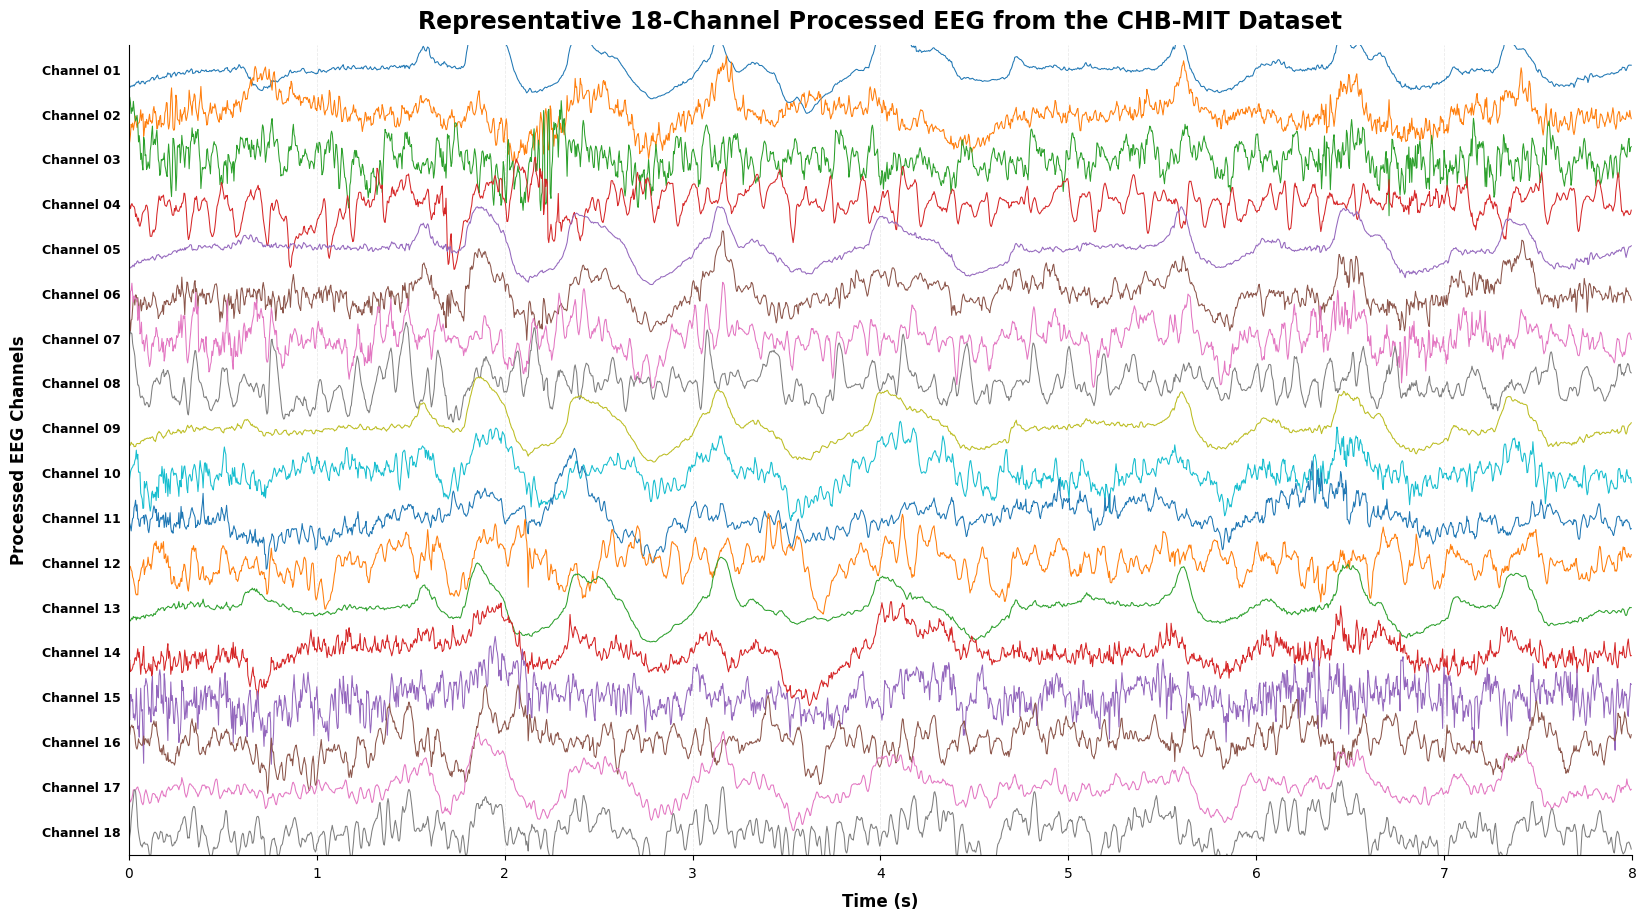


✓ SINGLE-PANEL 18-CHANNEL PROCESSED EEG GENERATED

Selected sample index : 5939
Sample class          : SEIZURE
Number of channels    : 18
Samples/channel       : 2048
Sampling frequency    : 256 Hz
Duration              : 8.00 seconds

Channel order:
01. Channel 01
02. Channel 02
03. Channel 03
04. Channel 04
05. Channel 05
06. Channel 06
07. Channel 07
08. Channel 08
09. Channel 09
10. Channel 10
11. Channel 11
12. Channel 12
13. Channel 13
14. Channel 14
15. Channel 15
16. Channel 16
17. Channel 17
18. Channel 18

Saved files:
/kaggle/working/Figure_CHB_MIT_Processed_18Channel.png
/kaggle/working/Figure_CHB_MIT_Processed_18Channel.pdf
/kaggle/working/Figure_CHB_MIT_Processed_18Channel.svg



In [1]:
# ============================================================
# CHB-MIT PROCESSED EEG
# SINGLE-PANEL 18-CHANNEL EEG FIGURE
# JOURNAL-QUALITY VERSION
#
# ONE PANEL ONLY
# ALL 18 CHANNELS STACKED TOGETHER
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import numpy as np

import matplotlib as mpl
import matplotlib.pyplot as plt


# ============================================================
# 2. MATPLOTLIB SETTINGS
# ============================================================

mpl.rcdefaults()

mpl.rcParams["font.family"] = "DejaVu Sans"


# ============================================================
# 3. DATA PATH
# ============================================================

ROOT = (
    "/kaggle/input/datasets/masahirogotoh/"
    "mit-chb-processed"
)

SIGNAL_FILE = os.path.join(
    ROOT,
    "signal_samples.npy"
)

LABEL_FILE = os.path.join(
    ROOT,
    "is_sz.npy"
)


# ============================================================
# 4. OUTPUT FILES
# ============================================================

OUT_PNG = (
    "/kaggle/working/"
    "Figure_CHB_MIT_Processed_18Channel.png"
)

OUT_PDF = (
    "/kaggle/working/"
    "Figure_CHB_MIT_Processed_18Channel.pdf"
)

OUT_SVG = (
    "/kaggle/working/"
    "Figure_CHB_MIT_Processed_18Channel.svg"
)


# ============================================================
# 5. LOAD DATA
# ============================================================

signals = np.load(
    SIGNAL_FILE,
    mmap_mode="r"
)

labels = np.load(
    LABEL_FILE
)


print("=" * 100)
print("CHB-MIT PROCESSED EEG — SINGLE 18-CHANNEL PANEL")
print("=" * 100)


print(
    "\nSignal shape :",
    signals.shape
)

print(
    "Label shape  :",
    labels.shape
)


# ============================================================
# 6. CHECK DATA STRUCTURE
# ============================================================

if signals.ndim != 3:

    raise ValueError(
        f"Expected 3-D signal array, "
        f"but found {signals.shape}"
    )


N, N_CHANNELS, N_SAMPLES = (
    signals.shape
)


print(
    "\nNumber of samples  :",
    N
)

print(
    "Number of channels :",
    N_CHANNELS
)

print(
    "Samples/channel    :",
    N_SAMPLES
)


if N_CHANNELS != 18:

    raise ValueError(
        f"Expected exactly 18 channels, "
        f"but found {N_CHANNELS}."
    )


# ============================================================
# 7. LABEL DISTRIBUTION
# ============================================================

non_seizure_indices = np.where(
    labels == False
)[0]

seizure_indices = np.where(
    labels == True
)[0]


print(
    "\nNon-Seizure samples :",
    len(non_seizure_indices)
)

print(
    "Seizure samples     :",
    len(seizure_indices)
)


if len(seizure_indices) == 0:

    raise RuntimeError(
        "No seizure-labeled samples were found."
    )


# ============================================================
# 8. SELECT REPRESENTATIVE SEIZURE SAMPLE
# ============================================================
#
# Deterministic selection.
# The middle seizure sample is selected so the figure is
# reproducible.
# ============================================================

sample_id = seizure_indices[
    len(seizure_indices) // 2
]


eeg = np.asarray(
    signals[sample_id],
    dtype=np.float64
)


print("\n" + "-" * 100)
print("SELECTED PROCESSED EEG SAMPLE")
print("-" * 100)


print(
    "Sample index :",
    sample_id
)

print(
    "Class        : SEIZURE"
)

print(
    "Sample shape :",
    eeg.shape
)


# ============================================================
# 9. SAMPLING FREQUENCY
# ============================================================

FS = 256


duration = (
    N_SAMPLES / FS
)


print(
    "\nSampling frequency :",
    FS,
    "Hz"
)

print(
    "Window duration    :",
    f"{duration:.2f} seconds"
)


# ============================================================
# 10. CREATE TIME AXIS
# ============================================================

time = (
    np.arange(
        N_SAMPLES
    )
    / FS
)


# ============================================================
# 11. DISPLAY-ONLY NORMALIZATION
# ============================================================
#
# This is ONLY for visualization.
#
# It does not modify the dataset and is not part of the
# feature extraction or classifier pipeline.
# ============================================================

def normalize_channels(x):

    x = np.asarray(
        x,
        dtype=np.float64
    )


    # Remove channel-wise mean
    x = (
        x
        - np.mean(
            x,
            axis=1,
            keepdims=True
        )
    )


    # Channel-wise standard deviation
    std = np.std(
        x,
        axis=1,
        keepdims=True
    )


    # Avoid division by zero
    std[
        std == 0
    ] = 1.0


    return x / std


eeg_plot = normalize_channels(
    eeg
)


# ============================================================
# 12. CHANNEL LABELS
# ============================================================
#
# The processed .npy dataset does not contain anatomical
# channel-name metadata.
#
# Therefore, generic channel identifiers are used.
# ============================================================

channel_names = [

    f"Channel {i:02d}"

    for i in range(
        1,
        19
    )

]


# ============================================================
# 13. CHANNEL VERTICAL POSITIONS
# ============================================================
#
# IMPORTANT:
#
# Positions are arranged from TOP to BOTTOM.
#
# Channel 01 = top
# Channel 18 = bottom
#
# All traces remain inside ONE axes object.
# ============================================================

spacing = 2.8


positions = (
    np.arange(
        N_CHANNELS
    )[::-1]
    * spacing
)


# ============================================================
# 14. CREATE ONE SINGLE PANEL
# ============================================================

fig, ax = plt.subplots(
    figsize=(18, 10)
)


# ============================================================
# 15. PLOT ALL 18 CHANNELS
# ============================================================

for ch in range(
    N_CHANNELS
):

    ax.plot(
        time,
        eeg_plot[ch]
        + positions[ch],
        linewidth=0.75,
        antialiased=True
    )


# ============================================================
# 16. CHANNEL LABELS
# ============================================================
#
# Labels are attached directly to the y-axis tick positions.
# This prevents the labels from becoming separated from the
# corresponding EEG traces.
# ============================================================

ax.set_yticks(
    positions
)


ax.set_yticklabels(
    channel_names,
    fontsize=9,
    fontweight="bold"
)


# ============================================================
# 17. Y-AXIS RANGE
# ============================================================
#
# IMPORTANT:
# Do NOT invert the axis here.
#
# Because positions are already arranged from high → low,
# Channel 01 naturally appears at the top.
# ============================================================

ax.set_ylim(
    -1.5,
    positions[0] + 1.5
)


# ============================================================
# 18. X-AXIS RANGE
# ============================================================

ax.set_xlim(
    0,
    duration
)


# ============================================================
# 19. X-AXIS LABEL
# ============================================================

ax.set_xlabel(
    "Time (s)",
    fontsize=12,
    fontweight="bold",
    labelpad=8
)


# ============================================================
# 20. Y-AXIS LABEL
# ============================================================

ax.set_ylabel(
    "Processed EEG Channels",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)


# ============================================================
# 21. TITLE
# ============================================================

ax.set_title(
    "Representative 18-Channel Processed EEG from the CHB-MIT Dataset",
    fontsize=17,
    fontweight="bold",
    pad=12
)


# ============================================================
# 22. X-AXIS GRID
# ============================================================

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)


# ============================================================
# 23. REMOVE HORIZONTAL GRID
# ============================================================

ax.grid(
    axis="y",
    visible=False
)


# ============================================================
# 24. AXIS SPINES
# ============================================================

ax.spines[
    "top"
].set_visible(False)

ax.spines[
    "right"
].set_visible(False)


# ============================================================
# 25. TICK SETTINGS
# ============================================================

ax.tick_params(
    axis="y",
    which="both",
    length=0,
    pad=6
)


ax.tick_params(
    axis="x",
    labelsize=10,
    pad=5
)


# ============================================================
# 26. LAYOUT
# ============================================================

plt.subplots_adjust(
    left=0.15,
    right=0.985,
    top=0.91,
    bottom=0.10
)


# ============================================================
# 27. SAVE PNG — 600 DPI
# ============================================================

plt.savefig(
    OUT_PNG,
    dpi=600,
    bbox_inches="tight"
)


# ============================================================
# 28. SAVE PDF
# ============================================================

plt.savefig(
    OUT_PDF,
    bbox_inches="tight"
)


# ============================================================
# 29. SAVE SVG
# ============================================================

plt.savefig(
    OUT_SVG,
    bbox_inches="tight"
)


# ============================================================
# 30. DISPLAY
# ============================================================

plt.show()


# ============================================================
# 31. FINAL REPORT
# ============================================================

print("\n" + "=" * 100)
print("✓ SINGLE-PANEL 18-CHANNEL PROCESSED EEG GENERATED")
print("=" * 100)


print(
    "\nSelected sample index :",
    sample_id
)


print(
    "Sample class          : SEIZURE"
)


print(
    "Number of channels    :",
    N_CHANNELS
)


print(
    "Samples/channel       :",
    N_SAMPLES
)


print(
    "Sampling frequency    :",
    FS,
    "Hz"
)


print(
    "Duration              :",
    f"{duration:.2f} seconds"
)


print(
    "\nChannel order:"
)


for i, name in enumerate(
    channel_names,
    1
):

    print(
        f"{i:02d}. {name}"
    )


print(
    "\nSaved files:"
)


print(
    OUT_PNG
)

print(
    OUT_PDF
)

print(
    OUT_SVG
)


print(
    "\n" + "=" * 100
)

FINAL TEST MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.9313,0.9502,0.7881,0.8616,0.9749
1,XGBoost,0.9495,0.9315,0.8786,0.9043,0.9785
2,LightGBM,0.9460,0.9189,0.8786,0.8983,0.9783
3,Probability-Based Stacking Ensemble,0.9516,0.9056,0.9173,0.9114,0.9796



FINAL PROPOSED MODEL — FIXED DECISION THRESHOLD
Decision threshold : 0.50


,Metric,Value
0,Accuracy,0.9516
1,Precision,0.9056
2,Recall / Sensitivity,0.9173
3,F1-score,0.9114
4,ROC-AUC,0.9796


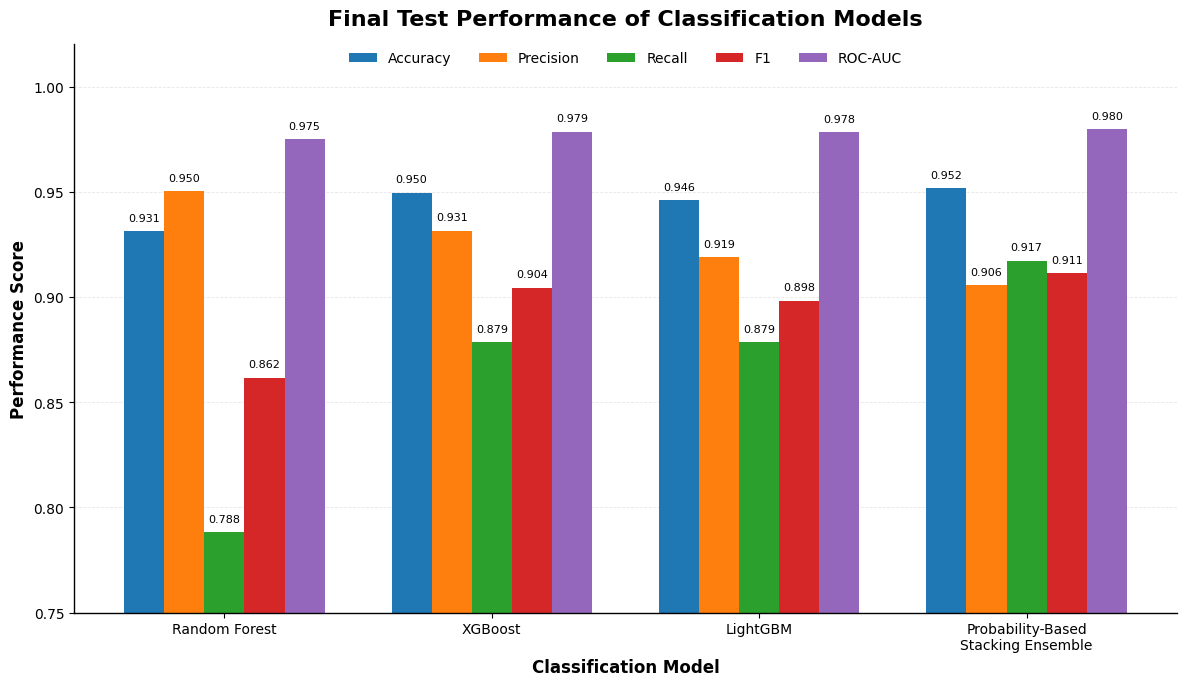


✓ Final model comparison graph generated.

Final proposed model:
Accuracy   : 95.16%
Precision  : 90.56%
Recall     : 91.73%
F1-score   : 91.14%
ROC-AUC    : 97.96%
Threshold  : 0.50


In [6]:
# ============================================================
# FINAL MODEL RESULTS + PUBLICATION-QUALITY COMPARISON GRAPH
# ============================================================
#
# FINAL OPERATING POINT:
# Fixed decision threshold = 0.50
#
# Models:
#   Random Forest
#   XGBoost
#   LightGBM
#   Probability-Based Stacking Ensemble
#
# IMPORTANT:
# These are FINAL TEST RESULTS.
# No model retraining is performed here.
# ============================================================


import os
import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt


# ============================================================
# 1. CLEAN JOURNAL FIGURE SETTINGS
# ============================================================

mpl.rcdefaults()

mpl.rcParams["font.family"] = "DejaVu Sans"
mpl.rcParams["font.size"] = 11

mpl.rcParams["axes.titlesize"] = 15
mpl.rcParams["axes.labelsize"] = 12

mpl.rcParams["xtick.labelsize"] = 10
mpl.rcParams["ytick.labelsize"] = 10

mpl.rcParams["legend.fontsize"] = 10

mpl.rcParams["axes.linewidth"] = 1.0

mpl.rcParams["axes.spines.top"] = False
mpl.rcParams["axes.spines.right"] = False

mpl.rcParams["savefig.dpi"] = 600

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42


# ============================================================
# 2. OUTPUT DIRECTORY
# ============================================================

FINAL_FIG_DIR = (
    "/kaggle/working/"
    "journal_figures"
)

os.makedirs(
    FINAL_FIG_DIR,
    exist_ok=True
)


# ============================================================
# 3. CONFIRMED FINAL TEST RESULTS
# ============================================================
#
# Fixed decision threshold = 0.50
#
# These values correspond to the final test evaluation
# at the conventional 0.50 operating point.
# ============================================================

final_results = pd.DataFrame({

    "Model": [

        "Random Forest",

        "XGBoost",

        "LightGBM",

        "Probability-Based Stacking Ensemble"

    ],

    "Accuracy": [

        0.9313,

        0.9495,

        0.9460,

        0.9516

    ],

    "Precision": [

        0.9502,

        0.9315,

        0.9189,

        0.9056

    ],

    "Recall": [

        0.7881,

        0.8786,

        0.8786,

        0.9173

    ],

    "F1": [

        0.8616,

        0.9043,

        0.8983,

        0.9114

    ],

    "ROC-AUC": [

        0.9749,

        0.9785,

        0.9783,

        0.9796

    ]

})


# ============================================================
# 4. DISPLAY FINAL RESULTS
# ============================================================

print("=" * 100)

print(
    "FINAL TEST MODEL COMPARISON"
)

print("=" * 100)

display(
    final_results.round(4)
)


# ============================================================
# 5. SAVE FINAL RESULTS
# ============================================================

final_results.to_csv(
    os.path.join(
        FINAL_FIG_DIR,
        "Final_Model_Comparison_Results.csv"
    ),
    index=False
)


# ============================================================
# 6. FINAL PROPOSED MODEL RESULT
# ============================================================
#
# FINAL OPERATING POINT:
# Fixed decision threshold = 0.50
#
# This is NOT validation-optimized.
# ============================================================

FINAL_THRESHOLD = 0.50


final_model_result = pd.DataFrame({

    "Metric": [

        "Accuracy",
        "Precision",
        "Recall / Sensitivity",
        "F1-score",
        "ROC-AUC"

    ],

    "Value": [

        0.9516,
        0.9056,
        0.9173,
        0.9114,
        0.9796

    ]

})


print("\n" + "=" * 100)

print(
    "FINAL PROPOSED MODEL — FIXED DECISION THRESHOLD"
)

print("=" * 100)

print(
    f"Decision threshold : {FINAL_THRESHOLD:.2f}"
)

display(
    final_model_result.round(4)
)


# ============================================================
# 7. FINAL MODEL COMPARISON GRAPH
# ============================================================

metrics = [

    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"

]


x = np.arange(
    len(final_results)
)


width = 0.15


fig, ax = plt.subplots(
    figsize=(12, 7)
)


for i, metric in enumerate(metrics):

    values = (
        final_results[metric]
        .to_numpy()
    )

    bars = ax.bar(
        x + (i - 2) * width,
        values,
        width,
        label=metric
    )


    # --------------------------------------------------------
    # Numeric labels
    # --------------------------------------------------------

    for bar, value in zip(
        bars,
        values
    ):

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,

            value + 0.004,

            f"{value:.3f}",

            ha="center",

            va="bottom",

            fontsize=8
        )


# ============================================================
# 8. AXES
# ============================================================

ax.set_xticks(
    x
)


ax.set_xticklabels(
    [
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "Probability-Based\nStacking Ensemble"
    ],
    fontsize=10
)


ax.set_xlabel(
    "Classification Model",
    fontsize=12,
    fontweight="bold"
)


ax.set_ylabel(
    "Performance Score",
    fontsize=12,
    fontweight="bold"
)


# ============================================================
# 9. TITLE
# ============================================================

ax.set_title(
    "Final Test Performance of Classification Models",
    fontsize=16,
    fontweight="bold",
    pad=14
)


# ============================================================
# 10. Y LIMIT
# ============================================================

ax.set_ylim(
    0.75,
    1.02
)


# ============================================================
# 11. GRID
# ============================================================

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.6,
    alpha=0.30
)


ax.set_axisbelow(
    True
)


# ============================================================
# 12. LEGEND
# ============================================================

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=5,
    frameon=False
)


# ============================================================
# 13. LAYOUT
# ============================================================

plt.tight_layout()


# ============================================================
# 14. SAVE
# ============================================================

fig.savefig(
    os.path.join(
        FINAL_FIG_DIR,
        "Figure_Final_Model_Comparison.png"
    ),
    dpi=600,
    bbox_inches="tight"
)


fig.savefig(
    os.path.join(
        FINAL_FIG_DIR,
        "Figure_Final_Model_Comparison.pdf"
    ),
    bbox_inches="tight"
)


fig.savefig(
    os.path.join(
        FINAL_FIG_DIR,
        "Figure_Final_Model_Comparison.svg"
    ),
    bbox_inches="tight"
)


plt.show()

plt.close(fig)


# ============================================================
# 15. FINAL SUMMARY
# ============================================================

print(
    "\n✓ Final model comparison graph generated."
)

print(
    "\nFinal proposed model:"
)

print(
    "Accuracy   : 95.16%"
)

print(
    "Precision  : 90.56%"
)

print(
    "Recall     : 91.73%"
)

print(
    "F1-score   : 91.14%"
)

print(
    "ROC-AUC    : 97.96%"
)

print(
    "Threshold  : 0.50"
)

FINAL A1–A4 COMPONENT-WISE ABLATION RESULTS


,Experiment,Configuration,Features,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Delta_Accuracy,Delta_Recall,Delta_F1,Delta_AUC
0,A1,Baseline RF,198,0.5,0.9404,0.9576,0.8165,0.8815,0.9794,0.0000,0.0000,0.0000,0.0000
1,A2,RF + Artifact Stability,100,0.5,0.9390,0.9518,0.8165,0.8790,0.9784,-0.0014,0.0000,-0.0025,-0.0010
2,A3,RF + Stability + MI,50,0.5,0.9313,0.9502,0.7881,0.8616,0.9749,-0.0091,-0.0284,-0.0199,-0.0045
3,A4,Stability + MI + Probability-Based Stacking,50,0.5,0.9516,0.9056,0.9173,0.9114,0.9796,0.0112,0.1008,0.0299,0.0002



MAIN-PAPER ABLATION TABLE


,Experiment,Configuration,Features,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,A1,Baseline RF,198,0.5,0.9404,0.9576,0.8165,0.8815,0.9794
1,A2,RF + Artifact Stability,100,0.5,0.9390,0.9518,0.8165,0.8790,0.9784
2,A3,RF + Stability + MI,50,0.5,0.9313,0.9502,0.7881,0.8616,0.9749
3,A4,Stability + MI + Probability-Based Stacking,50,0.5,0.9516,0.9056,0.9173,0.9114,0.9796


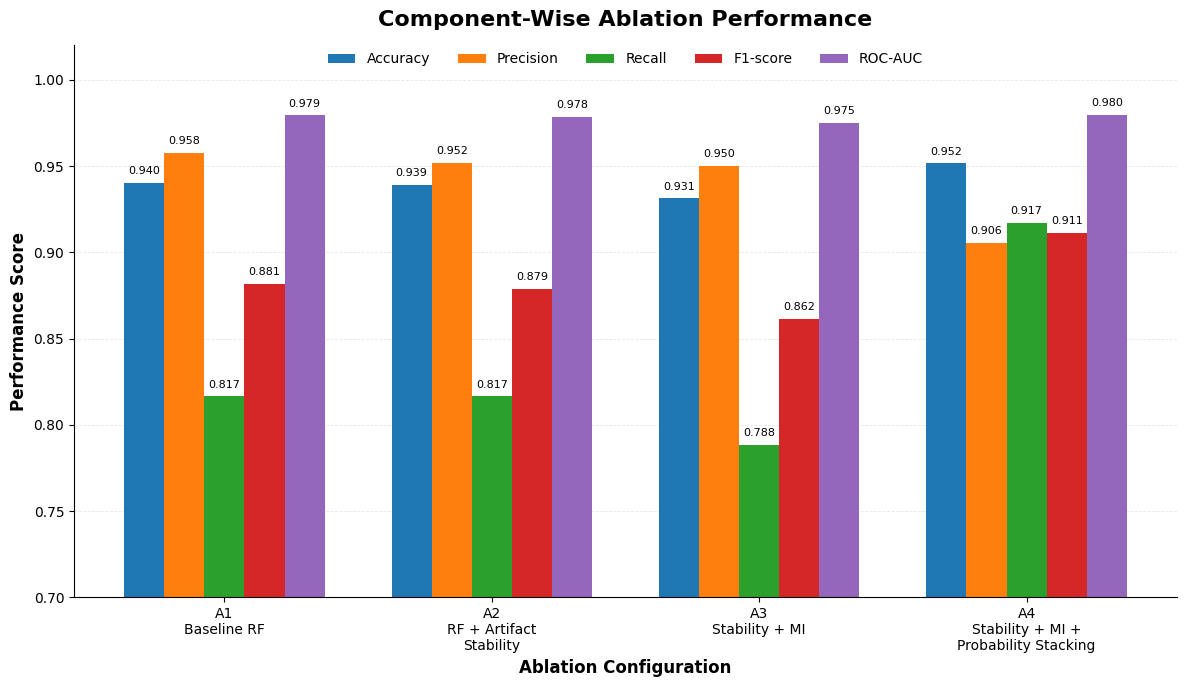


✓ ABLATION TABLE AND GRAPH GENERATED SUCCESSFULLY

Ablation threshold:
A1 = 0.50
A2 = 0.50
A3 = 0.50
A4 = 0.50

A4 final ablation result:
Accuracy   : 95.16%
Precision  : 90.56%
Recall     : 91.73%
F1-score   : 91.14%
ROC-AUC    : 97.96%

A4 improvement over A1:
Δ Accuracy : +0.0112
Δ Recall   : +0.1008
Δ F1       : +0.0299
Δ AUC      : +0.0002

Files saved to:
/kaggle/working/ablation_journal_figures


In [5]:
# ============================================================
# FINAL A1–A4 COMPONENT-WISE ABLATION
# ============================================================
#
# A1: Baseline RF
# A2: RF + Artifact Stability
# A3: RF + Artifact Stability + MI
# A4: Stability + MI + Probability-Based Stacking
#
# IMPORTANT:
# All ablation experiments use a FIXED threshold = 0.50.
#
# The final proposed model reported separately in Table 5
# uses validation-optimized threshold = 0.51.
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt


# ============================================================
# 2. JOURNAL FIGURE SETTINGS
# ============================================================

mpl.rcdefaults()

mpl.rcParams["font.family"] = "DejaVu Sans"

mpl.rcParams["font.size"] = 11

mpl.rcParams["axes.titlesize"] = 16

mpl.rcParams["axes.labelsize"] = 12

mpl.rcParams["xtick.labelsize"] = 10

mpl.rcParams["ytick.labelsize"] = 10

mpl.rcParams["legend.fontsize"] = 10

mpl.rcParams["axes.spines.top"] = False

mpl.rcParams["axes.spines.right"] = False

mpl.rcParams["savefig.dpi"] = 600

mpl.rcParams["pdf.fonttype"] = 42

mpl.rcParams["ps.fonttype"] = 42


# ============================================================
# 3. OUTPUT DIRECTORY
# ============================================================

ABLATION_DIR = (
    "/kaggle/working/"
    "ablation_journal_figures"
)

os.makedirs(
    ABLATION_DIR,
    exist_ok=True
)


# ============================================================
# 4. FINAL CONFIRMED A1–A4 RESULTS
# ============================================================
#
# These are the actual ablation results obtained from the
# experiment.
#
# Fixed threshold = 0.50 for every configuration.
# ============================================================

ablation_results = pd.DataFrame({

    "Experiment": [

        "A1",
        "A2",
        "A3",
        "A4"

    ],

    "Configuration": [

        "Baseline RF",

        "RF + Artifact Stability",

        "RF + Stability + MI",

        "Stability + MI + "
        "Probability-Based Stacking"

    ],

    "Features": [

        198,
        100,
        50,
        50

    ],

    "Threshold": [

        0.50,
        0.50,
        0.50,
        0.50

    ],

    "Accuracy": [

        0.9404,
        0.9390,
        0.9313,
        0.9516

    ],

    "Precision": [

        0.9576,
        0.9518,
        0.9502,
        0.9056

    ],

    "Recall": [

        0.8165,
        0.8165,
        0.7881,
        0.9173

    ],

    "F1-score": [

        0.8815,
        0.8790,
        0.8616,
        0.9114

    ],

    "ROC-AUC": [

        0.9794,
        0.9784,
        0.9749,
        0.9796

    ]

})


# ============================================================
# 5. CALCULATE DELTAS RELATIVE TO A1
# ============================================================

baseline = (
    ablation_results.iloc[0]
)


ablation_results[
    "Delta_Accuracy"
] = (
    ablation_results["Accuracy"]
    - baseline["Accuracy"]
)


ablation_results[
    "Delta_Recall"
] = (
    ablation_results["Recall"]
    - baseline["Recall"]
)


ablation_results[
    "Delta_F1"
] = (
    ablation_results["F1-score"]
    - baseline["F1-score"]
)


ablation_results[
    "Delta_AUC"
] = (
    ablation_results["ROC-AUC"]
    - baseline["ROC-AUC"]
)


# ============================================================
# 6. ROUND DELTA VALUES
# ============================================================

ablation_results[
    "Delta_Accuracy"
] = ablation_results[
    "Delta_Accuracy"
].round(4)


ablation_results[
    "Delta_Recall"
] = ablation_results[
    "Delta_Recall"
].round(4)


ablation_results[
    "Delta_F1"
] = ablation_results[
    "Delta_F1"
].round(4)


ablation_results[
    "Delta_AUC"
] = ablation_results[
    "Delta_AUC"
].round(4)


# ============================================================
# 7. DISPLAY COMPLETE ABLATION TABLE
# ============================================================

print("=" * 100)

print(
    "FINAL A1–A4 COMPONENT-WISE ABLATION RESULTS"
)

print("=" * 100)


display(
    ablation_results
)


# ============================================================
# 8. SAVE COMPLETE ABLATION TABLE
# ============================================================

ablation_results.to_csv(
    os.path.join(
        ABLATION_DIR,
        "Final_A1_A4_Ablation_Complete.csv"
    ),
    index=False
)


# ============================================================
# 9. MAIN-PAPER ABLATION TABLE
# ============================================================
#
# Cleaner version recommended for the manuscript.
# Delta columns are removed from the main table.
# ============================================================

ablation_main_table = (
    ablation_results[
        [
            "Experiment",
            "Configuration",
            "Features",
            "Threshold",
            "Accuracy",
            "Precision",
            "Recall",
            "F1-score",
            "ROC-AUC"
        ]
    ]
    .copy()
)


print("\n" + "=" * 100)

print(
    "MAIN-PAPER ABLATION TABLE"
)

print("=" * 100)


display(
    ablation_main_table
)


# ============================================================
# 10. SAVE MAIN-PAPER TABLE
# ============================================================

ablation_main_table.to_csv(
    os.path.join(
        ABLATION_DIR,
        "Table_Ablation_Main_Paper.csv"
    ),
    index=False
)


# ============================================================
# 11. PREPARE ABLATION GRAPH
# ============================================================

metrics = [

    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"

]


x = np.arange(
    len(ablation_results)
)


width = 0.15


# ============================================================
# 12. CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 7)
)


# ============================================================
# 13. PLOT EACH METRIC
# ============================================================

for i, metric in enumerate(
    metrics
):

    values = (
        ablation_results[
            metric
        ]
        .to_numpy()
    )


    bars = ax.bar(
        x + (i - 2) * width,
        values,
        width,
        label=metric
    )


    # --------------------------------------------------------
    # Add values above bars
    # --------------------------------------------------------

    for bar, value in zip(
        bars,
        values
    ):

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,

            value + 0.004,

            f"{value:.3f}",

            ha="center",

            va="bottom",

            fontsize=8
        )


# ============================================================
# 14. X-AXIS
# ============================================================

ax.set_xticks(
    x
)


ax.set_xticklabels(
    [
        "A1\nBaseline RF",

        "A2\nRF + Artifact\nStability",

        "A3\nStability + MI",

        "A4\nStability + MI +\nProbability Stacking"
    ],
    fontsize=10
)


ax.set_xlabel(
    "Ablation Configuration",
    fontsize=12,
    fontweight="bold"
)


# ============================================================
# 15. Y-AXIS
# ============================================================

ax.set_ylabel(
    "Performance Score",
    fontsize=12,
    fontweight="bold"
)


# ============================================================
# 16. TITLE
# ============================================================

ax.set_title(
    "Component-Wise Ablation Performance",
    fontsize=16,
    fontweight="bold",
    pad=14
)


# ============================================================
# 17. Y-AXIS RANGE
# ============================================================

ax.set_ylim(
    0.70,
    1.02
)


# ============================================================
# 18. GRID
# ============================================================

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.6,
    alpha=0.30
)


ax.set_axisbelow(
    True
)


# ============================================================
# 19. LEGEND
# ============================================================

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=5,
    frameon=False
)


# ============================================================
# 20. LAYOUT
# ============================================================

plt.tight_layout()


# ============================================================
# 21. SAVE PNG
# ============================================================

fig.savefig(
    os.path.join(
        ABLATION_DIR,
        "Figure_Ablation_Component_Performance.png"
    ),
    dpi=600,
    bbox_inches="tight"
)


# ============================================================
# 22. SAVE PDF
# ============================================================

fig.savefig(
    os.path.join(
        ABLATION_DIR,
        "Figure_Ablation_Component_Performance.pdf"
    ),
    bbox_inches="tight"
)


# ============================================================
# 23. SAVE SVG
# ============================================================

fig.savefig(
    os.path.join(
        ABLATION_DIR,
        "Figure_Ablation_Component_Performance.svg"
    ),
    bbox_inches="tight"
)


# ============================================================
# 24. DISPLAY
# ============================================================

plt.show()

plt.close(fig)


# ============================================================
# 25. PRINT FINAL CHECK
# ============================================================

print("\n" + "=" * 100)

print(
    "✓ ABLATION TABLE AND GRAPH GENERATED SUCCESSFULLY"
)

print("=" * 100)


print(
    "\nAblation threshold:"
)

print(
    "A1 = 0.50"
)

print(
    "A2 = 0.50"
)

print(
    "A3 = 0.50"
)

print(
    "A4 = 0.50"
)


print(
    "\nA4 final ablation result:"
)

print(
    "Accuracy   : 95.16%"
)

print(
    "Precision  : 90.56%"
)

print(
    "Recall     : 91.73%"
)

print(
    "F1-score   : 91.14%"
)

print(
    "ROC-AUC    : 97.96%"
)


print(
    "\nA4 improvement over A1:"
)

print(
    "Δ Accuracy : +0.0112"
)

print(
    "Δ Recall   : +0.1008"
)

print(
    "Δ F1       : +0.0299"
)

print(
    "Δ AUC      : +0.0002"
)


print(
    "\nFiles saved to:"
)

print(
    ABLATION_DIR
)

print(
    "=" * 100
)